# Firmware Network Trace Analysis

In [1]:
import sys
!{sys.executable} -m pip install dpkt pandas tqdm pyarrow tqdm

In [2]:
# CONFIGURATION
import dpkt
import socket
import pandas as pd
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
if not os.path.exists(BASE_DIR):
    raise FileNotFoundError(f"{BASE_DIR} does not exist")
DATA_DIR = os.path.join(BASE_DIR, 'data')
DATASET_DIR = os.path.join(DATA_DIR, '02_octopus')
EMULATOR_OUT_DIR = os.path.join(DATASET_DIR, 'emulator_out')


In [3]:
# 1. Use a verified built-in clean white style
if 'seaborn-v0_8-white' in plt.style.available:
    plt.style.use('seaborn-v0_8-white')
else:
    plt.style.use('default') # Fallback safely if versioning differs

# 2. Explicitly lock the parameters to solid white (override IDE dark themes)
plt.rcParams['figure.facecolor']  = 'white'  # Outer frame canvas
plt.rcParams['axes.facecolor']    = 'white'  # Inner plot canvas
plt.rcParams['savefig.facecolor'] = 'white'  # Saved image/PDF background

# Pre-Processing Network Logs

In [4]:
import dpkt
import socket
import pandas as pd
import os
import struct
from tqdm.auto import tqdm

def pcap_to_df_default(filepath, firmware_id):
    data = []
    stats = {'total': 0, 'ip_found': 0}

    with open(filepath, 'rb') as f:
        # 1. Detect PCAP vs PCAPNG
        file_magic = f.read(4)
        f.seek(0)
        try:
            if file_magic == b'\x0a\x0d\x0d\x0a':
                reader = dpkt.pcapng.Reader(f)
            else:
                reader = dpkt.pcap.Reader(f)
        except Exception as e:
            print(f"Error opening {filepath}: {e}")
            return pd.DataFrame()

        try:
            for ts, buf in reader:
                stats['total'] += 1
                extracted = False

                # 2. Iterate through common datalink offsets
                for offset in [0, 4, 14, 16, 18, 20]:
                    if len(buf) < offset + 20:
                        continue

                    version = buf[offset] >> 4
                    ip_buf = buf[offset:]

                    src, dst, src_port, dst_port = None, None, None, None
                    proto_name = None

                    # --- IPv4 Byte Slicing (Bypasses dpkt validation) ---
                    if version == 4 and len(ip_buf) >= 20:
                        src = socket.inet_ntoa(ip_buf[12:16])
                        dst = socket.inet_ntoa(ip_buf[16:20])
                        proto_num = ip_buf[9]

                        ihl = (ip_buf[0] & 0x0F) * 4

                        proto_name = f'Other ({proto_num})'
                        if proto_num == 6 and len(ip_buf) >= ihl + 4: # TCP
                            proto_name = 'TCP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')
                        elif proto_num == 17 and len(ip_buf) >= ihl + 4: # UDP
                            proto_name = 'UDP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')

                        extracted = True

                    # --- IPv6 Byte Slicing ---
                    elif version == 6 and len(ip_buf) >= 40:
                        src = socket.inet_ntop(socket.AF_INET6, ip_buf[8:24])
                        dst = socket.inet_ntop(socket.AF_INET6, ip_buf[24:40])
                        proto_num = ip_buf[6]

                        ihl = 40

                        proto_name = f'Other ({proto_num})'
                        if proto_num == 6 and len(ip_buf) >= ihl + 4: # TCP
                            proto_name = 'TCP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')
                        elif proto_num == 17 and len(ip_buf) >= ihl + 4: # UDP
                            proto_name = 'UDP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')

                        extracted = True

                    if extracted:
                        data.append({
                            'timestamp': ts,
                            'firmware_id': firmware_id,
                            'src_ip': src,
                            'dst_ip': dst,
                            'src_port': src_port,
                            'dst_port': dst_port,
                            'protocol': proto_name,
                            'length': len(buf)
                        })
                        stats['ip_found'] += 1
                        break

        except Exception:
            pass

    print(f"Finished {os.path.basename(filepath)}: {stats['total']} pkts, {stats['ip_found']} IPs found")
    return pd.DataFrame(data)


# NFLOG Constants
NFLOG_TLV_HEADER_SIZE = 4
NFULA_PAYLOAD = 9
NFULA_UID = 11

def parse_nflog_tlvs(buf):
    """
    Parses the NFLOG TLVs from the buffer.
    Returns the UID (if found) and the raw IP payload.
    """
    # The NFLOG header is 4 bytes: Family (1 byte), Version (1 byte), Res_ID (2 bytes)
    # Family 2 = IPv4, 10 = IPv6
    if len(buf) < 4:
        return None, None

    offset = 4
    uid = None
    ip_payload = None

    # Iterate through the TLVs
    while offset + NFLOG_TLV_HEADER_SIZE <= len(buf):
        # TLV Header: Length (2 bytes), Type (2 bytes)
        tlv_len, tlv_type = struct.unpack('<HH', buf[offset:offset+4])

        # Ensure we don't enter an infinite loop if the length is corrupted
        if tlv_len < NFLOG_TLV_HEADER_SIZE:
            break

        value_offset = offset + NFLOG_TLV_HEADER_SIZE
        value_len = tlv_len - NFLOG_TLV_HEADER_SIZE

        # Make sure we don't read past the buffer
        if value_offset + value_len > len(buf):
            break

        # Extract UID (Type 11)
        if tlv_type == NFULA_UID and value_len == 4:
            uid = struct.unpack('>I', buf[value_offset:value_offset+4])[0]

        # Extract Payload (Type 9)
        elif tlv_type == NFULA_PAYLOAD:
            ip_payload = buf[value_offset:value_offset+value_len]

        # Move to the next TLV (TLVs are aligned to 4-byte boundaries)
        padded_len = (tlv_len + 3) & ~3
        offset += padded_len

    return uid, ip_payload


def pcap_to_df(filepath, firmware_id):
    data = []
    stats = {'total': 0, 'ip_found': 0, 'uid_found': 0}

    with open(filepath, 'rb') as f:
        file_magic = f.read(4)
        f.seek(0)
        try:
            if file_magic == b'\x0a\x0d\x0d\x0a':
                reader = dpkt.pcapng.Reader(f)
            else:
                reader = dpkt.pcap.Reader(f)
        except Exception as e:
            print(f"Error opening {filepath}: {e}")
            return pd.DataFrame()

        try:
            for ts, buf in reader:
                stats['total'] += 1

                # 1. Parse the NFLOG Header to get the IP Payload and UID
                uid, ip_buf = parse_nflog_tlvs(buf)

                if uid is not None:
                    stats['uid_found'] += 1

                if not ip_buf or len(ip_buf) < 20:
                    continue

                version = ip_buf[0] >> 4

                src, dst, src_port, dst_port = None, None, None, None
                proto_name = None
                extracted = False

                # 2. IP Byte Slicing (Same as before, but using the clean ip_buf)
                # --- IPv4 Validation & Slicing ---
                if version == 4:
                    ihl = (ip_buf[0] & 0x0F) * 4

                    if ihl >= 20 and len(ip_buf) >= ihl:
                        src = socket.inet_ntoa(ip_buf[12:16])
                        dst = socket.inet_ntoa(ip_buf[16:20])
                        proto_num = ip_buf[9]

                        proto_name = f'Other ({proto_num})'
                        if proto_num == 6 and len(ip_buf) >= ihl + 4: # TCP
                            proto_name = 'TCP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')
                        elif proto_num == 17 and len(ip_buf) >= ihl + 4: # UDP
                            proto_name = 'UDP'
                            src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                            dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')

                        extracted = True

                # --- IPv6 Validation & Slicing ---
                elif version == 6 and len(ip_buf) >= 40:
                    src = socket.inet_ntop(socket.AF_INET6, ip_buf[8:24])
                    dst = socket.inet_ntop(socket.AF_INET6, ip_buf[24:40])
                    proto_num = ip_buf[6]
                    ihl = 40

                    proto_name = f'Other ({proto_num})'
                    if proto_num == 6 and len(ip_buf) >= ihl + 4: # TCP
                        proto_name = 'TCP'
                        src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                        dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')
                    elif proto_num == 17 and len(ip_buf) >= ihl + 4: # UDP
                        proto_name = 'UDP'
                        src_port = int.from_bytes(ip_buf[ihl:ihl+2], 'big')
                        dst_port = int.from_bytes(ip_buf[ihl+2:ihl+4], 'big')

                    extracted = True

                if extracted:
                    data.append({
                        'timestamp': ts,
                        'firmware_id': firmware_id,
                        'uid': uid,          # <--- Added UID to output
                        'src_ip': src,
                        'dst_ip': dst,
                        'src_port': src_port,
                        'dst_port': dst_port,
                        'protocol': proto_name,
                        'length': len(ip_buf)
                    })
                    stats['ip_found'] += 1

        except Exception as e:
            pass

    print(f"Finished {os.path.basename(filepath)}: {stats['total']} pkts, {stats['ip_found']} IPs, {stats['uid_found']} UIDs")
    return pd.DataFrame(data)


# --- Loop Section ---
all_dfs = []

fw_folders = [d for d in os.listdir(EMULATOR_OUT_DIR) if os.path.isdir(os.path.join(EMULATOR_OUT_DIR, d))]

for fw_folder in tqdm(fw_folders, desc="Processing Firmware"):
    fw_path = os.path.join(EMULATOR_OUT_DIR, fw_folder)

    pcaps_to_process = []

    # 1. Priority check: Look in the 'ecapture' folder first
    ecapture_dir = os.path.join(fw_path, 'ecapture')
    priority_files = ['eth0.pcapng', 'wlan0.pcapng']

    for filename in priority_files:
        filepath = os.path.join(ecapture_dir, filename)
        # Check if the file exists and is strictly greater than 0 bytes
        if os.path.isfile(filepath) and os.path.getsize(filepath) > 0:
            pcaps_to_process.append(filepath)

    # 2. Fallback check: If priority files are missing or empty, search 'pcaps' folder
    if not pcaps_to_process:
        pcaps_dir = os.path.join(fw_path, 'pcaps')

        largest_pcap = None
        max_size = 0 # Must be strictly greater than 0 bytes to be considered

        if os.path.isdir(pcaps_dir):
            for root, dirs, files in os.walk(pcaps_dir):
                for file in files:
                    if file.endswith('.pcap') or file.endswith('.pcapng'):
                        filepath = os.path.join(root, file)
                        try:
                            file_size = os.path.getsize(filepath)
                            if file_size > max_size:
                                max_size = file_size
                                largest_pcap = filepath
                        except OSError:
                            continue

        if largest_pcap:
            pcaps_to_process.append(largest_pcap)

    # 3. Process the selected PCAP(s) for this firmware
    for pcap_file in pcaps_to_process:
        df_temp = pcap_to_df(pcap_file, fw_folder)
        if not df_temp.empty:
            all_dfs.append(df_temp)

if all_dfs:
    final_df = pd.concat(all_dfs, ignore_index=True)
    print(f"Success! Final shape: {final_df.shape}")
else:
    print("Warning: all_dfs is still empty.")

/Users/tom/Documents/02_INIT/06_Sand/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Processing Firmware:   0%|          | 0/290 [00:00<?, ?it/s]

Finished tcpdump_emulator-5556.pcap: 6736 pkts, 6736 IPs, 4846 UIDs


Processing Firmware:   2%|▏         | 5/290 [00:00<00:14, 19.19it/s]

Finished tcpdump_emulator-5556.pcap: 6656 pkts, 6656 IPs, 4910 UIDs
Finished tcpdump_emulator-5556.pcap: 6550 pkts, 6550 IPs, 4860 UIDs
Finished tcpdump_emulator-5556.pcap: 6596 pkts, 6596 IPs, 4796 UIDs
Finished tcpdump_emulator-5556.pcap: 6380 pkts, 6380 IPs, 4780 UIDs
Finished tcpdump_emulator-5556.pcap: 6346 pkts, 6346 IPs, 4756 UIDs


Processing Firmware:   2%|▏         | 7/290 [00:01<01:05,  4.31it/s]

Finished tcpdump_emulator-5556.pcap: 138393 pkts, 138393 IPs, 137857 UIDs
Finished tcpdump_emulator-5556.pcap: 6370 pkts, 6370 IPs, 4780 UIDs
Finished tcpdump_emulator-5556.pcap: 288 pkts, 288 IPs, 240 UIDs
Finished tcpdump_emulator-5556.pcap: 2492 pkts, 2492 IPs, 1868 UIDs


... (134 outputs left out)

Processing Firmware:  99%|█████████▉| 287/290 [00:44<00:01,  2.18it/s]

Finished tcpdump_emulator-5556.pcap: 168461 pkts, 168461 IPs, 167416 UIDs
Finished tcpdump_emulator-5556.pcap: 6390 pkts, 6390 IPs, 4790 UIDs
Finished tcpdump_emulator-5556.pcap: 6526 pkts, 6526 IPs, 4836 UIDs
Finished tcpdump_emulator-5556.pcap: 3337 pkts, 3337 IPs, 3275 UIDs
Finished tcpdump_emulator-5556.pcap: 267528 pkts, 267528 IPs, 265590 UIDs


Processing Firmware: 100%|██████████| 290/290 [00:46<00:00,  6.21it/s]


Success! Final shape: (6677630, 9)


In [5]:
final_df.head()

,timestamp,firmware_id,uid,src_ip,dst_ip,src_port,dst_port,protocol,length
0,1.786567e+09,68afd6e865e2ad36cf1c1b8a_v12_sdk_phone64_arm64...,1020.0,10.0.2.15,224.0.0.251,5353.0,5353.0,UDP,527
1,1.786567e+09,68afd6e865e2ad36cf1c1b8a_v12_sdk_phone64_arm64...,1020.0,10.0.2.15,224.0.0.251,5353.0,5353.0,UDP,527
2,1.786567e+09,68afd6e865e2ad36cf1c1b8a_v12_sdk_phone64_arm64...,1020.0,10.0.2.15,224.0.0.251,5353.0,5353.0,UDP,527
3,1.786567e+09,68afd6e865e2ad36cf1c1b8a_v12_sdk_phone64_arm64...,1020.0,10.0.2.15,224.0.0.251,5353.0,5353.0,UDP,527
4,1.786567e+09,68afd6e865e2ad36cf1c1b8a_v12_sdk_phone64_arm64...,1020.0,10.0.2.15,224.0.0.251,5353.0,5353.0,UDP,527


In [6]:
count = final_df['firmware_id'].nunique()
print(f"Number of unique firmware ids: {count}")

Number of unique firmware ids: 249


# App Traffic Analysis

In [7]:
import dpkt
import socket
import struct
import re
from tqdm.auto import tqdm

# Regex to catch domain names in raw bytes if dpkt fails to parse the TLS structure
DOMAIN_RE = re.compile(b'(?i)([a-z0-9.-]+\\.[a-z]{2,15})')

def parse_nflog_tlvs(buf):
    if len(buf) < 4: return None, None
    offset = 4
    uid, ip_payload = None, None
    while offset + 4 <= len(buf):
        tlv_len, tlv_type = struct.unpack('<HH', buf[offset:offset+4])
        if tlv_len < 4: break
        value_len, value_offset = tlv_len - 4, offset + 4
        if value_offset + value_len > len(buf): break

        if tlv_type == 11 and value_len == 4:
            uid = struct.unpack('>I', buf[value_offset:value_offset+4])[0]
        elif tlv_type == 9:
            ip_payload = buf[value_offset:value_offset+value_len]

        offset += (tlv_len + 3) & ~3
    return uid, ip_payload

def extract_ip_payload(buf, dlt):
    """Accurately slices the packet based on the exact Data Link Type."""
    if dlt == 239 or dlt == 254: # NFLOG
        return parse_nflog_tlvs(buf)
    elif dlt == 1: # Ethernet (14 byte header)
        if len(buf) > 18 and buf[12:14] == b'\x81\x00': # VLAN tag check
            return None, buf[18:]
        return None, buf[14:]
    elif dlt == 113: # Linux SLL (16 byte header)
        return None, buf[16:]
    elif dlt == 12 or dlt == 101: # Raw IPv4
        return None, buf
    else:
        # Strict fallback
        for offset in range(0, 40, 2):
            if len(buf) > offset + 20 and buf[offset] >> 4 == 4:
                ihl = (buf[offset] & 0x0F) * 4
                total_len = int.from_bytes(buf[offset+2:offset+4], 'big')
                if ihl >= 20 and total_len <= len(buf) - offset:
                    return None, buf[offset:]
        return None, None

def get_real_domains_from_pcap(filepath):
    ip_to_domain = {}
    with open(filepath, 'rb') as f:
        file_magic = f.read(4)
        f.seek(0)
        try:
            reader = dpkt.pcapng.Reader(f) if file_magic == b'\x0a\x0d\x0d\x0a' else dpkt.pcap.Reader(f)
            dlt = reader.datalink()
        except Exception:
            return {}

        try:
            for ts, buf in reader:
                try:
                    _, ip_buf = extract_ip_payload(buf, dlt)
                    if not ip_buf or len(ip_buf) < 20: continue

                    if ip_buf[0] >> 4 == 4: # IPv4
                        ihl = (ip_buf[0] & 0x0F) * 4
                        proto = ip_buf[9]
                        payload = ip_buf[ihl:]

                        # --- 1. DNS UDP Port 53 ---
                        if proto == 17 and len(payload) >= 8:
                            src_port = int.from_bytes(payload[0:2], 'big')
                            if src_port == 53:
                                try:
                                    dns = dpkt.dns.DNS(payload[8:])
                                    if dns.qr == 1:
                                        for answer in dns.an:
                                            if answer.type == 1:
                                                ip_str = socket.inet_ntoa(answer.ip)
                                                ip_to_domain[ip_str] = answer.name
                                except: pass

                        # --- 2. TLS TCP Port 443 ---
                        elif proto == 6 and len(payload) >= 20:
                            dst_port = int.from_bytes(payload[2:4], 'big')
                            tcp_hdr_len = (payload[12] >> 4) * 4
                            tcp_data = payload[tcp_hdr_len:]

                            if dst_port == 443 and len(tcp_data) > 9:
                                dst_ip = socket.inet_ntoa(ip_buf[16:20])
                                # TLS Client Hello signature
                                if tcp_data[0] == 0x16 and tcp_data[5] == 0x01:
                                    extracted = False
                                    try:
                                        # Method A: Use dpkt
                                        tls = dpkt.ssl.TLS(tcp_data)
                                        for record in tls.records:
                                            if isinstance(record.data, dpkt.ssl.TLSHandshake) and isinstance(record.data.data, dpkt.ssl.TLSClientHello):
                                                if hasattr(record.data.data, 'extensions'):
                                                    for ext, ext_data in record.data.data.extensions:
                                                        if ext == 0: # SNI
                                                            ip_to_domain[dst_ip] = ext_data[5:].decode('utf-8', errors='ignore')
                                                            extracted = True
                                    except: pass

                                    # Method B: Raw Byte Fallback if dpkt crashes (common on TLS 1.3)
                                    if not extracted and b'\x00\x00' in tcp_data:
                                        # Simple search for the domain in the SNI block
                                        matches = DOMAIN_RE.findall(tcp_data[40:])
                                        for match in matches:
                                            decoded = match.decode('utf-8', errors='ignore')
                                            # Filter out false positives by ensuring it looks like a valid destination
                                            if '.' in decoded and len(decoded) > 4:
                                                ip_to_domain[dst_ip] = decoded
                                                break
                except Exception:
                    continue

        except (dpkt.dpkt.NeedData, dpkt.dpkt.UnpackError, EOFError, struct.error):
            pass # Handle truncated pcaps gracefully

    return ip_to_domain

# ==========================================
# 1. Build the Master IP-to-Domain Dictionary
# ==========================================
print("Scanning PCAPs for actual requested domains (DNS & TLS SNI)...")
master_ip_domain_map = {}

# (Assuming pcaps_to_process is a list of all your PCAP filepaths from your previous loop)
# If you don't have that list handy, you can loop through EMULATOR_OUT_DIR just like before
# For this example, let's assume we fetch them again:

all_pcaps = []
for fw_folder in fw_folders:
    fw_path = os.path.join(EMULATOR_OUT_DIR, fw_folder)
    ecapture_dir = os.path.join(fw_path, 'ecapture')
    priority_files = ['eth0.pcapng', 'wlan0.pcapng']
    found = False
    for f in priority_files:
        fp = os.path.join(ecapture_dir, f)
        if os.path.isfile(fp) and os.path.getsize(fp) > 0:
            all_pcaps.append(fp)
            found = True
    if not found:
        pcaps_dir = os.path.join(fw_path, 'pcaps')
        largest_pcap, max_size = None, 0
        if os.path.isdir(pcaps_dir):
            for root, dirs, files in os.walk(pcaps_dir):
                for f in files:
                    if f.endswith(('.pcap', '.pcapng')):
                        fp = os.path.join(root, f)
                        try:
                            sz = os.path.getsize(fp)
                            if sz > max_size: max_size, largest_pcap = sz, fp
                        except: pass
        if largest_pcap: all_pcaps.append(largest_pcap)

# Extract mappings from all PCAPs
for pcap in tqdm(all_pcaps, desc="Extracting Domains"):
    local_map = get_real_domains_from_pcap(pcap)
    master_ip_domain_map.update(local_map)

print(f"Successfully extracted {len(master_ip_domain_map)} real domain names!")

# ==========================================
# 2. Apply it to your existing DataFrame (final_df)
# ==========================================
# Map the real domains using our ground-truth dictionary.
# If a domain wasn't found in DNS/SNI, fallback to the raw IP.
final_df['real_domain'] = final_df['dst_ip'].map(master_ip_domain_map).fillna(final_df['dst_ip'])

# 3. Generate the clean Domain -> App_UIDs table
domain_uid_mapping = final_df[['real_domain', 'uid']].dropna().drop_duplicates()
domain_uid_mapping['uid'] = domain_uid_mapping['uid'].astype(int)

final_domain_table = domain_uid_mapping.groupby('real_domain')['uid'].apply(lambda x: sorted(list(set(x)))).reset_index()
final_domain_table.columns = ['Domain', 'App_UIDs']
final_domain_table = final_domain_table.sort_values(by='Domain', ignore_index=True)

print(final_domain_table.head(30))



Scanning PCAPs for actual requested domains (DNS & TLS SNI)...


Extracting Domains: 100%|██████████| 249/249 [00:31<00:00,  7.87it/s]


Successfully extracted 175 real domain names!
             Domain                                           App_UIDs
0          10.0.2.3  [0, 10142, 10146, 10148, 10154, 10159, 10160, ...
1    104.154.125.27                                            [10180]
2   108.177.119.188  [10075, 10076, 10078, 10079, 10087, 10088, 100...
3   108.177.125.188  [10075, 10077, 10078, 10079, 10080, 10087, 100...
4   108.177.127.188  [10070, 10075, 10077, 10078, 10079, 10084, 100...
5    108.177.96.188  [10075, 10077, 10078, 10082, 10086, 10087, 100...
6         127.0.0.1  [0, 10068, 10070, 10073, 10074, 10075, 10076, ...
7   142.250.145.188  [10070, 10075, 10077, 10084, 10089, 10095, 10109]
8   142.250.153.188         [10075, 10078, 10086, 10087, 10095, 10109]
9    142.251.18.188                                     [10087, 10097]
10   142.251.31.188  [10075, 10088, 10089, 10092, 10095, 10108, 10109]
11  172.217.218.188                       [10095, 10101, 10103, 10108]
12  172.217.221.188            

In [8]:
just_domains = final_domain_table[~final_domain_table['Domain'].str.match(r'^\d{1,3}(\.\d{1,3}){3}$')]
print(just_domains.head(30))

                                Domain   
39                    account.live.com  \
40                 accounts.google.com   
41                  ad.doubleclick.net   
42                 admin.microsoft.com   
43                adservice.google.com   
44               alt1-mtalk.google.com   
45               alt2-mtalk.google.com   
46               alt3-mtalk.google.com   
47               alt4-mtalk.google.com   
48          android.clients.google.com   
49              android.googleapis.com   
50                 api.login.yahoo.com   
51                 app-measurement.com   
52   browser.events.data.microsoft.com   
53    cdn.config.centro.core.microsoft   
54                 clients4.google.com   
55       clientservices.googleapis.com   
56                       dl.google.com   
57  dtproxy5.yahoo.nc.clients.ipqs.com   
58                  edgedl.me.gvt1.com   
59                fonts.googleapis.com   
60                   fonts.gstatic.com   
61                        fpt.live

In [9]:
import os
import json
import pandas as pd

def load_package_mappings(emulator_out_dir, fw_folders):
    """
    Scans firmware directories for package_uids_*.json files
    and builds a lookup map keyed by (firmware_id, uid).
    """
    fw_uid_pkg_map = {}

    for fw_folder in fw_folders:
        fw_path = os.path.join(emulator_out_dir, fw_folder)

        # Look for package_uids_emulator-5556.json (or wildcard fallback)
        json_file = None
        target_exact = os.path.join(fw_path, 'package_uids_emulator-5556.json')

        if os.path.isfile(target_exact):
            json_file = target_exact
        else:
            # Fallback if port number varies in some folders
            if os.path.isdir(fw_path):
                for fname in os.listdir(fw_path):
                    if fname.startswith('package_uids_') and fname.endswith('.json'):
                        json_file = os.path.join(fw_path, fname)
                        break

        if json_file and os.path.isfile(json_file):
            try:
                with open(json_file, 'r') as f:
                    data = json.load(f)
                    mapping = data.get('mapping', {})

                    # Invert mapping: UID -> List of Package Names
                    uid_to_pkgs = {}
                    for pkg_name, uid in mapping.items():
                        uid_int = int(uid)
                        if uid_int not in uid_to_pkgs:
                            uid_to_pkgs[uid_int] = []
                        uid_to_pkgs[uid_int].append(pkg_name)

                    # Store as comma-separated string for (firmware_id, uid)
                    for uid_int, pkgs in uid_to_pkgs.items():
                        fw_uid_pkg_map[(fw_folder, uid_int)] = ", ".join(sorted(pkgs))
            except Exception as e:
                print(f"Error reading {json_file}: {e}")
        else:
            print(f"Warning: JSON mapping missing for firmware folder '{fw_folder}'")

    return fw_uid_pkg_map

# ==========================================
# 1. Load Master Package Map
# ==========================================
print("Loading UID-to-Package mappings across all firmwares...")
fw_uid_pkg_map = load_package_mappings(EMULATOR_OUT_DIR, fw_folders)

# ==========================================
# 2. Enrich final_df with Package Names
# ==========================================
# Ensure UID is integer format
final_df['uid'] = final_df['uid'].fillna(-1).astype(int)

# Map (firmware_id, uid) tuple to package name
final_df['package_name'] = final_df.apply(
    lambda row: fw_uid_pkg_map.get((row['firmware_id'], row['uid']), 'UID 0 (OS) - Unknown Package'),
    axis=1
)

matched_count = len(final_df[final_df['package_name'] != 'Unknown / OS'])
print(f"Successfully mapped {matched_count:,} / {len(final_df):,} packets to package names!")

# ==========================================
# 3. Build Domain -> Package Name(s) Table
# ==========================================
# Filter out unresolved raw IP rows if you only want domains
domain_pkg_df = final_df[['real_domain', 'package_name']].dropna().drop_duplicates()

# Group by domain to get all packages communicating with it
domain_to_pkg_table = domain_pkg_df.groupby('real_domain')['package_name'].apply(
    lambda pkgs: sorted(list(set(pkgs)))
).reset_index()

domain_to_pkg_table.columns = ['Domain', 'Package_Names']

# Filter out rows where domain is just a raw IP (optional view)
clean_domain_pkg_table = domain_to_pkg_table[
    ~domain_to_pkg_table['Domain'].str.match(r'^\d{1,3}(\.\d{1,3}){3}$')
].sort_values(by='Domain', ignore_index=True)

print("\n--- Domain to Package Name Mapping Sample ---")
print(clean_domain_pkg_table.head(25))

Loading UID-to-Package mappings across all firmwares...
Successfully mapped 6,677,630 / 6,677,630 packets to package names!

--- Domain to Package Name Mapping Sample ---
                                Domain   
41                    account.live.com  \
42                 accounts.google.com   
43                  ad.doubleclick.net   
44                 admin.microsoft.com   
45                adservice.google.com   
46               alt1-mtalk.google.com   
47               alt2-mtalk.google.com   
48               alt3-mtalk.google.com   
49               alt4-mtalk.google.com   
50          android.clients.google.com   
51              android.googleapis.com   
52                 api.login.yahoo.com   
53                 app-measurement.com   
54   browser.events.data.microsoft.com   
55    cdn.config.centro.core.microsoft   
56                 clients4.google.com   
57       clientservices.googleapis.com   
58                       dl.google.com   
59  dtproxy5.yahoo.nc.clients.i

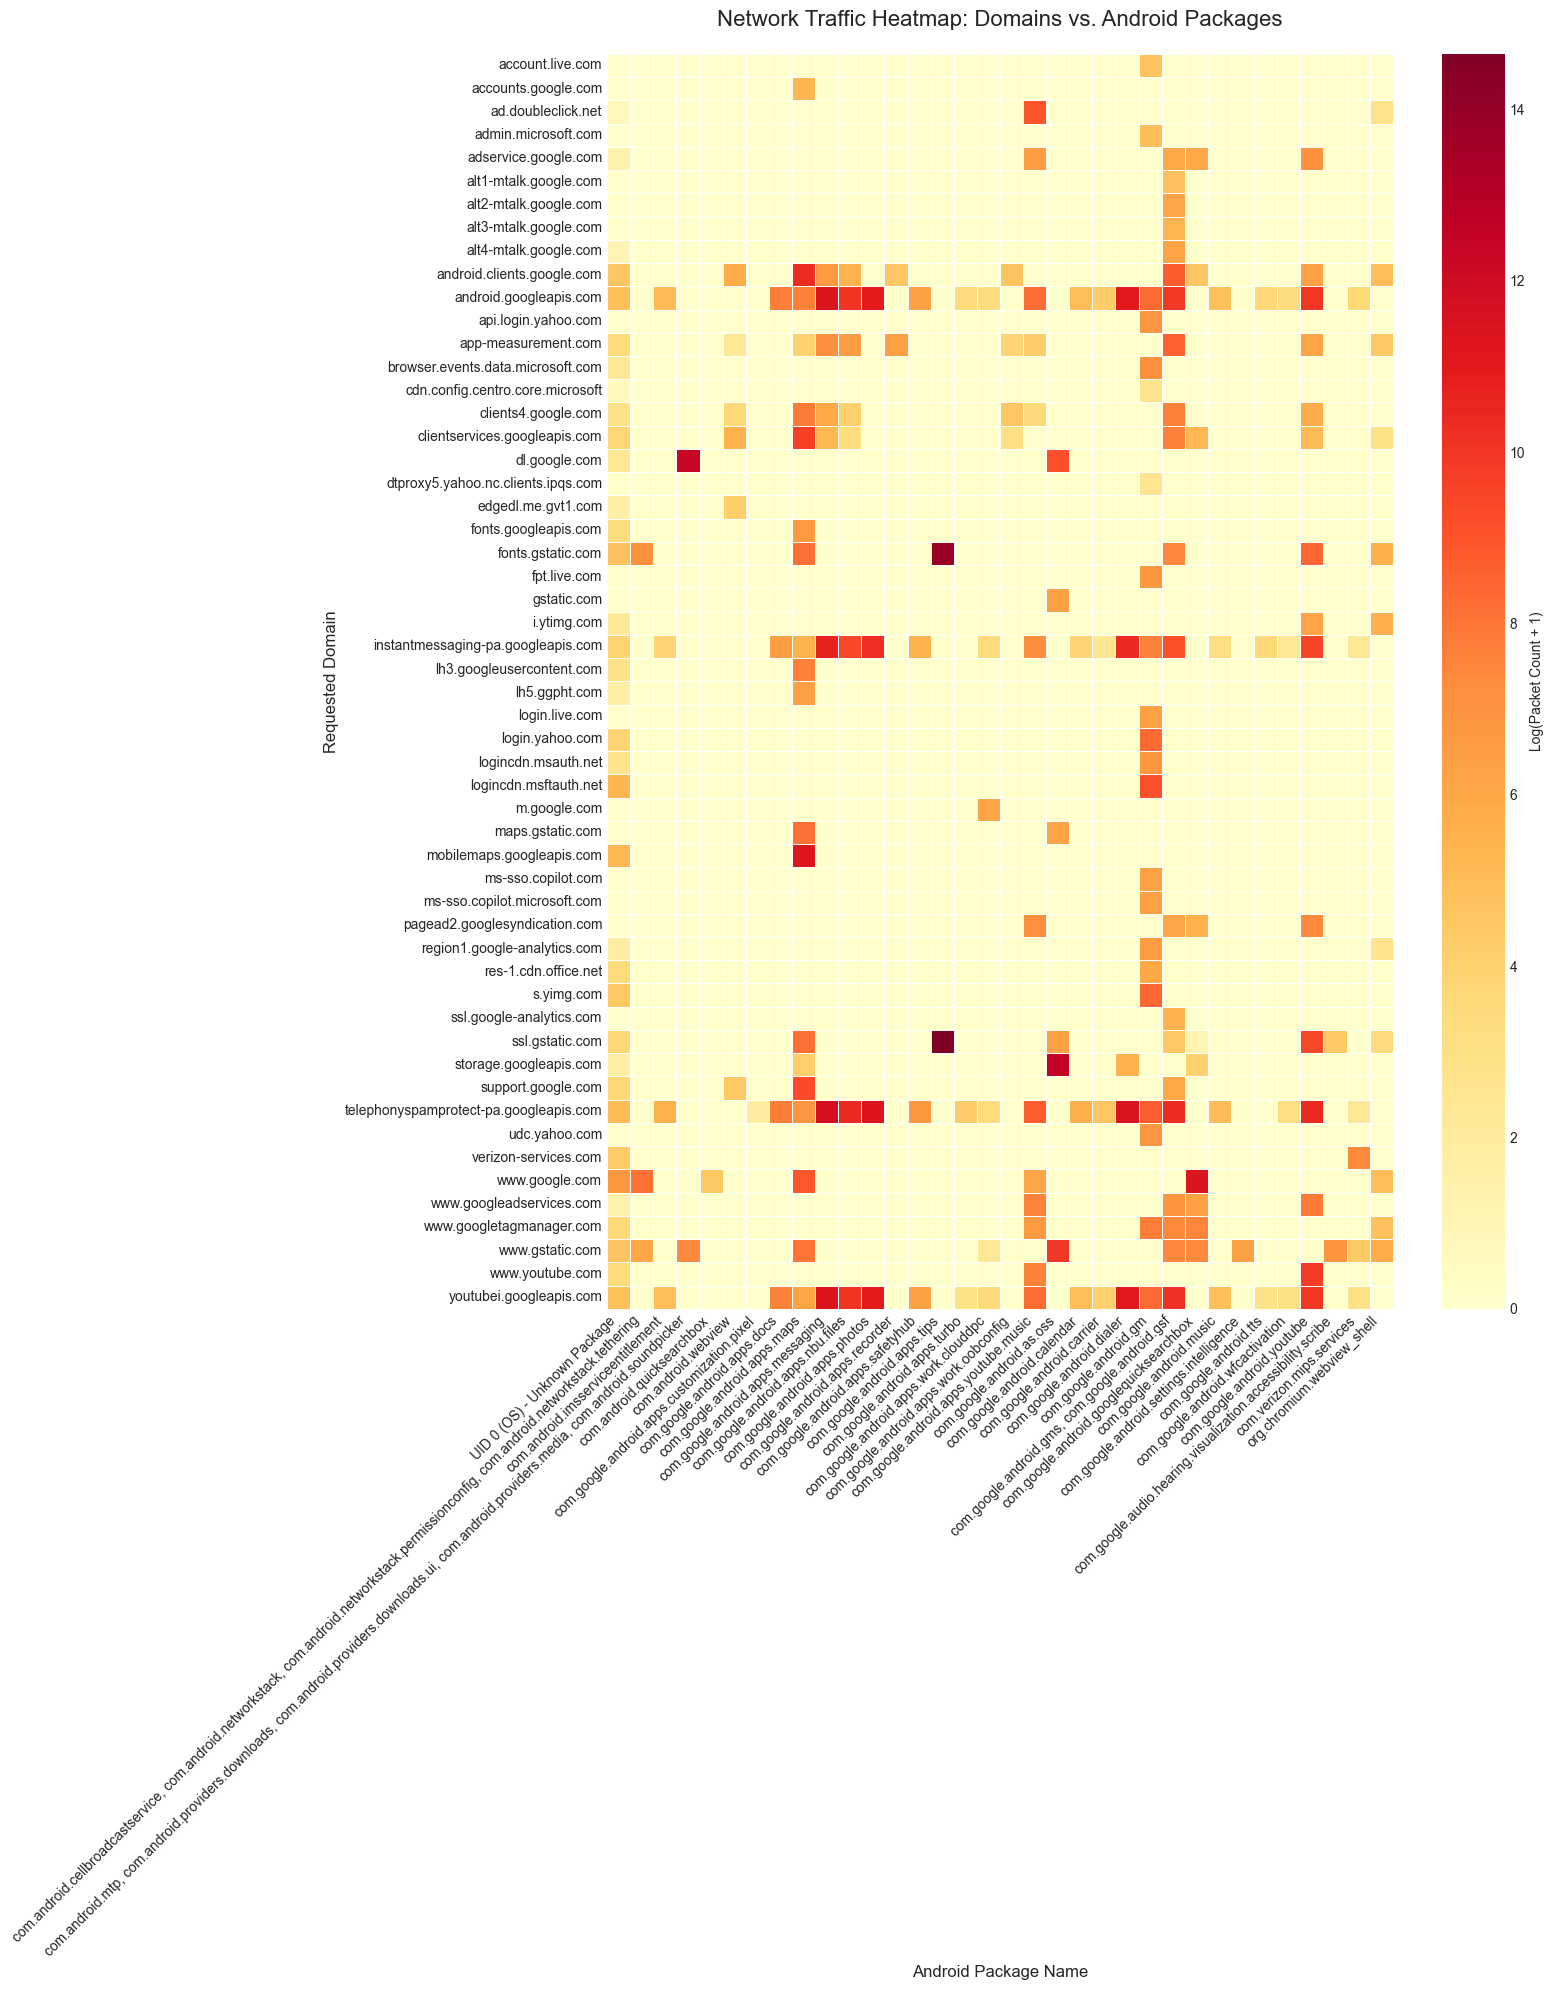

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_traffic_heatmap(df):
    """
    Plots a heatmap showing the volume of packets between packages and domains.
    """
    # 1. Filter out unresolved IP addresses and keep only real domains
    heatmap_df = df[~df['real_domain'].str.match(r'^\d{1,3}(\.\d{1,3}){3}$')]

    # Optional: Filter out standard OS packages to focus on user apps
    # os_keywords = ['com.android', 'com.google.android', 'Unknown']
    # heatmap_df = heatmap_df[~heatmap_df['package_name'].str.contains('|'.join(os_keywords), na=False)]

    # 2. Count packets per (package, domain) pair
    traffic_counts = heatmap_df.groupby(['package_name', 'real_domain']).size().reset_index(name='packet_count')

    if traffic_counts.empty:
        print("Not enough data to plot a heatmap after filtering.")
        return

    # 3. Pivot the table to create a matrix (Rows=Domains, Cols=Packages)
    traffic_matrix = traffic_counts.pivot(index='real_domain', columns='package_name', values='packet_count')
    traffic_matrix = traffic_matrix.fillna(0) # Replace NaN with 0 for the heatmap

    # 4. Optional: Log transform the counts if the variance is huge
    # (e.g., one domain has 10,000 packets and another has 5. Log scaling makes the colors more readable)
    log_matrix = np.log1p(traffic_matrix)

    # 5. Plotting
    plt.figure(figsize=(16, 20))

    # Use a clear color palette (e.g., 'YlGnBu' or 'Reds')
    ax = sns.heatmap(log_matrix,
                     cmap='YlOrRd',
                     linewidths=.5,
                     annot=False, # Set to True if you want the exact log numbers in the boxes
                     cbar_kws={'label': 'Log(Packet Count + 1)'})

    plt.title('Network Traffic Heatmap: Domains vs. Android Packages', fontsize=16, pad=20)
    plt.xlabel('Android Package Name', fontsize=12)
    plt.ylabel('Requested Domain', fontsize=12)

    # Rotate x-axis labels if they are long
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# Run the plot on your enriched dataframe
plot_traffic_heatmap(final_df)

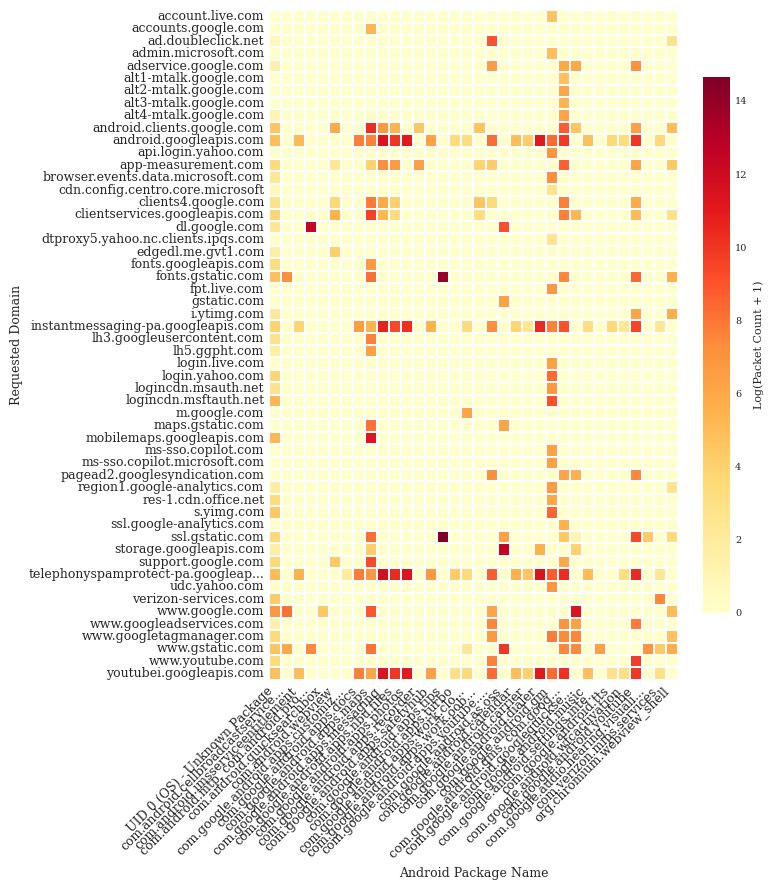

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_publication_heatmap(df):
    """
    Plots a publication-ready heatmap showing the volume of packets between packages and domains.
    Optimized for a two-column IEEE/ACM format.
    """
    # A standard double-column figure is ~7.16 inches wide.
    fig_width = 8
    # Increased height so that cells are tall enough to fit the 9pt Y-tick labels
    fig_height = 9

    plt.rcParams.update({
        'font.family': 'serif',
        'font.size': 10,
        'axes.labelsize': 9,
        'xtick.labelsize': 9,
        'ytick.labelsize': 9,
        'figure.figsize': (fig_width, fig_height),
        'figure.autolayout': True
    })

    # 1. Filter out unresolved IP addresses and keep only real domains
    heatmap_df = df[~df['real_domain'].str.match(r'^\d{1,3}(\.\d{1,3}){3}$')]

    # 2. Count packets per (package, domain) pair
    traffic_counts = heatmap_df.groupby(['package_name', 'real_domain']).size().reset_index(name='packet_count')

    if traffic_counts.empty:
        print("Not enough data to plot a heatmap after filtering.")
        return

    # 3. Pivot the table to create a matrix (Rows=Domains, Cols=Packages)
    traffic_matrix = traffic_counts.pivot(index='real_domain', columns='package_name', values='packet_count')
    traffic_matrix = traffic_matrix.fillna(0)

    # 4. Log transform the counts
    log_matrix = np.log1p(traffic_matrix)

    # 5. Plotting
    fig, ax = plt.subplots()

    ax = sns.heatmap(log_matrix,
                     cmap='YlOrRd',
                     linewidths=0.2,
                     annot=False,
                     cbar_kws={'label': 'Log(Packet Count + 1)', 'shrink': 0.8})

    # Format the legend (colorbar) fonts
    cbar = ax.collections[0].colorbar
    cbar.ax.yaxis.label.set_size(8)
    cbar.ax.tick_params(labelsize=7)

    # --- Truncate BOTH X and Y Tick Labels ---
    max_label_length = 35

    # Process X-axis labels
    truncated_x_labels = []
    for label in ax.get_xticklabels():
        text = label.get_text()
        if len(text) > max_label_length:
            truncated_x_labels.append(text[:max_label_length - 3] + '...')
        else:
            truncated_x_labels.append(text)
    ax.set_xticklabels(truncated_x_labels, rotation=45, ha='right')

    # Process Y-axis labels
    truncated_y_labels = []
    for label in ax.get_yticklabels():
        text = label.get_text()
        if len(text) > max_label_length:
            truncated_y_labels.append(text[:max_label_length - 3] + '...')
        else:
            truncated_y_labels.append(text)
    ax.set_yticklabels(truncated_y_labels)
    # -----------------------------------------------------

    plt.xlabel('Android Package Name')
    plt.ylabel('Requested Domain')

    # Save as PDF with a tight bounding box to strip excess white space
    plt.savefig("./images/apps_domain_heatmap.pdf", format='pdf', dpi=600, bbox_inches='tight')
    plt.show()

# Run the plot
plot_publication_heatmap(final_df)

/var/folders/f_/b80d8wfj0bnckn_1q79yv01m0000gn/T/ipykernel_14608/3767510394.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
/Users/tom/Documents/02_INIT/06_Sand/venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


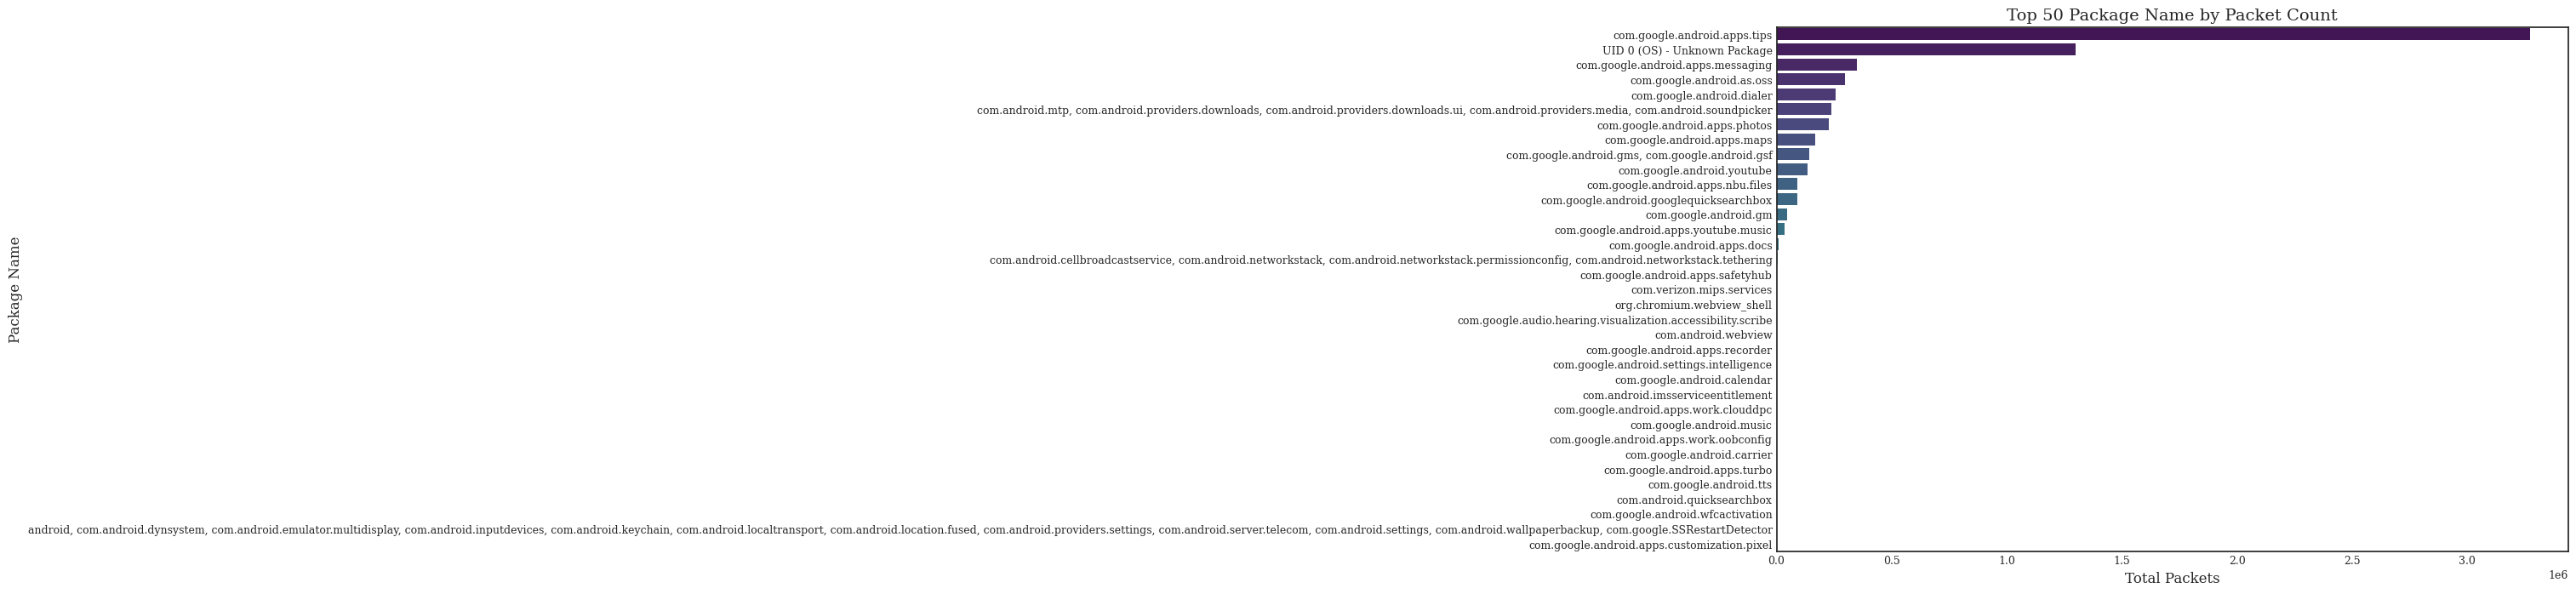

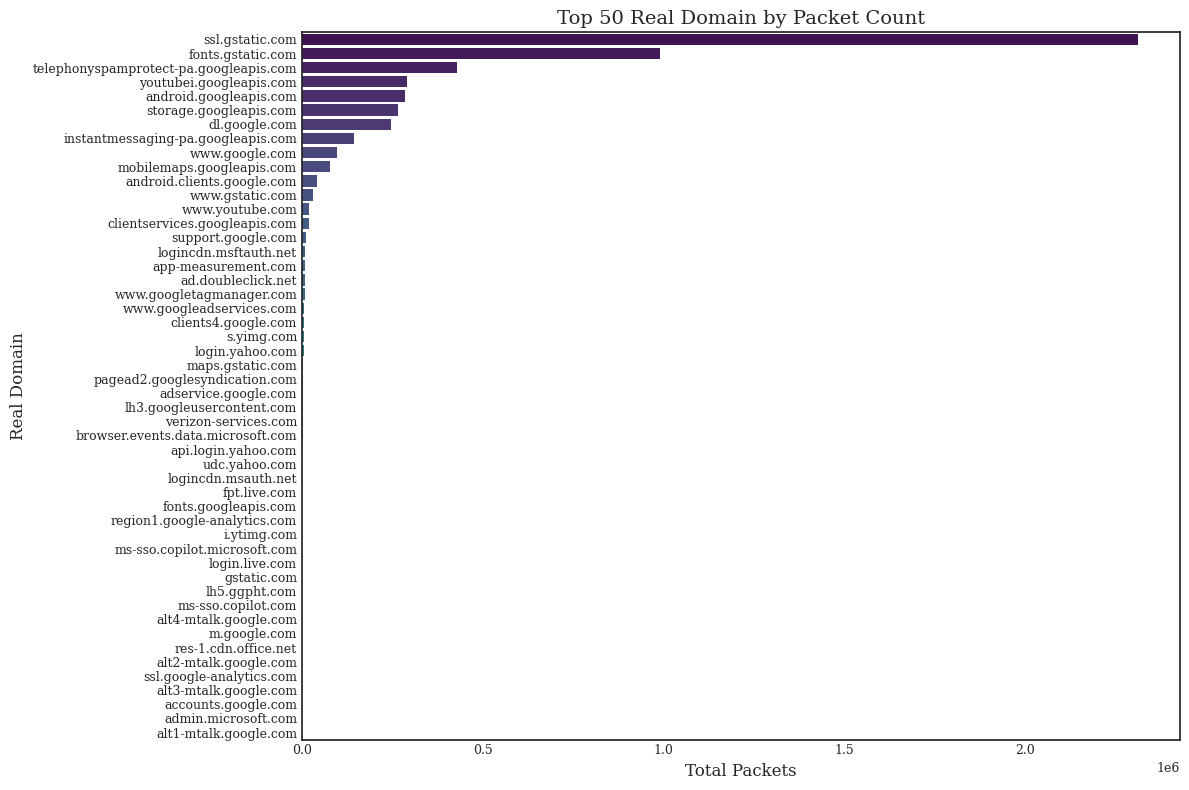

In [12]:
def plot_top_talkers(df, top_n=20, entity='package_name'):
    """
    Plots a bar chart of the top N entities (packages or domains) by packet volume.
    entity: 'package_name' or 'real_domain'
    """
    # Filter out IP addresses if grouping by domain
    if entity == 'real_domain':
        plot_df = df[~df['real_domain'].str.match(r'^\d{1,3}(\.\d{1,3}){3}$')]
    else:
        plot_df = df.copy()

    # Get the top N counts
    counts = plot_df[entity].value_counts().head(top_n)

    plt.figure(figsize=(12, 8))
    sns.barplot(x=counts.values, y=counts.index, palette='viridis')

    plt.title(f'Top {top_n} {entity.replace("_", " ").title()} by Packet Count', fontsize=14)
    plt.xlabel('Total Packets', fontsize=12)
    plt.ylabel(entity.replace("_", " ").title(), fontsize=12)
    plt.tight_layout()
    plt.show()

# Example: Show the apps generating the most traffic
plot_top_talkers(final_df, top_n=50, entity='package_name')

# Example: Show the most frequently contacted domains
plot_top_talkers(final_df, top_n=50, entity='real_domain')

In [13]:
import socket
import pandas as pd
from concurrent.futures import ThreadPoolExecutor

def resolve_ip(ip):
    """Attempts to resolve an IP to a domain name using Reverse DNS."""
    # Skip standard local/private IPs
    if ip.startswith(('10.', '192.168.', '127.', '172.', '255.')):
        return ip
    try:
        return socket.gethostbyaddr(ip)[0]
    except Exception:
        return ip # Fallback to returning the IP if resolution fails

def get_all_domains_to_uids(df):
    print("Filtering external traffic...")
    # 1. Filter out internal traffic and drop rows missing an IP or UID
    external_traffic = df[~df['dst_ip'].astype(str).str.startswith(('10.', '192.168.', '127.', '172.'))].copy()
    external_traffic = external_traffic.dropna(subset=['uid', 'dst_ip'])

    # Convert UID to integer (pandas sometimes casts it to float if there were NaNs)
    external_traffic['uid'] = external_traffic['uid'].astype(int)

    # 2. Extract unique IPs and resolve them
    unique_ips = external_traffic['dst_ip'].unique()
    print(f"Resolving {len(unique_ips)} unique IPs to domains (this may take a moment)...")

    ip_to_domain = {}
    with ThreadPoolExecutor(max_workers=20) as executor:
        results = executor.map(resolve_ip, unique_ips)
        for ip, domain in zip(unique_ips, results):
            ip_to_domain[ip] = domain

    # 3. Apply the domain mapping to the DataFrame
    external_traffic['domain'] = external_traffic['dst_ip'].map(ip_to_domain)

    # 4. Create a flat, deduplicated table of Domain to UID
    domain_uid_mapping = external_traffic[['domain', 'uid']].drop_duplicates()

    # 5. Group it so each Domain shows a list of all UIDs communicating with it
    domain_table = domain_uid_mapping.groupby('domain')['uid'].apply(lambda x: sorted(list(set(x)))).reset_index()

    # 6. Clean up columns and sort alphabetically
    domain_table.columns = ['Domain', 'App_UIDs']
    domain_table = domain_table.sort_values(by='Domain', ignore_index=True)

    return domain_table

# --- Execute the function on your existing DataFrame ---
all_domains_table = get_all_domains_to_uids(final_df)

print(all_domains_table.head(20))

# Save to CSV to view the full list easily
# all_domains_table.to_csv('all_domains_to_uids.csv', index=False)

Filtering external traffic...
Resolving 174 unique IPs to domains (this may take a moment)...
                                    Domain   
0   123.35.104.34.bc.googleusercontent.com  \
1                            13.107.246.60   
2                             13.89.179.15   
3                          142.251.150.119   
4                            142.251.150.4   
5                          142.251.151.119   
6                            142.251.151.4   
7                          142.251.152.119   
8                            142.251.152.4   
9                          142.251.153.119   
10                           142.251.153.4   
11                         142.251.154.119   
12                           142.251.154.4   
13                         142.251.155.119   
14                           142.251.155.4   
15                         142.251.156.119   
16                           142.251.156.4   
17                         142.251.157.119   
18                           142

In [14]:
%pip install "fastparquet"

Note: you may need to restart the kernel to use updated packages.


In [15]:
# Export to Parquet:
final_df.to_parquet(f'{DATASET_DIR}/delta/app_traffic.parquet', engine='fastparquet')

# Port Analysis

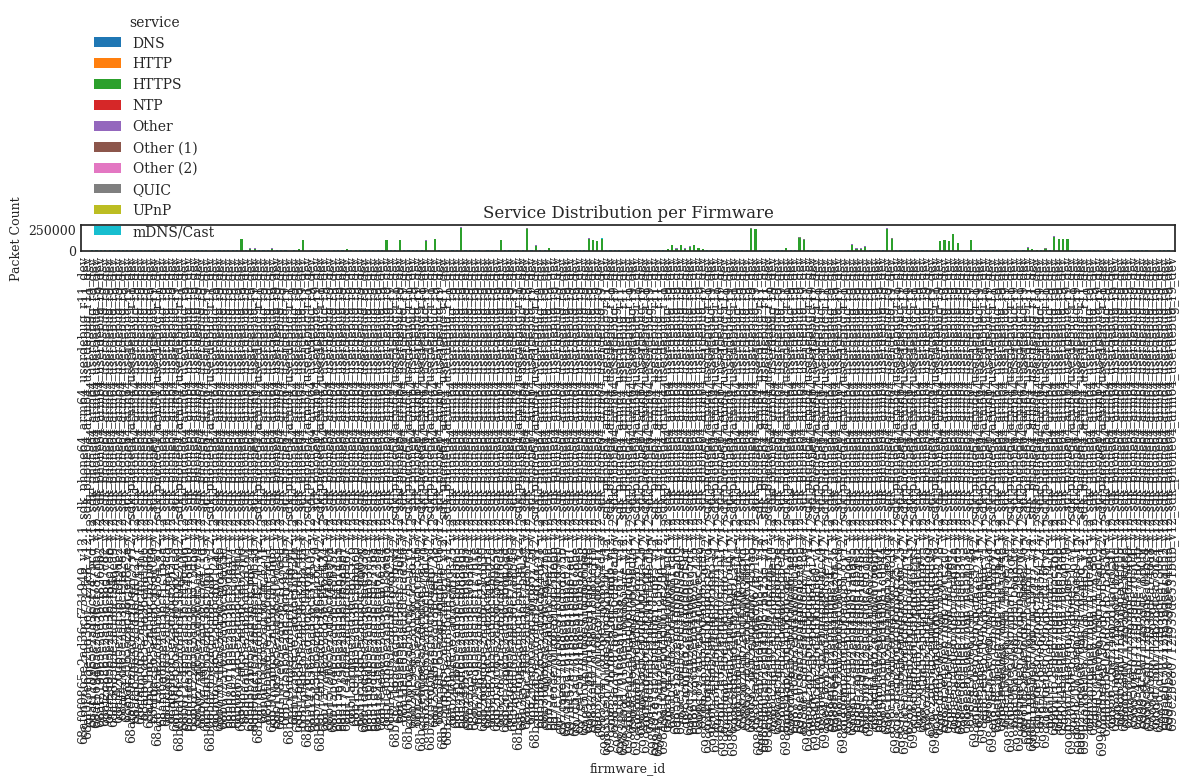

In [16]:
def classify_port(row):
    port = row['dst_port']
    proto = row['protocol']

    # 1. QUIC Protocol (Modern Android/Google services use UDP 443)
    if proto == 'UDP' and port == 443:
        return 'QUIC'

    # 2. Non-TCP/UDP handling
    if proto not in ['TCP', 'UDP']:
        return proto

    # 3. Standard Web & Infrastructure
    if port == 443: return 'HTTPS'
    if port == 80:  return 'HTTP'
    if port == 53:  return 'DNS'
    if port in [67, 68]: return 'DHCP'
    if port == 123: return 'NTP' # Essential for cert validation

    # 4. Android & Development Typical Stuff
    # ADB (5555 range), Logcat/Shell (5037), mDNS/Chromecast (5353)
    if port in [5554, 5555, 5556]: return 'ADB'
    if port == 5037: return 'ADB Server'
    if port == 5353: return 'mDNS/Cast'

    # 5. Management & Shells
    if port == 22:  return 'SSH'
    if port == 23:  return 'Telnet'

    # 6. IoT & Media
    if port in [1883, 8883]: return 'MQTT'
    if port == 1900: return 'UPnP'
    if port in [8008, 8009]: return 'Google Home'

    return 'Other'

# Apply and recreate pivot
final_df['service'] = final_df.apply(classify_port, axis=1)

# Pivot table for a Heatmap or stacked bar chart
service_pivot = final_df.groupby(['firmware_id', 'service']).size().unstack(fill_value=0)
service_pivot.plot(kind='bar', stacked=True, figsize=(12,6), colormap='tab10')
plt.title("Service Distribution per Firmware")
plt.ylabel("Packet Count")
plt.show()

In [17]:
filter_based_on_http = True
if filter_based_on_http:
    # 1. Define your threshold for WEB packets only
    web_threshold = 2000  # Minimum HTTP/HTTPS packets required

    # 2. Create a temporary boolean mask for web traffic
    # This matches your previously defined 'service' or 'bi_service' labels
    is_web = final_df['service'].str.contains('HTTP|HTTPS', case=False, na=False)

    # 3. Calculate web packet counts per firmware_id
    # We sum the booleans: True counts as 1, False as 0
    web_counts = final_df.groupby('firmware_id')['service'].transform(lambda x: x.str.contains('HTTP|HTTPS', case=False).sum())

    # 4. Create the filtered dataframe
    # We keep rows where the firmware_id has enough web packets total
    filtered_df = final_df[web_counts >= web_threshold].copy()

    # --- Summary Statistics ---
    original_ids = final_df['firmware_id'].nunique()
    filtered_ids = filtered_df['firmware_id'].nunique()

    print(f"--- Web Traffic Filtering (Threshold: {web_threshold}) ---")
    print(f"Original unique firmwares: {original_ids}")
    print(f"Firmwares reaching web threshold: {filtered_ids}")
    print(f"Total packets removed: {len(final_df) - len(filtered_df)}")
else:
    # Filter Firmware samples with not sufficient enough packages:
    # 1. Define your threshold
    threshold = 10000  # Set the minimum number of packets required per firmware_id

    # 2. Identify the packet count for each firmware_id and filter
    # We use 'src_ip' (or any column without NaNs) to count occurrences
    counts = final_df.groupby('firmware_id')['src_ip'].transform('count')

    # 3. Create the filtered dataframe
    filtered_df = final_df[counts >= threshold].copy()

    # --- Summary Statistics ---
    original_ids = final_df['firmware_id'].nunique()
    filtered_ids = filtered_df['firmware_id'].nunique()

    print(f"Original unique firmwares: {original_ids}")
    print(f"Firmwares after filtering: {filtered_ids}")
    print(f"Packets removed: {len(final_df) - len(filtered_df)}")

final_df = filtered_df

count = final_df['firmware_id'].nunique()
print(f"Number of unique firmware ids: {count}")

--- Web Traffic Filtering (Threshold: 2000) ---
Original unique firmwares: 249
Firmwares reaching web threshold: 57
Total packets removed: 1153122
Number of unique firmware ids: 57


Total packets captured: 5524508

Protocol Distribution:
protocol
TCP          5387029
UDP           136078
Other (2)        970
Other (1)        431
Name: count, dtype: int64

Top 5 Destination IPs:
dst_ip
74.125.29.94      2312096
192.178.170.94     989323
172.217.118.4      144814
172.217.116.4      144694
172.217.113.4      144678
Name: count, dtype: int64


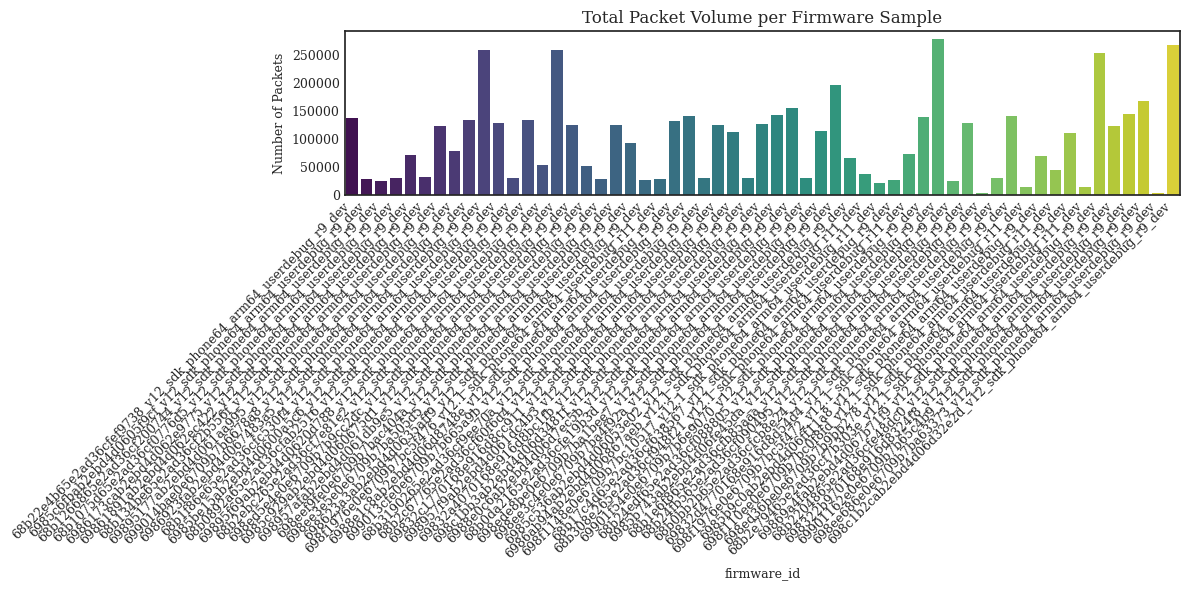

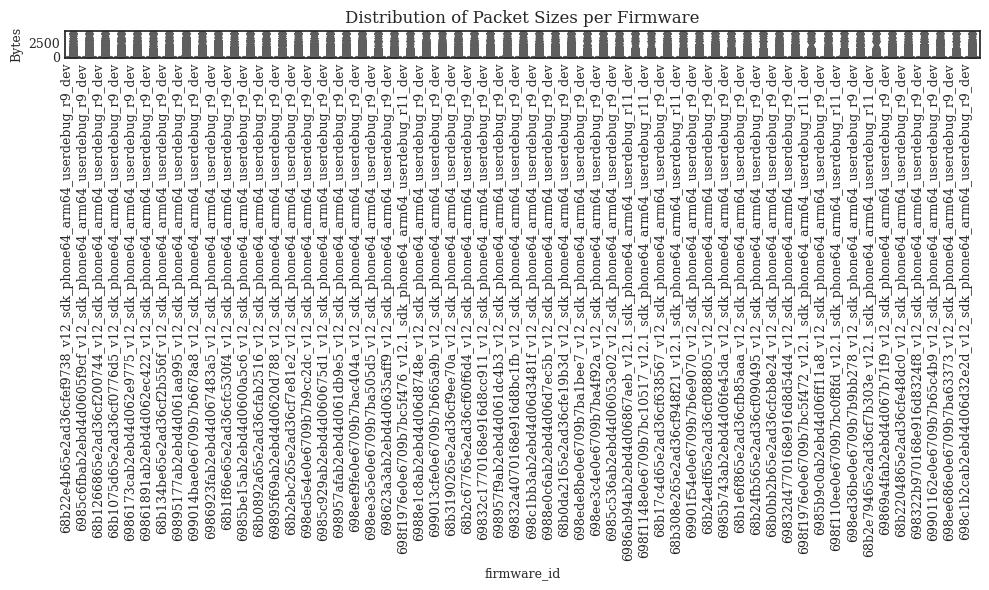

In [18]:
# Check how many packets we actually have now
print(f"Total packets captured: {len(final_df)}")

# See the distribution of protocols
print("\nProtocol Distribution:")
print(final_df['protocol'].value_counts())

# See which IPs are the most active
print("\nTop 5 Destination IPs:")
print(final_df['dst_ip'].value_counts().head(5))

# 1. Packet Count per Firmware
plt.figure(figsize=(12, 6))
sns.countplot(data=final_df, x='firmware_id', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title("Total Packet Volume per Firmware Sample")
plt.ylabel("Number of Packets")
plt.tight_layout()
plt.show()

# 2. Boxplot of Packet Lengths (to see if some firmware sends larger data chunks)
plt.figure(figsize=(10, 6))
sns.boxplot(data=final_df, x='firmware_id', y='length', palette='Set3')
plt.xticks(rotation=90, ha='right')
plt.title("Distribution of Packet Sizes per Firmware")
plt.ylabel("Bytes")
plt.tight_layout()
plt.show()

In [19]:
def classify_dynamic(row):
    port = row['dst_port']
    proto = row['protocol']

    # 1. QUIC & Non-IP logic
    if proto == 'UDP' and port == 443: return 'QUIC'
    if proto not in ['TCP', 'UDP']: return proto
    if port is None: return 'Non-Port Traffic'

    # 2. Known Services (Your established list)
    known_map = {
        443: 'HTTPS', 80: 'HTTP', 53: 'DNS', 123: 'NTP',
        22: 'SSH', 23: 'Telnet', 5037: 'ADB Server', 5353: 'mDNS/Cast',
        1883: 'MQTT', 8883: 'MQTTS', 1900: 'UPnP'
    }
    if port in known_map: return known_map[port]
    if port in [5554, 5555, 5556]: return 'ADB'

    # 3. Fallback: Return the port number as a string
    return f"Port {int(port)}"

final_df['dynamic_service'] = final_df.apply(classify_dynamic, axis=1)

# Count occurrences of every identified service/port
counts = final_df['dynamic_service'].value_counts()

# Keep the top 15 most frequent services/ports, group everything else into 'Misc Other'
top_services = counts.nlargest(15).index
final_df['final_service'] = final_df['dynamic_service'].apply(
    lambda x: x if x in top_services else 'Misc Other'
)


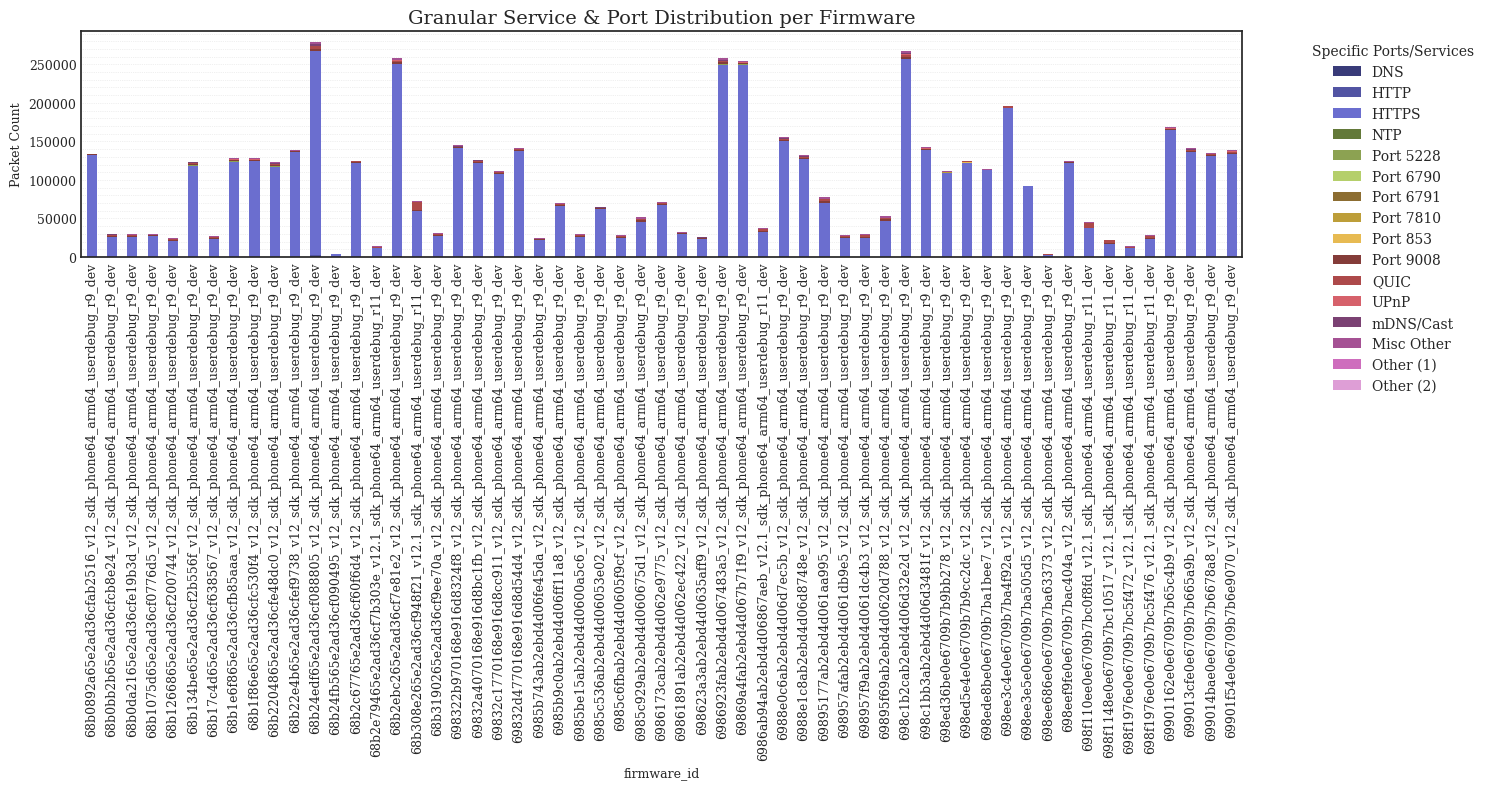

In [20]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Create pivot with the granular categories
granular_pivot = final_df.groupby(['firmware_id', 'final_service']).size().unstack(fill_value=0)

# Sort columns so 'Misc Other' and 'Other' are at the end (optional but cleaner)
cols = [c for c in granular_pivot.columns if 'Other' not in c] + \
       [c for c in granular_pivot.columns if 'Other' in c]
granular_pivot = granular_pivot[cols]

ax = granular_pivot.plot(kind='bar', stacked=True, figsize=(15, 8), colormap='tab20b')

# Fine-grained Y-Axis
ax.yaxis.set_major_locator(ticker.AutoLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))
plt.grid(axis='y', which='both', linestyle=':', alpha=0.6)

plt.title("Granular Service & Port Distribution per Firmware", fontsize=14)
plt.legend(title="Specific Ports/Services", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel("Packet Count")
plt.tight_layout()
plt.show()

In [21]:
def classify_port_logic(port, proto):
    """Helper to map port numbers to service names."""
    if proto == 'UDP' and port == 443: return 'QUIC'

    known_map = {
        443: 'HTTPS', 80: 'HTTP', 53: 'DNS', 123: 'NTP',
        22: 'SSH', 23: 'Telnet', 5037: 'ADB Server', 5353: 'mDNS/Cast',
        1883: 'MQTT', 1900: 'UPnP', 67: 'DHCP', 68: 'DHCP'
    }
    if port in known_map: return known_map[port]
    if port in [5554, 5555, 5556]: return 'ADB'
    return f"Port {int(port)}"

def classify_bidirectional(row):
    src, dst = row['src_port'], row['dst_port']
    proto = row['protocol']

    # Define standard/ephemeral boundary (usually 32768 on Linux/Android)
    EPHEMERAL_START = 32768

    # Handle Non-TCP/UDP (like ICMP)
    if proto not in ['TCP', 'UDP']: return proto
    if src is None or dst is None: return "Unknown/Fragment"

    # 1. OUTGOING REQUEST: Destination is a standard service port
    if dst < EPHEMERAL_START:
        return f"{classify_port_logic(dst, proto)} (Req)"

    # 2. INCOMING REPLY: Source is a standard service port
    if src < EPHEMERAL_START:
        return f"{classify_port_logic(src, proto)} (Reply)"

    # 3. P2P / HIGH-PORT: Both sides are in the ephemeral range
    return "High-Port P2P/Internal"

# Apply the new logic
final_df['bi_service'] = final_df.apply(classify_bidirectional, axis=1)

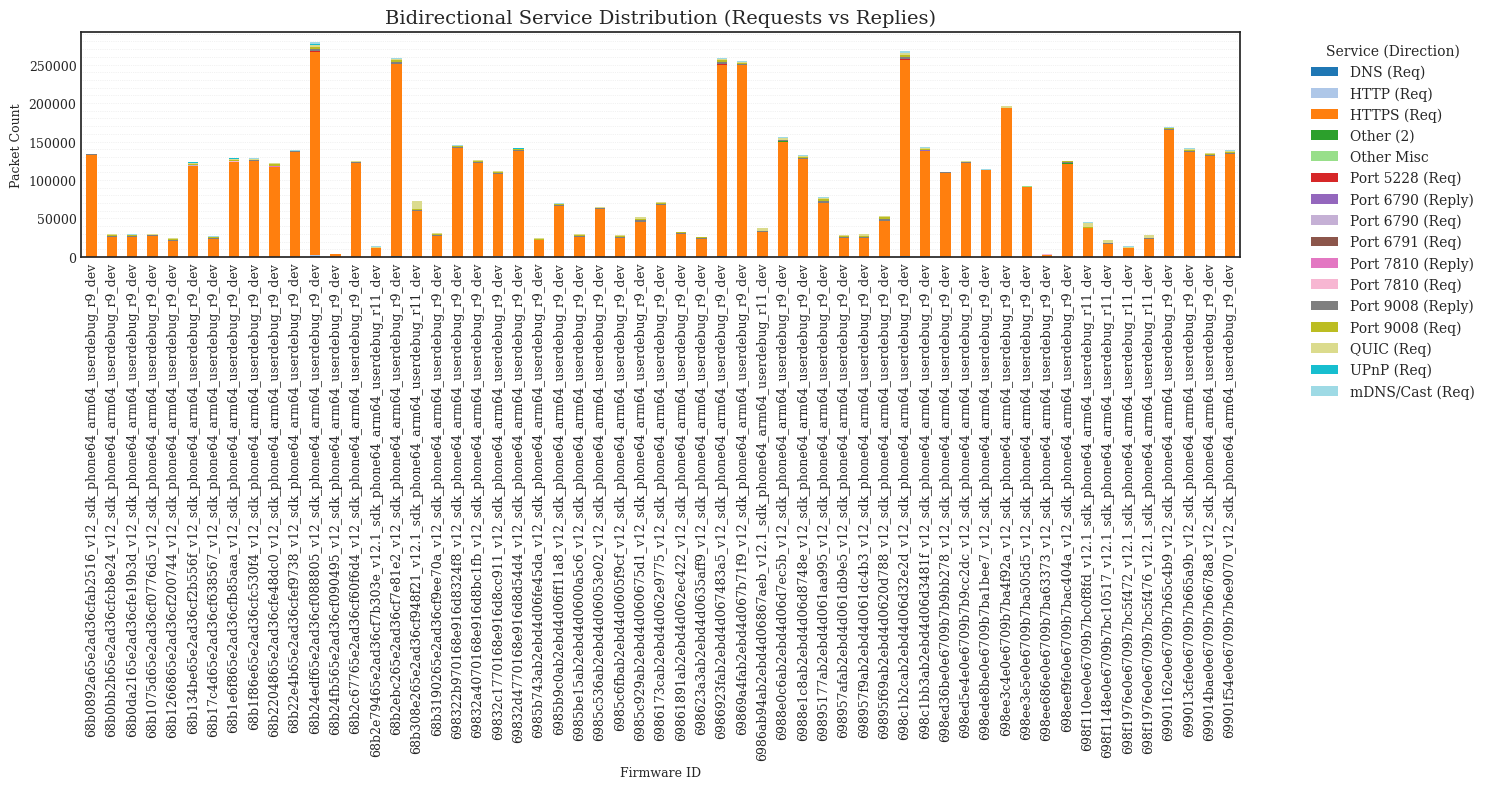

In [22]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Group the 'Long Tail' to keep the plot clean
top_bi_services = final_df['bi_service'].value_counts().nlargest(15).index
final_df['plot_service'] = final_df['bi_service'].apply(
    lambda x: x if x in top_bi_services else 'Other Misc'
)

# 2. Pivot the data
bi_pivot = final_df.groupby(['firmware_id', 'plot_service']).size().unstack(fill_value=0)

# 3. Plotting
ax = bi_pivot.plot(kind='bar', stacked=True, figsize=(15, 8), colormap='tab20')

# Fine-grained Y-axis
ax.yaxis.set_major_locator(ticker.AutoLocator())
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(5))
plt.grid(axis='y', which='both', linestyle=':', alpha=0.5)

plt.title("Bidirectional Service Distribution (Requests vs Replies)", fontsize=14)
plt.ylabel("Packet Count")
plt.xlabel("Firmware ID")
plt.legend(title="Service (Direction)", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [23]:
def extended_classify(row):
    port = row['dst_port']
    src_port = row['src_port']
    proto = row['protocol']
    dst_ip = row['dst_ip']

    if proto == 'ICMP': return 'Ping (ICMP)'
    if port is None: return 'System/Other'

    # --- 1. QUIC & Modern Web ---
    # QUIC uses UDP 443
    if proto == 'UDP' and (port == 443 or src_port == 443):
        return 'QUIC (HTTP/3)'

    # --- 2. Standard Web & Infrastructure ---
    if port == 53 or src_port == 53: return 'DNS'
    if port == 443 or src_port == 443: return 'HTTPS (TLS)'
    if port == 80 or port == 8080: return 'HTTP'
    if port == 123: return 'NTP (Time)'

    # --- 3. Common High-Port TCP Services ---
    # Databases & IoT
    if port == 1883 or port == 8883: return 'MQTT (IoT)'
    if port == 3306: return 'MySQL'
    if port == 5432: return 'PostgreSQL'
    if port == 6379: return 'Redis'
    if port == 27017: return 'MongoDB'

    # Proxies & Control
    if port == 3128 or port == 8081: return 'Proxy'
    if port == 9000: return 'Android/FastCGI'

    # --- 4. Android/Emulator Specific ---
    if port in [5554, 5555] or src_port in [5554, 5555]: return 'ADB (Debug)'
    if port == 5037: return 'ADB Server'

    # --- 5. High Port Analysis ---
    # If it's TCP and not a known low port, it might be a dynamic/ephemeral port
    if proto == 'TCP':
        if port > 32768:
            return 'TCP High (Ephemeral/Dynamic)'
        return f'TCP Custom ({port})'

    if proto == 'UDP':
        if port > 32768:
            return 'UDP High (Ephemeral)'
        return f'UDP Custom ({port})'

    return f'Unknown ({port}/{proto})'

final_df['service_category'] = final_df.apply(extended_classify, axis=1)

# Apply the enhanced classification
final_df['service_category'] = final_df.apply(extended_classify, axis=1)

In [24]:
def get_direction(row):
    if row['src_ip'] == '10.0.2.15':
        return 'Outbound'
    elif row['dst_ip'] == '10.0.2.15':
        return 'Inbound'
    else:
        return 'Internal/Other'

final_df['direction'] = final_df.apply(get_direction, axis=1)

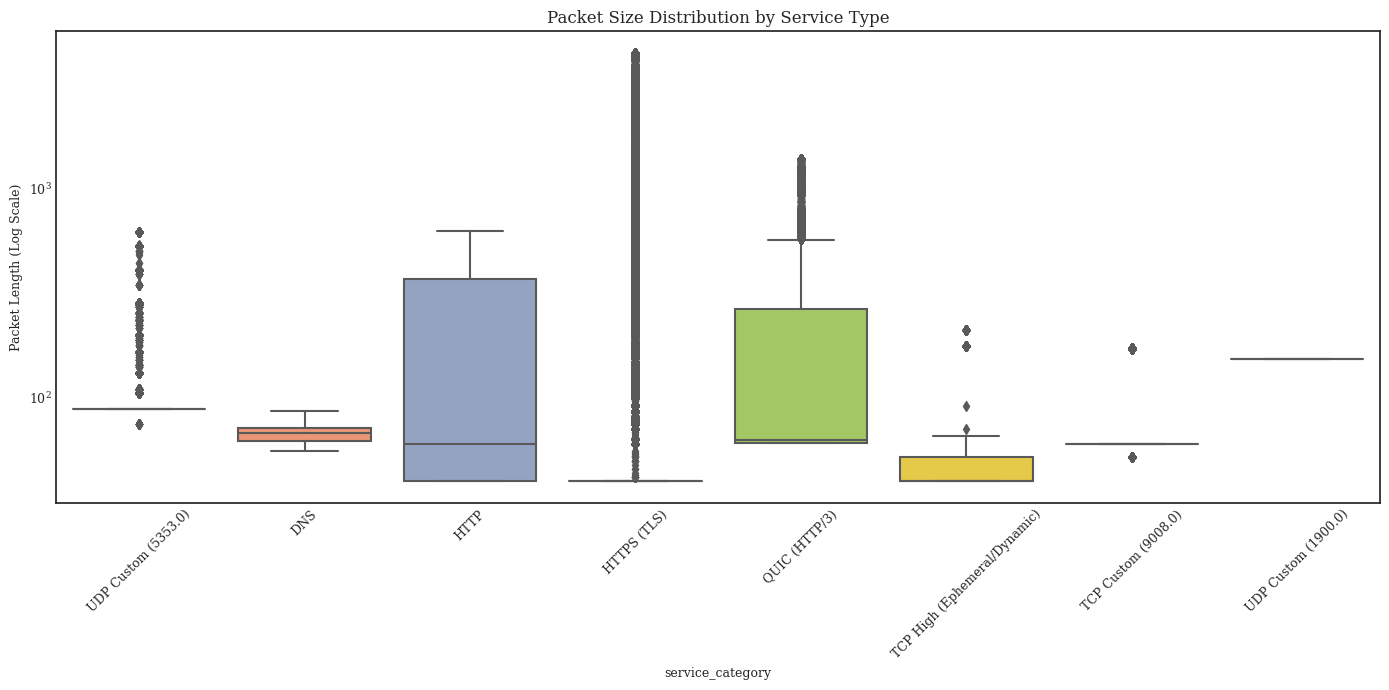

In [25]:
plt.figure(figsize=(14, 7))
# Filtering out "Other" to see the main services clearly
top_services = final_df['service_category'].value_counts().nlargest(8).index
filtered_df = final_df[final_df['service_category'].isin(top_services)]

sns.boxplot(data=filtered_df, x='service_category', y='length', palette='Set2')
plt.yscale('log') # Log scale is helpful because packet sizes vary wildly
plt.title("Packet Size Distribution by Service Type")
plt.xticks(rotation=45)
plt.ylabel("Packet Length (Log Scale)")
plt.show()

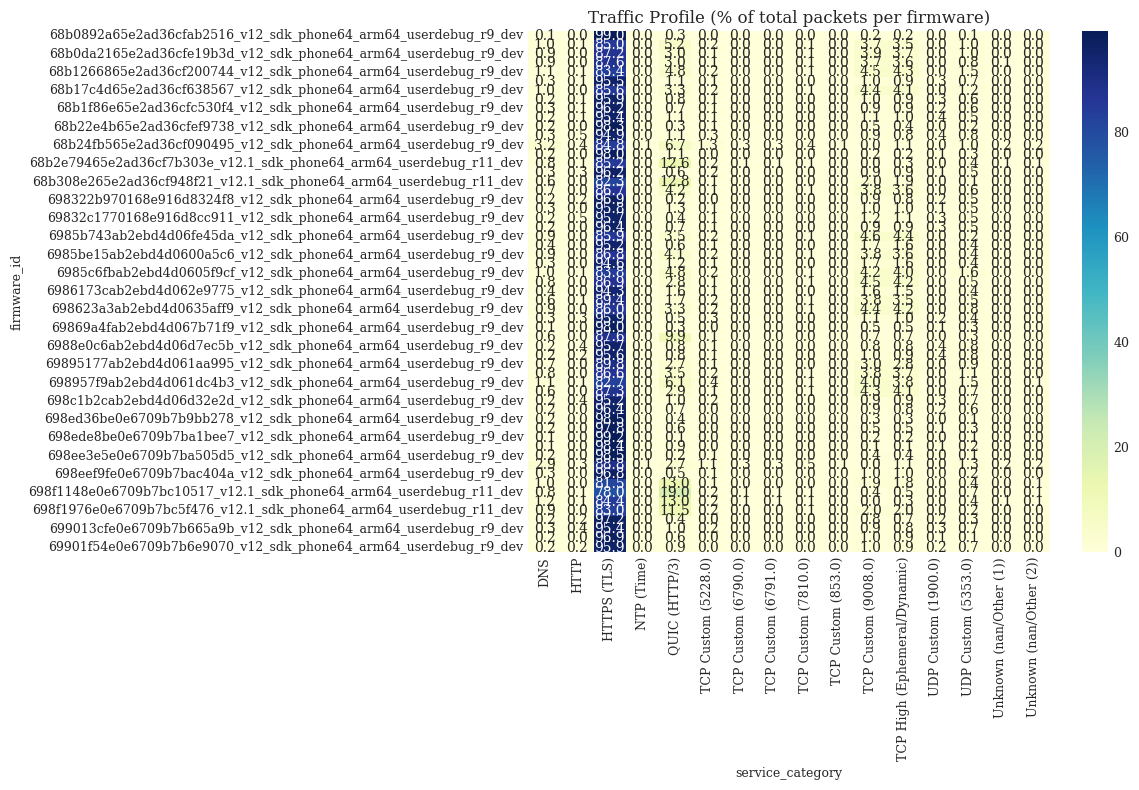

In [26]:
# Cross-tabulation of Firmware vs Service
profile = pd.crosstab(final_df['firmware_id'], final_df['service_category'])
# Convert to percentage to compare different file sizes fairly
profile_pct = profile.div(profile.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 8))
sns.heatmap(profile_pct, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Traffic Profile (% of total packets per firmware)")
plt.show()

# Flow-Level Analysis

In [27]:
import pandas as pd
import numpy as np

def generate_flow_df(input_df):
    # infinite time can pass, and as long as the IPs, ports, and protocols match perfectly, it belongs to the same single flow.

    # 1. Ensure timestamps are proper datetime objects
    # We use a copy to avoid SettingWithCopy warnings
    working_df = input_df.copy()
    working_df['timestamp'] = pd.to_datetime(working_df['timestamp'], unit='s')

    # 2. Define the 5-tuple (the unique keys for a "conversation")
    five_tuple = ['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol']

    # 3. Calculate Inter-Arrival Time (IAT) on the packet level
    # IAT is the time between packet N and packet N-1 in the same flow
    working_df = working_df.sort_values(by=['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'timestamp'])
    working_df['iat'] = working_df.groupby(five_tuple[:-1])['timestamp'].diff().dt.total_seconds()

    # 4. Aggregate packets into Flows
    flow_df = working_df.groupby(five_tuple).agg(
        flow_start=('timestamp', 'min'),
        flow_end=('timestamp', 'max'),
        packet_count=('length', 'count'),
        total_bytes=('length', 'sum'),
        avg_packet_size=('length', 'mean'),
        std_packet_size=('length', 'std'),
        avg_iat=('iat', 'mean'),      # Average time between packets
        max_iat=('iat', 'max')        # Maximum silence in the flow
    ).reset_index()

    # 5. Calculate Duration and Rates
    flow_df['duration_sec'] = (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds()
    flow_df['bps'] = (flow_df['total_bytes'] * 8) / flow_df['duration_sec'].replace(0, 1)
    flow_df['pps'] = flow_df['packet_count'] / flow_df['duration_sec'].replace(0, 1)

    return flow_df

def generate_flow_df_with_threshold(input_df, idle_threshold_sec=30.0):
    working_df = input_df.copy()
    working_df['timestamp'] = pd.to_datetime(working_df['timestamp'], unit='s')

    five_tuple = ['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol']

    # Sort packets chronologically within their conversations
    working_df = working_df.sort_values(by=five_tuple + ['timestamp'])

    # Calculate packet-level IAT
    working_df['iat'] = working_df.groupby(five_tuple)['timestamp'].diff().dt.total_seconds()

    # Correct way to assign session numbers based on threshold passing:
    # First packet or packet exceeding threshold marks a new flow block
    working_df['is_new_flow'] = ((working_df['iat'] > idle_threshold_sec) | (working_df['iat'].isna())).astype(int)
    working_df['flow_id'] = working_df.groupby(five_tuple)['is_new_flow'].cumsum()

    # --- Group by 5-tuple AND the new flow_id ---
    flow_df = working_df.groupby(five_tuple + ['flow_id']).agg(
        flow_start=('timestamp', 'min'),
        flow_end=('timestamp', 'max'),
        packet_count=('length', 'count'),
        total_bytes=('length', 'sum'),
        avg_packet_size=('length', 'mean'),
        std_packet_size=('length', 'std'),
        avg_iat=('iat', 'mean'),
        max_iat=('iat', 'max')
    ).reset_index()

    # Calculate Duration and Rates
    flow_df['duration_sec'] = (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds()
    flow_df['bps'] = (flow_df['total_bytes'] * 8) / flow_df['duration_sec'].replace(0, 1)
    flow_df['pps'] = flow_df['packet_count'] / flow_df['duration_sec'].replace(0, 1)

    return flow_df

def generate_dual_threshold_flows(input_df, idle_timeout_sec=30.0, active_timeout_sec=1800.0):
    working_df = input_df.copy()
    working_df['timestamp_dt'] = pd.to_datetime(working_df['timestamp'], unit='s')

    five_tuple = ['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol']
    working_df = working_df.sort_values(by=five_tuple + ['timestamp_dt'])

    # 1. Fundamental packet-level IAT
    working_df['iat'] = working_df.groupby(five_tuple)['timestamp_dt'].diff().dt.total_seconds()

    # 2. Track time elapsed since the start of this specific 5-tuple conversation
    flow_birth = working_df.groupby(five_tuple)['timestamp_dt'].transform('min')
    working_df['age_since_birth'] = (working_df['timestamp_dt'] - flow_birth).dt.total_seconds()

    # 3. Dual-Threshold Strategy
    is_idle_break = working_df['iat'] > idle_timeout_sec

    # Clean way to calculate active breaks without dropping group alignment
    active_window_block = working_df['age_since_birth'] // active_timeout_sec
    is_active_break = working_df.groupby(five_tuple)['age_since_birth'].transform(lambda x: (x // active_timeout_sec).diff().fillna(0) > 0)

    # Combine into a strict binary flag
    working_df['is_new_flow'] = (is_idle_break | is_active_break | working_df['iat'].isna()).astype(int)
    working_df['sub_flow_id'] = working_df.groupby(five_tuple)['is_new_flow'].cumsum()

    # 4. Aggregation
    scientific_key = five_tuple + ['sub_flow_id']
    flow_df = working_df.groupby(scientific_key).agg(
        flow_start=('timestamp_dt', 'min'),
        flow_end=('timestamp_dt', 'max'),
        packet_count=('length', 'count'),
        total_bytes=('length', 'sum'),
        avg_packet_size=('length', 'mean'),
        std_packet_size=('length', 'std'),
        avg_iat=('iat', 'mean'),
        max_iat=('iat', 'max'),
        min_iat=('iat', 'min')
    ).reset_index()

    flow_df['duration_sec'] = (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds()
    safe_duration = flow_df['duration_sec'].replace(0, 1.0)
    flow_df['bps'] = (flow_df['total_bytes'] * 8) / safe_duration
    flow_df['pps'] = flow_df['packet_count'] / safe_duration

    return flow_df

# Execute the scientifically sound pipeline
flow_df = generate_dual_threshold_flows(final_df, idle_timeout_sec=30.0, active_timeout_sec=1800.0)
print(f"Validated Flow Construction: Aggregated packets into {len(flow_df)} standardized flows.")


# Run the function
flow_df = generate_flow_df_with_threshold(final_df)
print(f"Aggregated {len(final_df)} packets into {len(flow_df)} unique flows.")
flow_df.head()

Validated Flow Construction: Aggregated packets into 390185 standardized flows.
Aggregated 5524508 packets into 390170 unique flows.


,firmware_id,src_ip,dst_ip,src_port,dst_port,protocol,flow_id,flow_start,flow_end,packet_count,total_bytes,avg_packet_size,std_packet_size,avg_iat,max_iat,duration_sec,bps,pps
0,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1164.0,53.0,UDP,1.0,2026-08-13 19:30:09.515471104,2026-08-13 19:30:09.515471104,1,70,70.0,NaN,NaN,NaN,0.0,560.0,1.0
1,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1229.0,53.0,UDP,1.0,2026-08-13 19:30:56.200891136,2026-08-13 19:30:56.200891136,1,84,84.0,NaN,NaN,NaN,0.0,672.0,1.0
2,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1423.0,53.0,UDP,1.0,2026-08-13 19:23:21.864461056,2026-08-13 19:23:21.864461056,1,63,63.0,NaN,NaN,NaN,0.0,504.0,1.0
3,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1953.0,53.0,UDP,1.0,2026-08-13 19:23:46.030247936,2026-08-13 19:23:46.030247936,1,75,75.0,NaN,NaN,NaN,0.0,600.0,1.0
4,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1998.0,53.0,UDP,1.0,2026-08-13 19:24:10.635081984,2026-08-13 19:24:10.635081984,1,61,61.0,NaN,NaN,NaN,0.0,488.0,1.0


In [28]:
# 1. Ensure timestamps are datetime objects in the packet-level DF
final_df['timestamp_dt'] = pd.to_datetime(final_df['timestamp'], unit='s')

# 2. Sort to ensure chronological order within each "conversation"
# This is CRITICAL for correct IAT calculation
final_df = final_df.sort_values(['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'timestamp_dt'])

# 3. Calculate IAT (Inter-Arrival Time) on final_df
# We group by the 5-tuple and find the difference between consecutive packets
final_df['iat'] = final_df.groupby(['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port'])['timestamp_dt'].diff().dt.total_seconds()

# 4. Create the Flow-Level DataFrame with IAT statistics
# We aggregate the IAT values (mean, std, max) to describe the flow's behavior
flow_df = final_df.groupby(['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol']).agg(
    flow_start=('timestamp_dt', 'min'),
    flow_end=('timestamp_dt', 'max'),
    packet_count=('length', 'count'),
    total_bytes=('length', 'sum'),
    avg_iat=('iat', 'mean'),      # Scientific metric: Average burst speed
    std_iat=('iat', 'std'),       # Scientific metric: Jitter/Regularity
    max_iat=('iat', 'max'),       # Scientific metric: Longest silence
    avg_packet_len=('length', 'mean')
).reset_index()

# 5. Calculate final flow metrics
flow_df['duration_sec'] = (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds()

In [29]:
# Extract the first 8 characters of the hash
flow_df['short_id'] = flow_df['firmware_id'].str[:8]

# Or extract the version if it exists in the string (e.g., v12.1)
import re
def extract_version(name):
    match = re.search(r'v\d+\.\d+', name)
    return match.group(0) if match else name[:8]

flow_df['version_label'] = flow_df['firmware_id'].apply(extract_version)
flow_df.head()

,firmware_id,src_ip,dst_ip,src_port,dst_port,protocol,flow_start,flow_end,packet_count,total_bytes,avg_iat,std_iat,max_iat,avg_packet_len,duration_sec,short_id,version_label
0,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1164.0,53.0,UDP,2026-08-13 19:30:09.515471104,2026-08-13 19:30:09.515471104,1,70,NaN,NaN,NaN,70.0,0.0,68b0892a,68b0892a
1,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1229.0,53.0,UDP,2026-08-13 19:30:56.200891136,2026-08-13 19:30:56.200891136,1,84,NaN,NaN,NaN,84.0,0.0,68b0892a,68b0892a
2,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1423.0,53.0,UDP,2026-08-13 19:23:21.864461056,2026-08-13 19:23:21.864461056,1,63,NaN,NaN,NaN,63.0,0.0,68b0892a,68b0892a
3,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1953.0,53.0,UDP,2026-08-13 19:23:46.030247936,2026-08-13 19:23:46.030247936,1,75,NaN,NaN,NaN,75.0,0.0,68b0892a,68b0892a
4,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1998.0,53.0,UDP,2026-08-13 19:24:10.635081984,2026-08-13 19:24:10.635081984,1,61,NaN,NaN,NaN,61.0,0.0,68b0892a,68b0892a


### Identifying the "Functional Zones" (Traffic Behavior)
Based on where clusters of points fall on this grid, you can immediately identify the operational nature of the flows:
- The "Bottom-Left" Cluster (Short Duration, Low Volume): * What it is: These are ephemeral, transactional flows.
  - Examples: DNS queries or NTP time synchronization checks. They last less than a second and consist of only a few hundred bytes.
  - Research Takeaway: If a specific firmware (short_id) has points only here, it is failing to establish a meaningful connection past initial network discovery.
- The "Top-Right" Cluster (Long Duration, High Volume): * What it is: Heavy data transfers or continuous streaming.
  - Examples: Large firmware updates via HTTP, continuous telemetry streams, or media casting.
  - Research Takeaway: This shows the device is fully operational in its rehosted environment and successfully executing data-heavy features.
- The "Bottom-Right" Floor (Long Duration, Low Volume): * What it is: Persistent, idle connections.
  - Examples: Heartbeat/keep-alive pings or long-lived Command and Control (C2) beaconing channels. The socket stays open for thousands of seconds, but barely any data is transmitted.

/var/folders/f_/b80d8wfj0bnckn_1q79yv01m0000gn/T/ipykernel_14608/2858663512.py:28: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
/Users/tom/Documents/02_INIT/06_Sand/venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


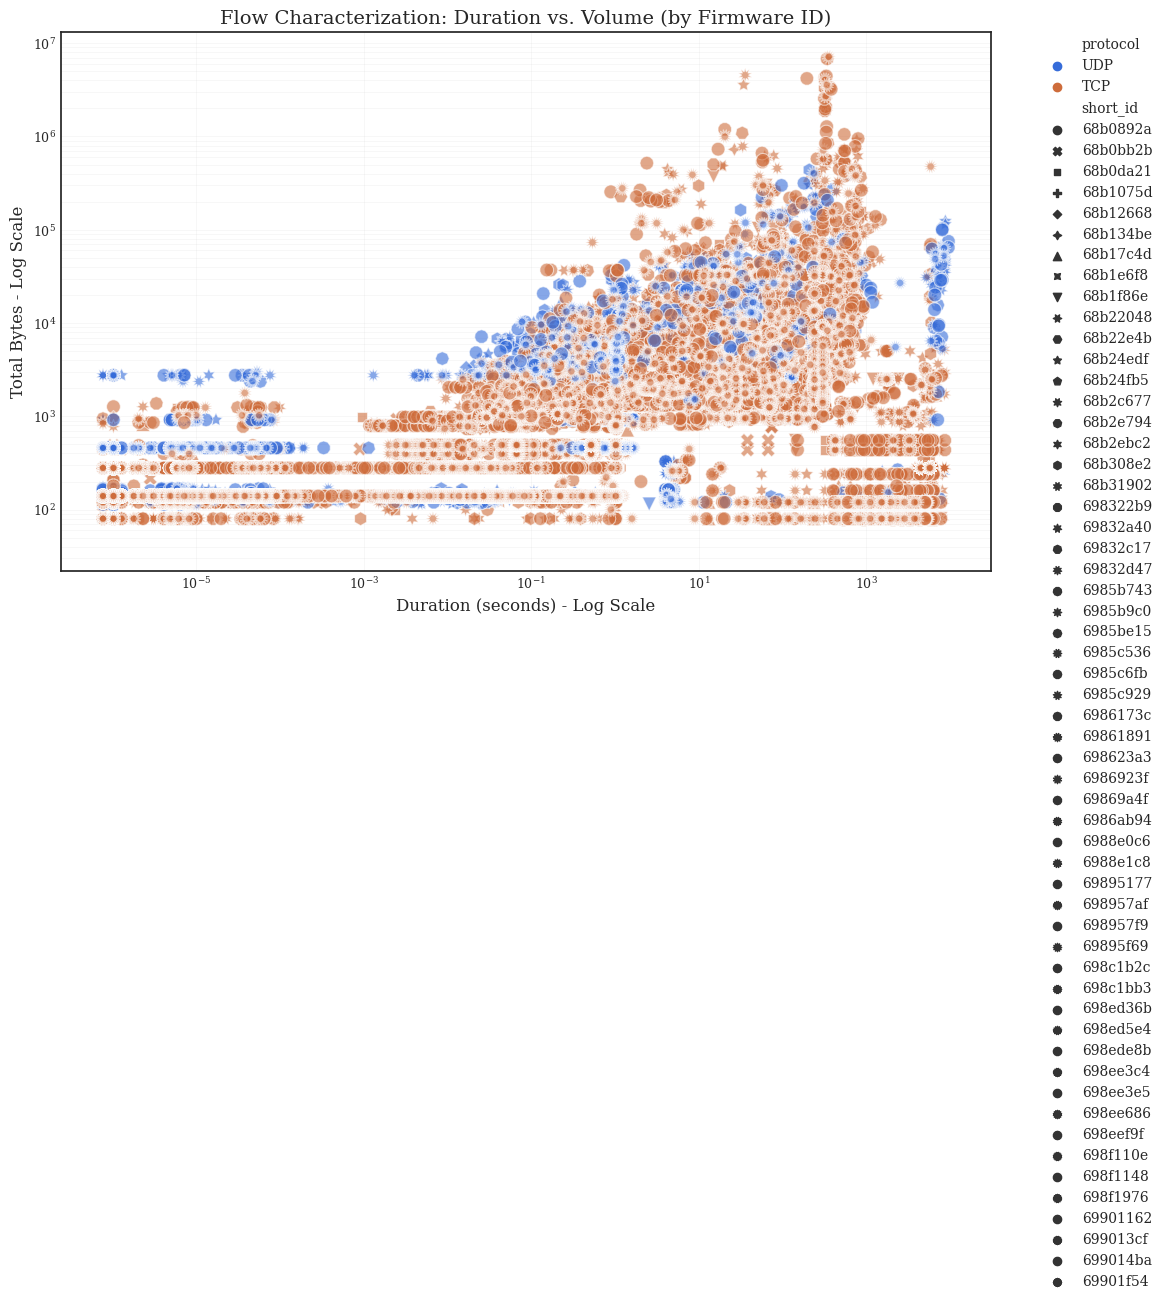

In [30]:
# 1. Create the short_id (First 8 characters)
flow_df['short_id'] = flow_df['firmware_id'].str[:8]

# 2. Plotting
plt.figure(figsize=(12, 7)) # Slightly wider to accommodate the legend
sns.scatterplot(
    data=flow_df,
    x='duration_sec',
    y='total_bytes',
    hue='protocol',
    style='short_id',  # Changed from firmware_id
    alpha=0.6,
    s=100              # Increased point size for better visibility in papers
)

plt.xscale('log')
plt.yscale('log')

# Adding scientific formatting
plt.title("Flow Characterization: Duration vs. Volume (by Firmware ID)", fontsize=14)
plt.xlabel("Duration (seconds) - Log Scale", fontsize=12)
plt.ylabel("Total Bytes - Log Scale", fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.2)

# Move legend outside of the plot so it doesn't cover data points
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()

/Users/tom/Documents/02_INIT/06_Sand/venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


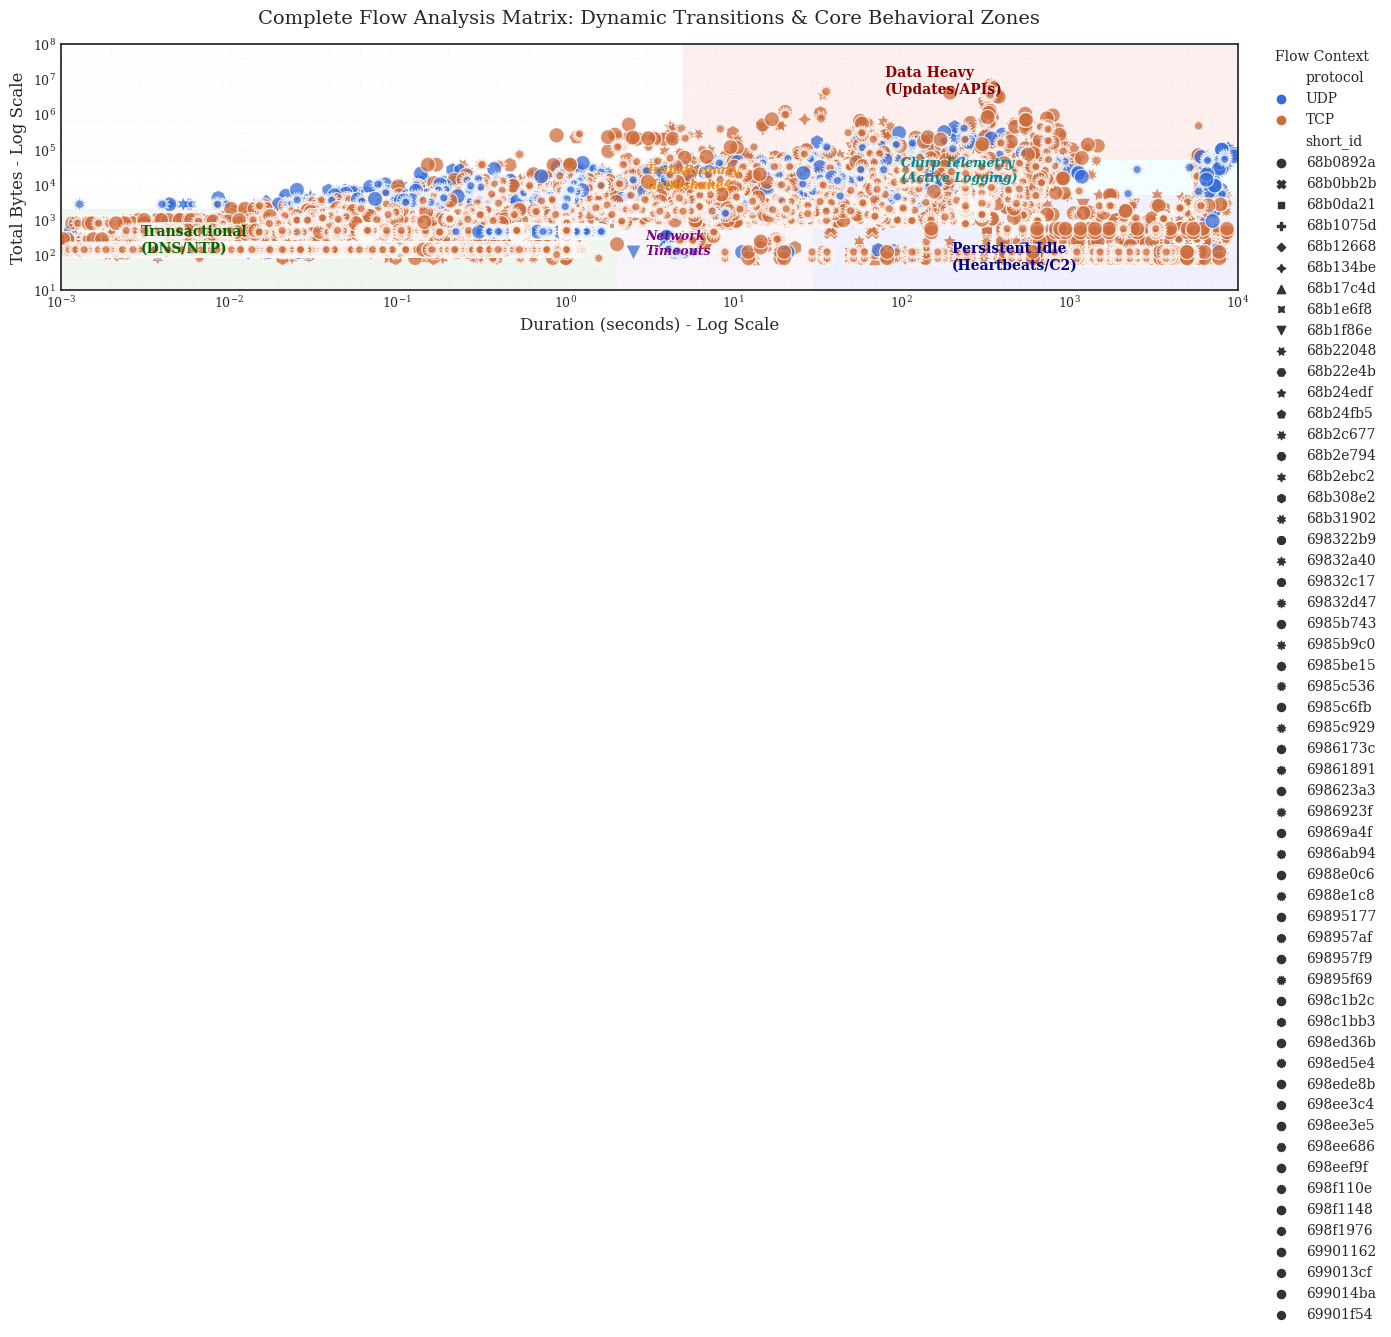

In [31]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

# 1. Create the short_id
flow_df['short_id'] = flow_df['firmware_id'].str[:8]

# 2. Setup Plot
fig, ax = plt.subplots(figsize=(14, 9))

# 3. OVERLAY ALL BEHAVIORAL ZONES (Drawn first so data stays on top)
# Core Zone A: Transactional (Bottom-Left)
rect_ephemeral = patches.Rectangle((0.001, 10), 1.999, 1990,
                                  linewidth=0, facecolor='green', alpha=0.06)
ax.add_patch(rect_ephemeral)

# Core Zone B: Heavy Data Transfer (Top-Right)
rect_heavy = patches.Rectangle((5, 50000), 100000, 1000000000,
                              linewidth=0, facecolor='red', alpha=0.06)
ax.add_patch(rect_heavy)

# Core Zone C: Persistent Idle Floor (Bottom-Right)
rect_persistent = patches.Rectangle((30, 10), 100000, 4990,
                                    linewidth=0, facecolor='blue', alpha=0.06)
ax.add_patch(rect_persistent)

# Inter-Zone 1: Transitionary/Handshake Space (Diagonal path from A to B)
rect_transition = patches.Rectangle((2, 2000), 28, 48000,
                                    linewidth=0, facecolor='orange', alpha=0.04)
ax.add_patch(rect_transition)

# Inter-Zone 2: Network Timeout / Stalled Handshakes (Horizontal gap between A and C)
rect_timeout = patches.Rectangle((2, 10), 28, 1990,
                                 linewidth=0, facecolor='purple', alpha=0.04)
ax.add_patch(rect_timeout)

# Inter-Zone 3: Chirp Telemetry / Active Sockets (Vertical gap between B and C)
rect_chirp = patches.Rectangle((30, 5000), 100000, 45000,
                               linewidth=0, facecolor='cyan', alpha=0.04)
ax.add_patch(rect_chirp)


# 4. PLOT THE ACTUAL SCATTER DATA
sns.scatterplot(
    data=flow_df,
    x='duration_sec',
    y='total_bytes',
    hue='protocol',
    style='short_id',
    alpha=0.75,
    s=120,
    ax=ax
)

# 5. FORCE LOG-LOG AXES & SPECIFY BOUNDARIES
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.001, 10000)
ax.set_ylim(10, 100000000)


# 6. TEXT ANNOTATIONS FOR THE NEWLY DEFINED SPACES
# Core Labels
ax.text(0.003, 120, "Transactional\n(DNS/NTP)", color='darkgreen', fontsize=10, weight='bold')
ax.text(80, 4000000, "Data Heavy\n(Updates/APIs)", color='darkred', fontsize=10, weight='bold')
ax.text(200, 40, "Persistent Idle\n(Heartbeats/C2)", color='darkblue', fontsize=10, weight='bold')

# Intermediate/Transition Labels
ax.text(3, 8000, "Transitionary\nHandshakes", color='darkorange', fontsize=9, style='italic', weight='semibold')
ax.text(3, 100, "Network\nTimeouts", color='purple', fontsize=9, style='italic', weight='semibold')
ax.text(100, 12000, "Chirp Telemetry\n(Active Logging)", color='darkcyan', fontsize=9, style='italic', weight='semibold')


# 7. FORMATTING & LEGEND
plt.title("Complete Flow Analysis Matrix: Dynamic Transitions & Core Behavioral Zones", fontsize=14, pad=15)
plt.xlabel("Duration (seconds) - Log Scale", fontsize=12)
plt.ylabel("Total Bytes - Log Scale", fontsize=12)
plt.grid(True, which="both", ls=":", alpha=0.2)

# Move tracking legend outside
plt.legend(title="Flow Context", bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.tight_layout()
plt.show()

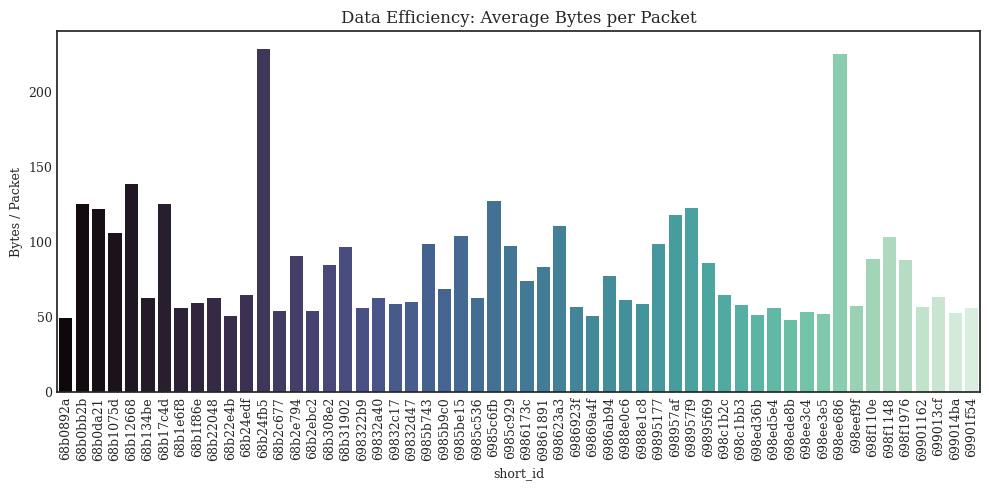

In [32]:
# DNS Entropy & Domain Characterization
# Aggregate by Firmware
intensity = flow_df.groupby('short_id').agg({
    'total_bytes': 'sum',
    'packet_count': 'sum',
    'duration_sec': 'sum'
})
intensity['byte_efficiency'] = intensity['total_bytes'] / intensity['packet_count']

# Plotting the Efficiency
plt.figure(figsize=(10, 5))
sns.barplot(data=intensity.reset_index(), x='short_id', y='byte_efficiency', palette='mako')
plt.xticks(rotation=90)
plt.title("Data Efficiency: Average Bytes per Packet")
plt.ylabel("Bytes / Packet")
plt.show()

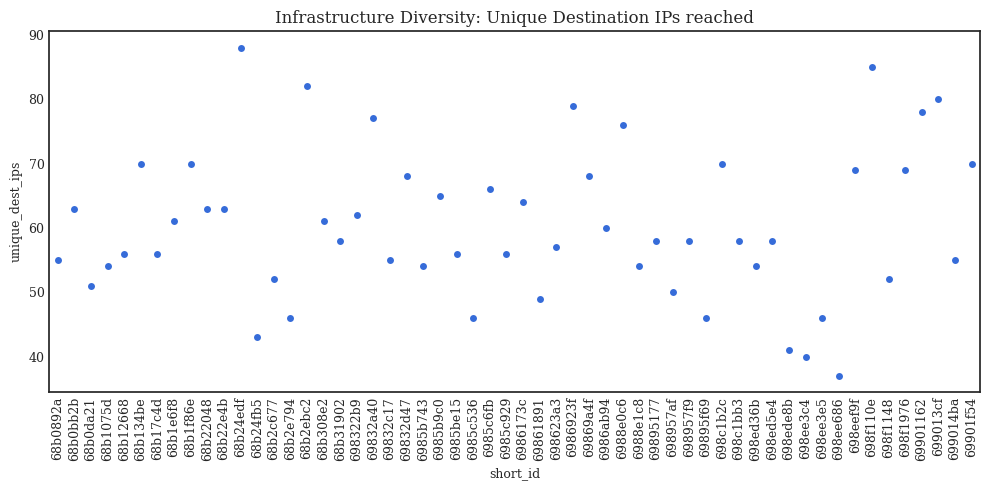

In [33]:
# Port "Surface Area" Analysis
# Calculate unique destinations per firmware
dest_diversity = flow_df.groupby('short_id')['dst_ip'].nunique().reset_index(name='unique_dest_ips')

plt.figure(figsize=(10, 5))
sns.swarmplot(data=dest_diversity, x='short_id', y='unique_dest_ips')
plt.xticks(rotation=90)
plt.title("Infrastructure Diversity: Unique Destination IPs reached")
plt.show()

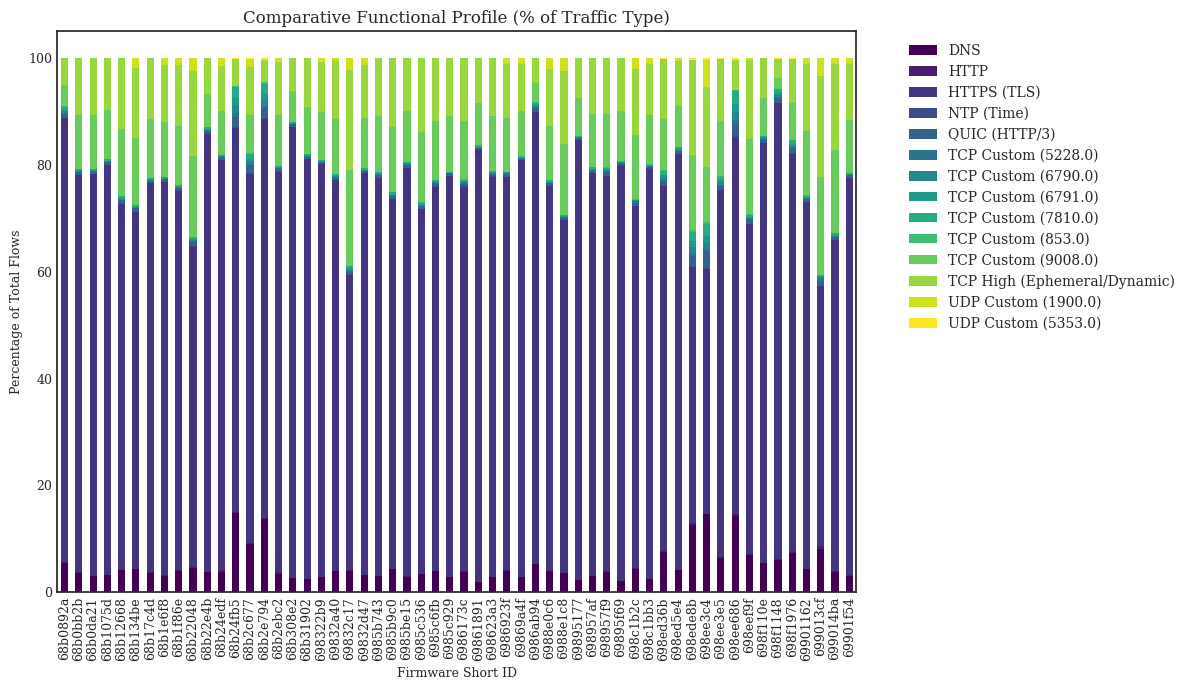

In [34]:
# 1. Re-apply the classification to flow_df
# Since a flow is defined by its port/protocol, we can classify it directly
flow_df['service_category'] = flow_df.apply(extended_classify, axis=1)

# 2. Re-apply the short_id just in case
flow_df['short_id'] = flow_df['firmware_id'].str[:8]

# 3. Now run the pivot - this should work perfectly now
service_pivot = pd.crosstab(flow_df['short_id'], flow_df['service_category'], normalize='index') * 100

# 4. Plot
service_pivot.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='viridis')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Comparative Functional Profile (% of Traffic Type)")
plt.ylabel("Percentage of Total Flows")
plt.xlabel("Firmware Short ID")
plt.tight_layout()
plt.show()

In [35]:
# Detecting Statistical Outliers (Z-Score Analysis)
# Calculate Z-Scores for total bytes per firmware
stats = flow_df.groupby('short_id')['total_bytes'].sum().reset_index()
stats['z_score'] = (stats['total_bytes'] - stats['total_bytes'].mean()) / stats['total_bytes'].std()

# Flag anything with a Z-score > 2 (statistically significant outlier)
outliers = stats[stats['z_score'].abs() > 2]
print("Behavioral Outliers detected:")
print(outliers)

Behavioral Outliers detected:
    short_id  total_bytes   z_score
11  68b24edf     18109384  3.135016
15  68b2ebc2     14024268  2.048193
31  6986923f     14676612  2.221745
40  698c1b2c     17357408  2.934957


In [36]:
# Aggregate multiple metrics to find different types of outliers
stats = flow_df.groupby('short_id').agg({
    'total_bytes': 'sum',
    'packet_count': 'sum',
    'src_port': 'count' # This counts the number of flows
}).rename(columns={'src_port': 'flow_count'})

# Calculate Z-scores for flow count and "chattiness" (packets per flow)
stats['z_flow_count'] = (stats['flow_count'] - stats['flow_count'].mean()) / stats['flow_count'].std()
stats['chattiness'] = stats['packet_count'] / stats['flow_count']
stats['z_chattiness'] = (stats['chattiness'] - stats['chattiness'].mean()) / stats['chattiness'].std()

# Check for outliers again (using a slightly more relaxed threshold of 1.5 if 2 is empty)
outliers = stats[(stats['z_flow_count'].abs() > 1.5) | (stats['z_chattiness'].abs() > 1.5)]
print("Multi-dimensional Outliers:")
print(outliers)

Multi-dimensional Outliers:
          total_bytes  packet_count  flow_count  z_flow_count  chattiness   
short_id                                                                    
68b24edf     18109384        278874       11022      1.508536   25.301579  \
68b24fb5       880269          3845         834     -2.113825    4.610312   
68b2c677      6740515        124792        2075     -1.672585   60.140723   
68b2e794      1231712         13589         837     -2.112758   16.235364   
69895177      7684682         77670       11341      1.621957    6.848602   
698ede8b      5498096        113691         936     -2.077559  121.464744   
698ee3c4     10523286        196452         666     -2.173558  294.972973   
698ee686       749228          3323         678     -2.169291    4.901180   

          z_chattiness  
short_id                
68b24edf      0.079140  
68b24fb5     -0.419661  
68b2c677      0.919002  
68b2e794     -0.139417  
69895177     -0.365702  
698ede8b      2.397330  
6

In [37]:
# Grouping the unique destination IPs by the short_id
unique_ips_by_fw = flow_df.groupby('short_id')['dst_ip'].unique()

for fw_id, ips in unique_ips_by_fw.items():
    print(f"\n--- Unique Destinations for Firmware: {fw_id} ---")
    print(f"Total Unique IPs: {len(ips)}")
    # Print the first 20 to keep the output readable
    for ip in sorted(ips)[:20]:
        print(f"  - {ip}")
    if len(ips) > 20:
        print(f"  ... and {len(ips) - 20} more.")


--- Unique Destinations for Firmware: 68b0892a ---
Total Unique IPs: 55
  - 10.0.2.3
  - 108.177.127.188
  - 127.0.0.1
  - 142.250.145.188
  - 142.251.150.119
  - 142.251.151.119
  - 142.251.151.4
  - 142.251.153.4
  - 142.251.154.119
  - 142.251.155.119
  - 142.251.156.119
  - 142.251.156.4
  - 142.251.157.119
  - 172.217.112.4
  - 172.217.113.4
  - 172.217.114.4
  - 172.217.115.4
  - 172.217.116.4
  - 172.217.117.4
  - 172.217.118.4
  ... and 35 more.

--- Unique Destinations for Firmware: 68b0bb2b ---
Total Unique IPs: 63
  - 10.0.2.3
  - 108.177.127.188
  - 127.0.0.1
  - 13.107.246.60
  - 142.251.127.84
  - 142.251.150.119
  - 142.251.150.4
  - 142.251.151.119
  - 142.251.152.119
  - 142.251.152.4
  - 142.251.153.119
  - 142.251.154.119
  - 142.251.155.119
  - 142.251.156.119
  - 142.251.157.119
  - 172.217.112.4
  - 172.217.113.4
  - 172.217.114.4
  - 172.217.115.4
  - 172.217.116.4
  ... and 43 more.

--- Unique Destinations for Firmware: 68b0da21 ---
Total Unique IPs: 51
  - 10

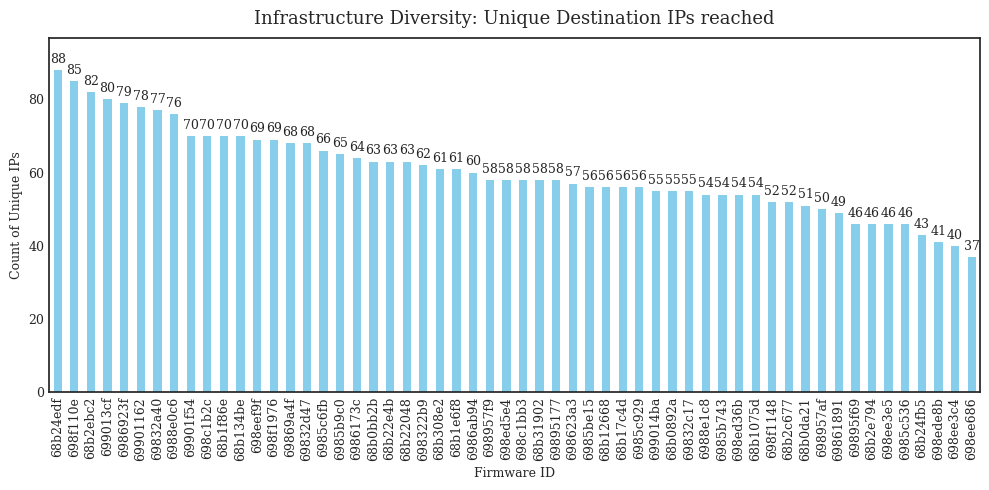

In [38]:
# Identifying "Unique Domains" (The Infrastructure Fingerprint)
# Who is talking to the most unique places?
unique_dst = flow_df.groupby('short_id')['dst_ip'].nunique().sort_values(ascending=False)

plt.figure(figsize=(10, 5))  # Slightly increased height to accommodate labels comfortably
ax = unique_dst.plot(kind='bar', color='skyblue')

# --- Add Values on Top of Bars ---
# padding=3 pushes the text slightly above the top edge of the bar
ax.bar_label(ax.containers[0], padding=3, fontsize=9)

plt.title("Infrastructure Diversity: Unique Destination IPs reached", fontsize=13, pad=10)
plt.ylabel("Count of Unique IPs")
plt.xlabel("Firmware ID")
plt.xticks(rotation=90)

# Adjust y-limits slightly so the highest label doesn't get cut off by the top border
plt.ylim(0, unique_dst.max() * 1.1)

plt.tight_layout()
plt.show()


In [39]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert the series back to a clean DataFrame for tabular presentation
unique_dst_table = unique_dst.reset_index()
unique_dst_table.columns = ['Firmware ID', 'Unique Destination IPs']

print("\n--- Infrastructure Diversity Table ---")
# Use display() if in Jupyter Notebook for pretty rendering, otherwise print()
try:
    from IPython.display import display
    display(unique_dst_table)
except ImportError:
    print(unique_dst_table.to_string(index=False))



--- Infrastructure Diversity Table ---


,Firmware ID,Unique Destination IPs
0,68b24edf,88
1,698f110e,85
2,68b2ebc2,82
3,699013cf,80
4,6986923f,79
5,69901162,78
6,69832a40,77
7,6988e0c6,76
8,69901f54,70
9,698c1b2c,70


In [40]:
# Identifying "Shared" vs "Unique" Infrastructure
# Identify IPs common to ALL firmware samples
all_ips_sets = [set(ips) for ips in unique_ips_by_fw]
common_ips = set.intersection(*all_ips_sets)

print(f"\nBaseline IPs (Contacted by all samples): {len(common_ips)}")
for ip in sorted(list(common_ips))[:10]:
    print(f"  - {ip} (Baseline)")

# Identify "Unique" IPs (contacted by ONLY one firmware)
all_ips_flat = [ip for sublist in unique_ips_by_fw for ip in sublist]
from collections import Counter
ip_counts = Counter(all_ips_flat)

unique_to_one = [ip for ip, count in ip_counts.items() if count == 1]
print(f"\nUnique 'Interest' IPs (Contacted by only 1 sample): {len(unique_to_one)}")


Baseline IPs (Contacted by all samples): 12
  - 10.0.2.3 (Baseline)
  - 127.0.0.1 (Baseline)
  - 172.217.112.4 (Baseline)
  - 172.217.113.4 (Baseline)
  - 172.217.114.4 (Baseline)
  - 172.217.115.4 (Baseline)
  - 172.217.116.4 (Baseline)
  - 172.217.117.4 (Baseline)
  - 172.217.118.4 (Baseline)
  - 172.217.119.4 (Baseline)

Unique 'Interest' IPs (Contacted by only 1 sample): 54


In [41]:
from collections import Counter
import pandas as pd

# Group by IP and count how many unique firmwares reached it
ip_fw_counts = flow_df.groupby('dst_ip')['short_id'].nunique()

# Filter for IPs where the count of unique firmwares is exactly 1
unique_ips_series = ip_fw_counts[ip_fw_counts == 1]
unique_ip_list = unique_ips_series.index.tolist()

print(f"\nUnique 'Interest' IPs (Contacted by only 1 sample): {len(unique_ip_list)}")

# 2. Map those unique IPs back to the single firmware that contacted them
# We filter the original dataframe to keep only rows containing those unique IPs
df_unique_mapping = flow_df[flow_df['dst_ip'].isin(unique_ip_list)][['short_id', 'dst_ip']].drop_duplicates()

# Sort the values so it looks organized by Firmware in the table
df_unique_mapping = df_unique_mapping.sort_values(by='short_id').reset_index(drop=True)
df_unique_mapping.columns = ['Firmware ID', 'Unique Destination IP']

# 3. Format and Display the Table
print("\n--- Unique Infrastructure Target Mapping Table ---")
try:
    from IPython.display import display
    display(df_unique_mapping)
except ImportError:
    print(df_unique_mapping.to_string(index=False))


Unique 'Interest' IPs (Contacted by only 1 sample): 54

--- Unique Infrastructure Target Mapping Table ---


,Firmware ID,Unique Destination IP
0,68b0bb2b,4.207.44.70
1,68b1075d,172.217.208.95
2,68b17c4d,13.89.179.15
3,68b17c4d,20.190.177.22
4,68b1e6f8,20.190.177.83
5,68b22e4b,52.168.117.171
6,68b24edf,20.190.177.21
7,68b24edf,20.42.73.30
8,68b24edf,40.126.53.8
9,68b24edf,83.150.25.25


In [42]:
flow_df.head()

,firmware_id,src_ip,dst_ip,src_port,dst_port,protocol,flow_start,flow_end,packet_count,total_bytes,avg_iat,std_iat,max_iat,avg_packet_len,duration_sec,short_id,version_label,service_category
0,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1164.0,53.0,UDP,2026-08-13 19:30:09.515471104,2026-08-13 19:30:09.515471104,1,70,NaN,NaN,NaN,70.0,0.0,68b0892a,68b0892a,DNS
1,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1229.0,53.0,UDP,2026-08-13 19:30:56.200891136,2026-08-13 19:30:56.200891136,1,84,NaN,NaN,NaN,84.0,0.0,68b0892a,68b0892a,DNS
2,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1423.0,53.0,UDP,2026-08-13 19:23:21.864461056,2026-08-13 19:23:21.864461056,1,63,NaN,NaN,NaN,63.0,0.0,68b0892a,68b0892a,DNS
3,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1953.0,53.0,UDP,2026-08-13 19:23:46.030247936,2026-08-13 19:23:46.030247936,1,75,NaN,NaN,NaN,75.0,0.0,68b0892a,68b0892a,DNS
4,68b0892a65e2ad36cfab2516_v12_sdk_phone64_arm64...,10.0.2.15,10.0.2.3,1998.0,53.0,UDP,2026-08-13 19:24:10.635081984,2026-08-13 19:24:10.635081984,1,61,NaN,NaN,NaN,61.0,0.0,68b0892a,68b0892a,DNS


In [43]:
#flow_df.columns()

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure you adjust 'requested_host' to match the exact column name in your flow_df
DOMAIN_COL = 'requested_host'

if DOMAIN_COL in flow_df.columns:
    # 1. Filter original flows for only the unique "Interest" IPs we isolated earlier
    df_unique_flows = flow_df[flow_df['dst_ip'].isin(unique_ip_list)]

    # 2. Extract the unique IP -> Domain pairs, dropping rows where domain extraction failed/blank
    df_domain_mapping = df_unique_flows[['short_id', 'dst_ip', DOMAIN_COL]].dropna().drop_duplicates()

    # 3. Count the total request frequency per domain to see who is talking the most
    domain_counts = df_unique_flows.groupby(DOMAIN_COL).size().sort_values(ascending=False).head(15)

    # 4. Plot the Domain Infrastructure Fingerprint
    plt.figure(figsize=(12, 6))
    ax = domain_counts.plot(kind='bar', color='coral')

    # Add values on top of the bars for scannability
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)

    plt.title("Infrastructure Fingerprint: Most Requested Unique Domains", fontsize=14, pad=12)
    plt.ylabel("Network Request Count (Flow Hits)")
    plt.xlabel("Resolved Domain Name")
    plt.xticks(rotation=45, ha='right')

    # Dynamic ceiling adjustment for top padding
    plt.ylim(0, domain_counts.max() * 1.1)
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # 5. Optional: Print an audit table showing exactly which firmware owns which domain
    print("\n--- Domain to Firmware Mapping Reference Table ---")
    df_audit = df_domain_mapping[['short_id', 'dst_ip', DOMAIN_COL]].copy()
    df_audit.columns = ['Firmware ID', 'Destination IP', 'Requested Domain']
    display(df_audit.sort_values(by='Firmware ID').reset_index(drop=True))

else:
    print(f"Error: Could not find domain column '{DOMAIN_COL}' in your DataFrame.")
    print(f"Available columns are: {list(flow_df.columns)}")


Error: Could not find domain column 'requested_host' in your DataFrame.
Available columns are: ['firmware_id', 'src_ip', 'dst_ip', 'src_port', 'dst_port', 'protocol', 'flow_start', 'flow_end', 'packet_count', 'total_bytes', 'avg_iat', 'std_iat', 'max_iat', 'avg_packet_len', 'duration_sec', 'short_id', 'version_label', 'service_category']


In [45]:
# 1. Install the Python packages safely using the current executable
!{sys.executable} -m pip install playwright pillow imagehash pandas

# 2. Install the lightweight browser binaries required by playwright
!{sys.executable} -m playwright install chromium
!{sys.executable} -m pip install duckdb

In [46]:
import os
import asyncio
import shutil
from playwright.async_api import async_playwright
from PIL import Image
import imagehash
import pandas as pd


collect_screenshots = False
if collect_screenshots:
    # Define the screenshot folder path
    OUTPUT_DIR = "ip_screenshots"

    # =============================================================
    # NEW: Clear old screenshots before starting the analysis
    # =============================================================
    if os.path.exists(OUTPUT_DIR):
        print(f"Clearing old analysis assets from raw directory: '{OUTPUT_DIR}'...")
        # shutil.rmtree deletes the folder and every file inside it completely
        shutil.rmtree(OUTPUT_DIR)

    # Recreate the clean, empty directory
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    print(f"Clean workspace initialized at '{OUTPUT_DIR}/'. Ready for analysis.\n")

    # 1. Extract Target IPs paired with the exact Ports and Protocols they used in the flows
    df_targets = flow_df[['dst_ip', 'dst_port', 'protocol']].drop_duplicates()


    # 1. Extract Target IPs paired with the exact Ports and Protocols they used in the flows
    # This avoids guessing Port 80 for every destination
    df_targets = flow_df[['dst_ip', 'dst_port', 'protocol']].drop_duplicates()

    # Create target configurations
    target_configs = []
    for _, row in df_targets.iterrows():
        ip = row['dst_ip']
        port = int(row['dst_port'])
        proto_lower = str(row['protocol']).lower()

        # Skip private infrastructure safely
        if ip.startswith(('10.', '192.168.', '127.', '172.16.')):
            continue

        # Smart protocol schema assignment based on industry port standards
        if port == 443 or "tls" in proto_lower or "ssl" in proto_lower:
            url = f"https://{ip}:{port}"
        else:
            url = f"http://{ip}:{port}"

        target_configs.append({'ip': ip, 'port': port, 'url': url})

    # -------------------------------------------------------------
    # Step 1: Upgraded Async Screenshot Engine
    # -------------------------------------------------------------
    async def capture_precise_screenshots(targets, output_dir):
        ip_screenshot_map = {}

        async with async_playwright() as p:
            # Ignore HTTPS errors since self-signed development certs are common in firmware backends
            browser = await p.chromium.launch(headless=True)
            context = await browser.new_context(
                viewport={"width": 1280, "height": 720},
                ignore_https_errors=True  # CRITICAL: Stops blank pages caused by invalid SSL certs
            )

            for target in targets:
                ip = target['ip']
                port = target['port']
                url = target['url']

                page = await context.new_page()
                page.set_default_timeout(10000) # 10 second ceiling

                # Unique filename tracking both target components
                filename = f"{ip}_{port}.png"
                screenshot_path = os.path.join(output_dir, filename)

                print(f"Targeting: {url}")
                try:
                    # 'networkidle' waits until there are no network connections for at least 500ms.
                    # This prevents snapping a screenshot while the page is still a white loading screen.
                    await page.goto(url, wait_until="networkidle")

                    # Check if the body contains actual content to avoid saving blank screens
                    body_text = await page.inner_text("body")
                    if not body_text.strip():
                        print(f"  -> Warning: {url} returned an empty body canvas. Skipping.")
                        continue

                    await page.screenshot(path=screenshot_path)
                    ip_screenshot_map[f"{ip}:{port}"] = screenshot_path
                    print(f"  -> Captured precise screen: {filename}")

                except Exception as e:
                    print(f"  -> Skipped {url}: Connection dropped or timed out.")
                finally:
                    await page.close()

            await browser.close()
        return ip_screenshot_map

    # --- Run Notebook Automation ---
    print("--- Launching Port-Aligned Browser Automation ---")
    ip_paths = await capture_precise_screenshots(target_configs, OUTPUT_DIR)


    # -------------------------------------------------------------
    # Step 2: Perceptual Hashing & Verification
    # -------------------------------------------------------------
    print("\n--- Processing and Deduplicating Images ---")

    hash_records = []
    for target_key, path in ip_paths.items():
        try:
            img = Image.open(path)
            img_hash = imagehash.dhash(img)

            # Split back out for mapping properties
            ip, port = target_key.split(":")

            hash_records.append({
                'dst_ip': ip,
                'dst_port': int(port),
                'Screenshot Path': path,
                'Image Hash': str(img_hash)
            })
        except Exception as e:
            print(f"Error compiling hash profile for {target_key}: {e}")

    df_intel = pd.DataFrame(hash_records)

    if not df_intel.empty:
        # Deduplicate matching server landing layouts
        df_unique_visuals = df_intel.drop_duplicates(subset=['Image Hash'], keep='first')

        # Merge structural metrics back onto the original flow context
        df_final_filtered = flow_df.merge(df_unique_visuals, on=['dst_ip', 'dst_port'], how='inner')

        print(f"\nFiltered Visual Mapping Completed successfully.")
        print(f"Total unique socket endpoints analyzed: {len(df_intel)}")
        print(f"Distinct endpoints retained after stripping visual duplicates: {len(df_unique_visuals)}")

        # Preview clean structure
        display(df_final_filtered[['short_id', 'dst_ip', 'dst_port', 'protocol', 'Screenshot Path']].drop_duplicates())
    else:
        print("\nNo unique socket targets successfully rendered a visual layer.")

In [47]:
!{sys.executable} -m pip install ipwhois

In [48]:
import ipaddress
from ipwhois import IPWhois
import pandas as pd

def get_asn_info(ip_list):
    asn_cache = {}
    for ip in ip_list:
        try:
            # Parse the string into a real IP Address object
            ip_obj = ipaddress.ip_address(ip)

            # Scientifically sound verification
            if ip_obj.is_private or ip_obj.is_loopback or ip_obj.is_multicast:
                asn_cache[ip] = {'asn': 'Internal', 'org': 'Emulator/Private/Local'}
                continue

        except ValueError:
            # Handles malformed IP strings safely
            asn_cache[ip] = {'asn': 'Invalid', 'org': 'Malformed IP Address'}
            continue

        # If it survives the filters, it is a guaranteed public routable IP
        try:
            obj = IPWhois(ip)
            results = obj.lookup_rdap(depth=1)
            asn_cache[ip] = {
                'asn': results.get('asn', 'Unknown'),
                'org': results.get('network', {}).get('name', 'Unknown')
            }
        except Exception as e:
            asn_cache[ip] = {'asn': 'Error', 'org': f'Lookup Failed ({str(e)[:15]})'}

    return asn_cache

# Get unique IPs and perform lookup
unique_ips = flow_df['dst_ip'].unique()
ip_metadata = get_asn_info(unique_ips)

# Map back to flow_df
flow_df['asn'] = flow_df['dst_ip'].map(lambda x: ip_metadata[x]['asn'])
flow_df['org'] = flow_df['dst_ip'].map(lambda x: ip_metadata[x]['org'])

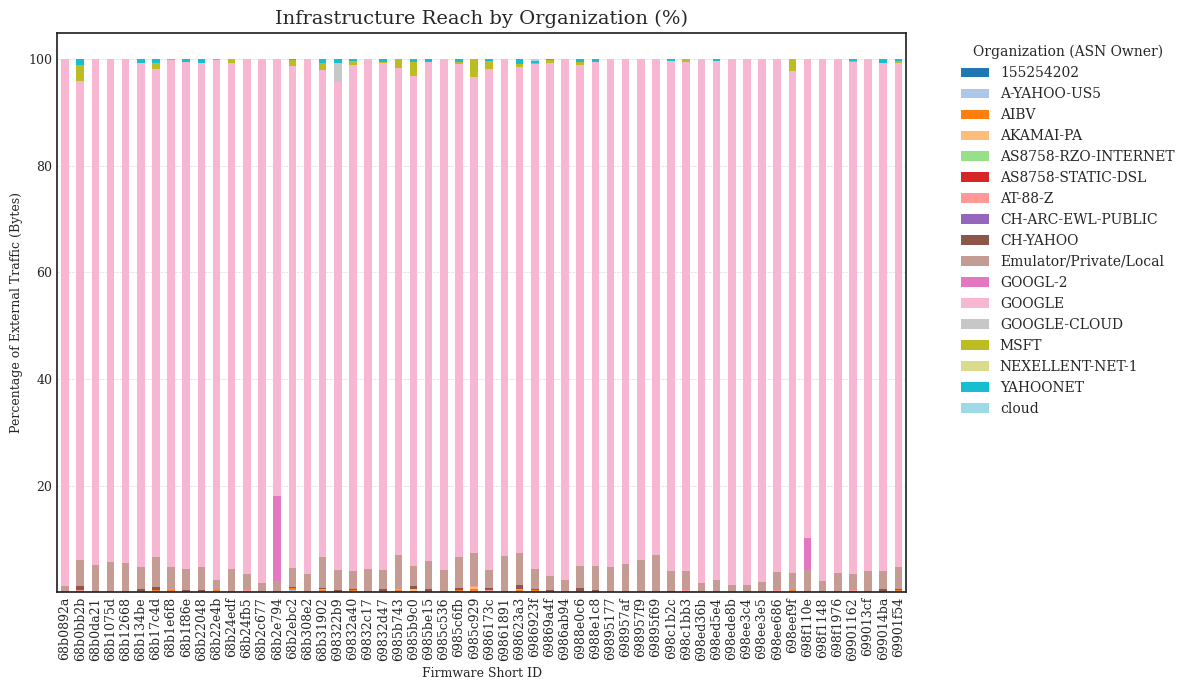

In [49]:
# Prepare the data: Group by Firmware and Organization
infra_stats = flow_df.groupby(['short_id', 'org'])['total_bytes'].sum().unstack(fill_value=0)

# Normalize by row (firmware) to show percentage of infrastructure reach
infra_pct = infra_stats.div(infra_stats.sum(axis=1), axis=0) * 100

# Plotting with Matplotlib/Pandas (Guaranteed to show)
plt.figure(figsize=(12, 7))
infra_pct.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca())

plt.title("Infrastructure Reach by Organization (%)", fontsize=14)
plt.ylabel("Percentage of External Traffic (Bytes)")
plt.xlabel("Firmware Short ID")
plt.legend(title="Organization (ASN Owner)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save for publication
plt.savefig("infrastructure_reach_bars.pdf", format='pdf', dpi=300)
plt.show()

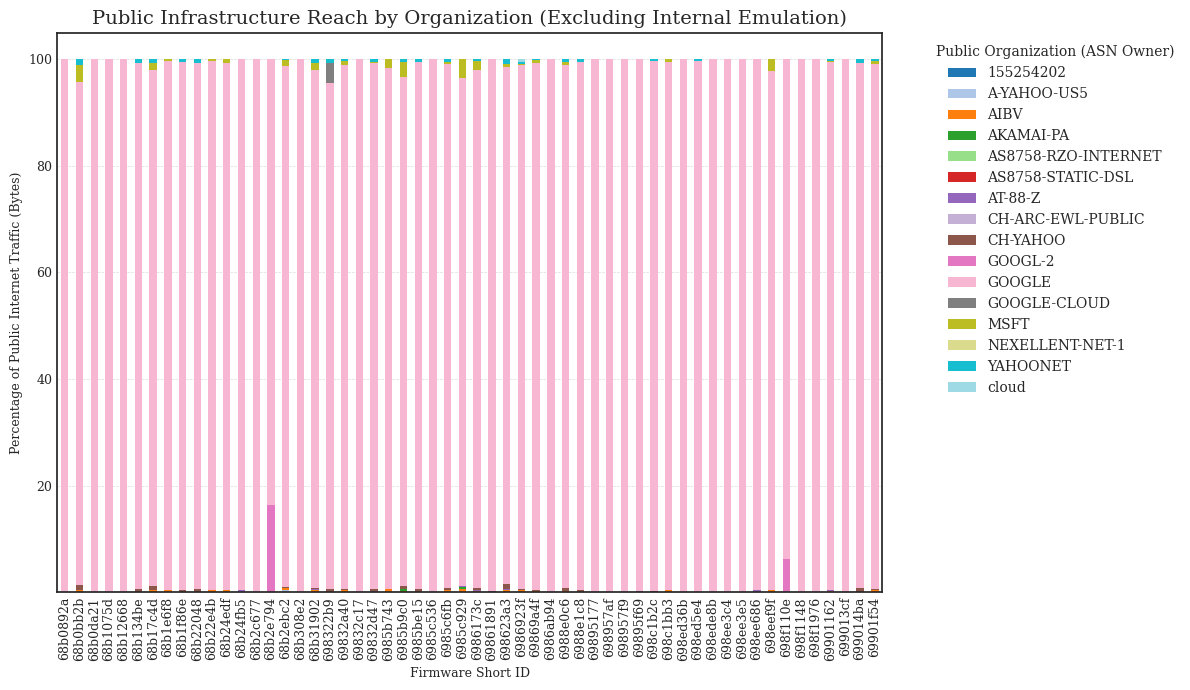

In [50]:
# 1. Prepare the raw data exactly like before
infra_stats = flow_df.groupby(['short_id', 'org'])['total_bytes'].sum().unstack(fill_value=0)

# ==========================================
# NEW STEP: Drop internal traffic if it exists
# ==========================================
if 'Emulator/Private/Local' in infra_stats.columns:
    infra_public_only = infra_stats.drop(columns=['Emulator/Private/Local'])
else:
    infra_public_only = infra_stats.copy()

# 2. Normalize the remaining PUBLIC traffic so the bars still hit exactly 100%
infra_public_pct = infra_public_only.div(infra_public_only.sum(axis=1), axis=0) * 100

# 3. Plotting the Public-Only Data
plt.figure(figsize=(12, 7))
infra_public_pct.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca())

plt.title("Public Infrastructure Reach by Organization (Excluding Internal Emulation)", fontsize=14)
plt.ylabel("Percentage of Public Internet Traffic (Bytes)")
plt.xlabel("Firmware Short ID")

# Dynamic legend placement for publication
plt.legend(title="Public Organization (ASN Owner)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save under a unique filename for your paper
plt.savefig("public_infrastructure_reach_bars.pdf", format='pdf', dpi=300)
plt.show()

In [51]:
!{sys.executable} -m pip install networkx

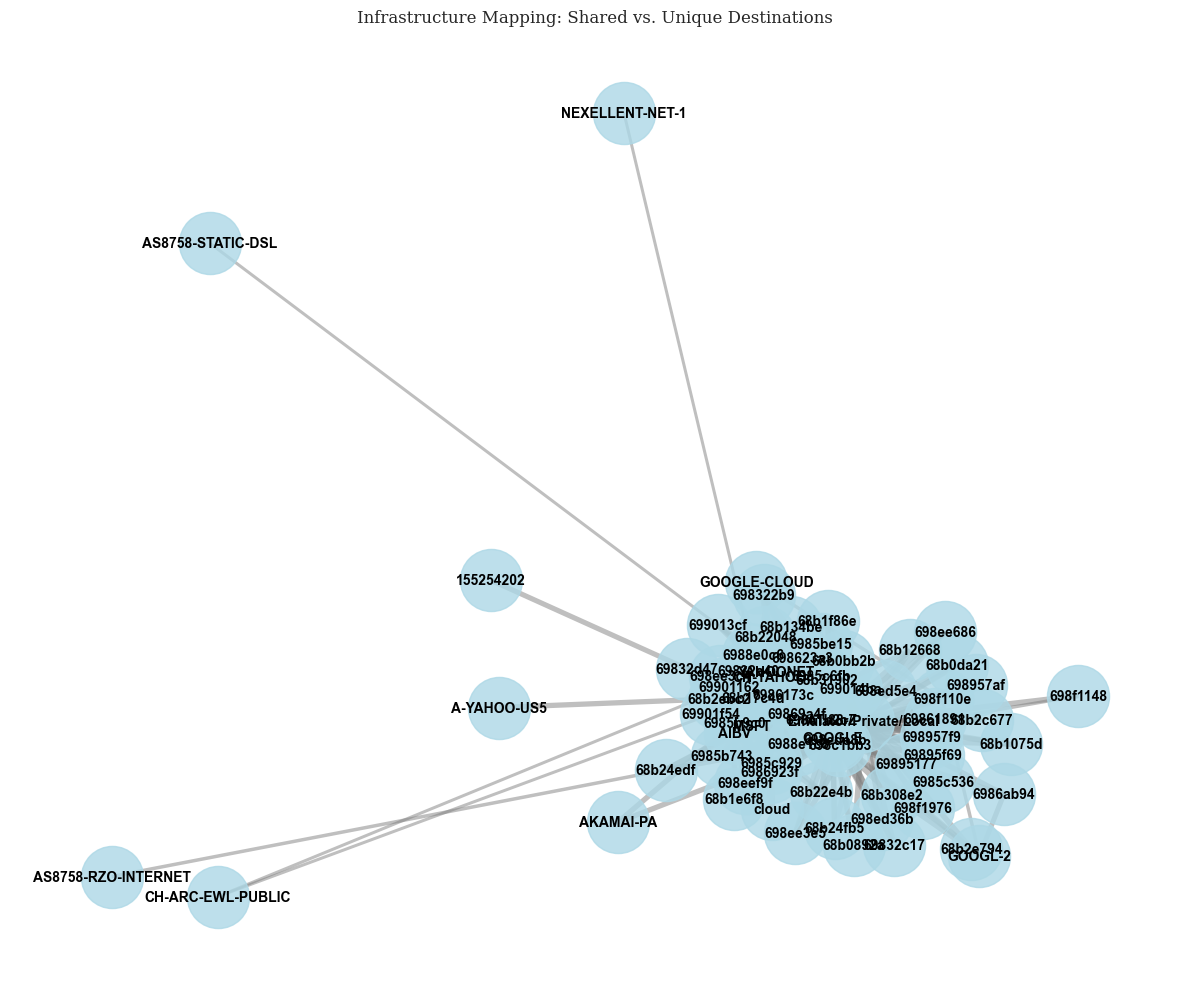

In [52]:
import networkx as nx

# Create a directed graph
G = nx.Graph()

# Add edges from Firmware to Organization
for _, row in flow_df.iterrows():
    G.add_edge(row['short_id'], row['org'], weight=row['total_bytes'])

# Plotting
plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=0.5) # k controls the distance between nodes

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='lightblue', alpha=0.8)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Draw edges (thickness based on traffic volume)
edges = G.edges(data=True)
weights = [np.log1p(d['weight']) / 2 for u, v, d in edges] # Log scale weights
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.5)

plt.title("Infrastructure Mapping: Shared vs. Unique Destinations")
plt.axis('off')
plt.show()

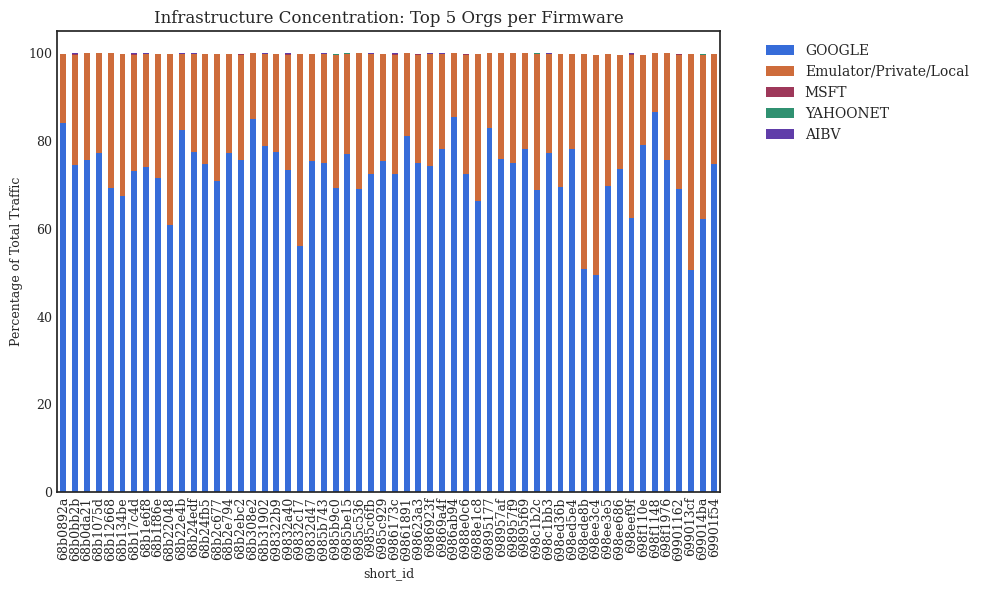

In [53]:
# Calculate ASN distribution per firmware
asn_dist = pd.crosstab(flow_df['short_id'], flow_df['org'], normalize='index') * 100

# Plotting the ASN Top 5 per Firmware
top_orgs = flow_df['org'].value_counts().nlargest(5).index
asn_dist[top_orgs].plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title("Infrastructure Concentration: Top 5 Orgs per Firmware")
plt.ylabel("Percentage of Total Traffic")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [54]:
# Protocol Distribution (The "Functional Fingerprint")
# Calculate the percentage of "High Port" or "Custom" traffic
proto_counts = pd.crosstab(flow_df['short_id'], flow_df['service_category'], normalize='index')

# Specifically look for 'TCP Custom' or 'High Port' traffic percentages
if 'TCP Custom' in proto_counts.columns:
    custom_traffic = proto_counts['TCP Custom'].sort_values(ascending=False)
    print("Firmware with highest percentage of non-standard TCP traffic:")
    print(custom_traffic)

/Users/tom/Documents/02_INIT/06_Sand/venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  fig.canvas.print_figure(bytes_io, **kw)


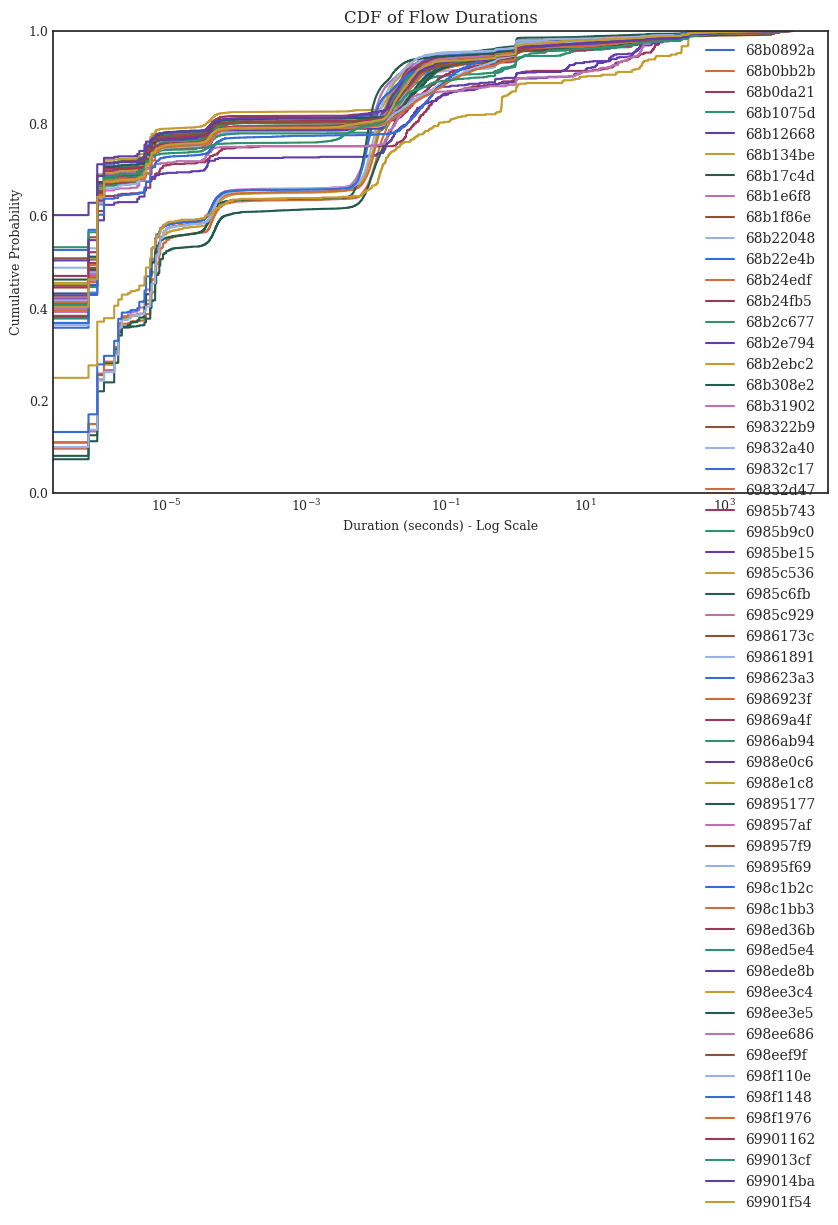

In [55]:
# Cumulative Distribution Function (CDF) of Flow Durations
# Plotting a CDF for flow duration
plt.figure(figsize=(10, 6))
for fid in flow_df['short_id'].unique():
    subset = flow_df[flow_df['short_id'] == fid]
    sns.ecdfplot(subset['duration_sec'], label=fid)

plt.xscale('log')
plt.title("CDF of Flow Durations")
plt.xlabel("Duration (seconds) - Log Scale")
plt.ylabel("Cumulative Probability")
plt.legend()
plt.show()

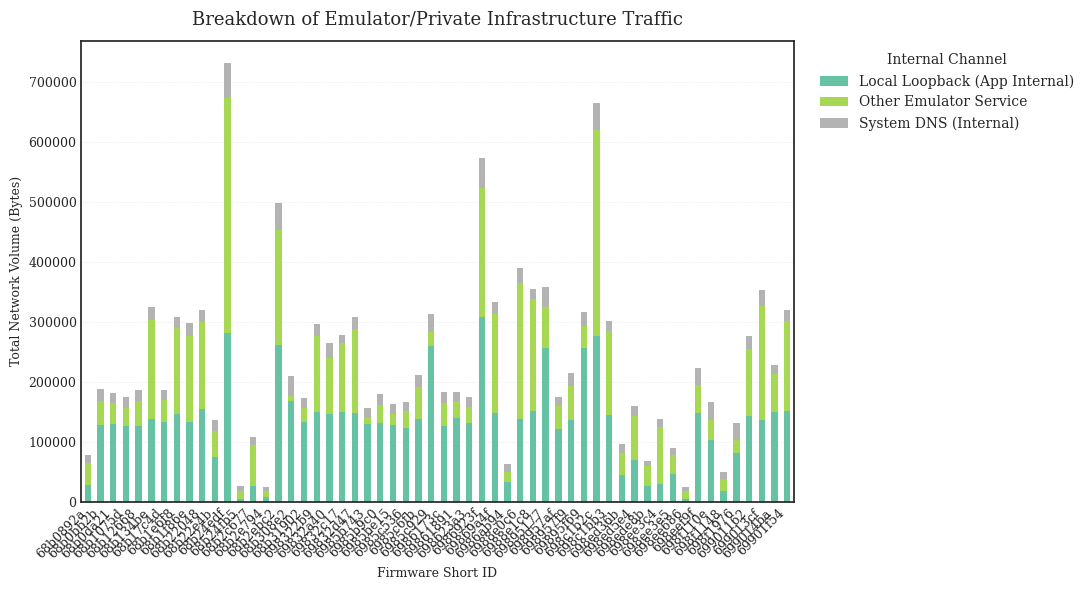

In [56]:
import matplotlib.pyplot as plt

# ==========================================================
# 1. FIXED FILTER: Match the updated string 'Emulator/Private/Local'
# ==========================================================
internal_df = flow_df[flow_df['org'] == 'Emulator/Private/Local'].copy()

# Failsafe check: if your previous script used a different name, catch it dynamically
if internal_df.empty:
    internal_df = flow_df[flow_df['org'].str.contains('Emulator|Private|Internal', case=False, na=False)].copy()

def sub_classify_internal(row):
    # QEMU / Android Emulator default host-loopback mapper mapping
    if row['dst_ip'] == '10.0.2.2' or row['src_ip'] == '10.0.2.2':
        return 'Host-Guest Bridge (ADB/Console)'
    if row['dst_ip'] == '10.0.2.3':
        return 'System DNS (Internal)'
    if row['dst_ip'] == '127.0.0.1' or row['src_ip'] == '127.0.0.1':
        return 'Local Loopback (App Internal)'
    return 'Other Emulator Service'

# Apply the classifier if data exists
if not internal_df.empty:
    internal_df['internal_type'] = internal_df.apply(sub_classify_internal, axis=1)

    # ==========================================================
    # 2. FIXED AGGREGATION: Added fill_value=0 to unstack
    # ==========================================================
    internal_counts = internal_df.groupby(['short_id', 'internal_type'])['total_bytes'].sum().unstack(fill_value=0)

    # Ensure values are strictly numeric types (float/int) before plotting
    internal_counts = internal_counts.astype(float)

    # 3. Plot the breakdown safely
    plt.figure(figsize=(11, 6))
    internal_counts.plot(kind='bar', stacked=True, colormap='Set2', ax=plt.gca())

    plt.title("Breakdown of Emulator/Private Infrastructure Traffic", fontsize=13, pad=12)
    plt.ylabel("Total Network Volume (Bytes)")
    plt.xlabel("Firmware Short ID")
    plt.xticks(rotation=45, ha='right')
    plt.legend(title="Internal Channel", bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(axis='y', linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("Warning: No internal/emulator flows found to plot. Verify the content of flow_df['org'].")

In [57]:
# Isolate the 'Other' internal traffic
other_internal = internal_df[internal_df['internal_type'] == 'Other Emulator Service']

# Find the top Destination Ports and Protocols
mystery_profile = other_internal.groupby(['dst_port', 'protocol']).agg({
    'total_bytes': 'sum',
    'packet_count': 'sum'
}).sort_values(by='total_bytes', ascending=False).head(10)

print("Top Ports in 'Other Emulator Service':")
print(mystery_profile)

Top Ports in 'Other Emulator Service':
                   total_bytes  packet_count
dst_port protocol                           
5353.0   UDP           3373105         26951
1900.0   UDP           1350225          8825


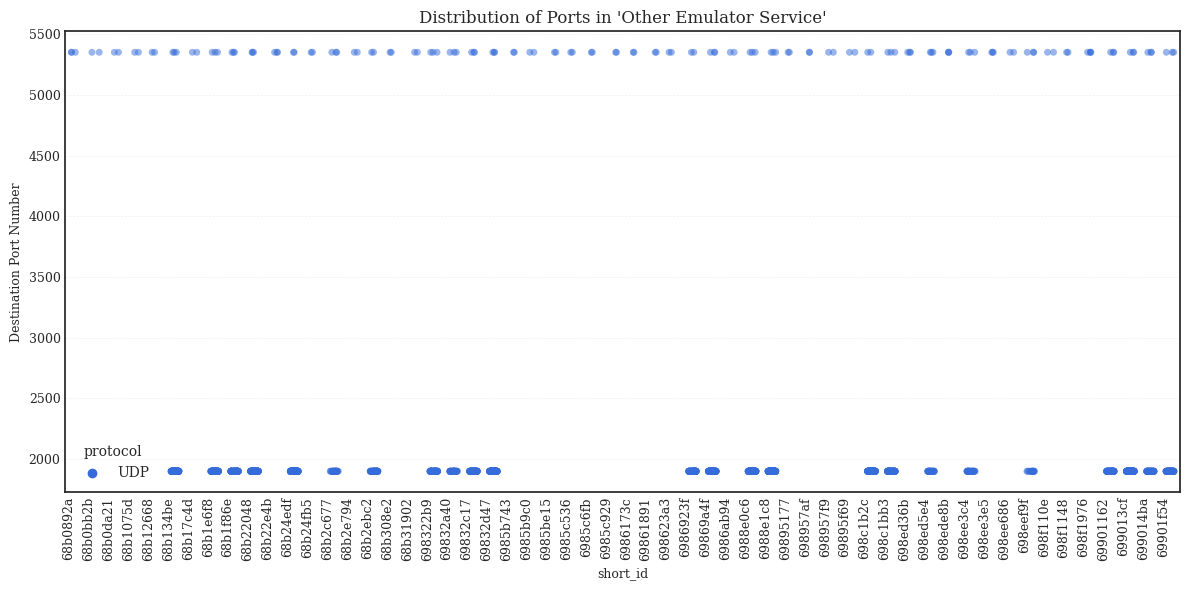

In [58]:
plt.figure(figsize=(12, 6))
sns.stripplot(data=other_internal, x='short_id', y='dst_port', hue='protocol', jitter=0.2, alpha=0.5)
plt.title("Distribution of Ports in 'Other Emulator Service'")
plt.ylabel("Destination Port Number")
plt.xticks(rotation=90, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

In [59]:
# Focus on these heavy-hitter mystery ports
mystery_ports = [47998, 47580, 37174, 35858]
diagnostic = internal_df[internal_df['dst_port'].isin(mystery_ports)]

# Check the Source Ports - This is the "Smoking Gun"
print("True Origin of Mystery Traffic (Source Ports):")
print(diagnostic.groupby('src_port').size().sort_values(ascending=False).head(10))

True Origin of Mystery Traffic (Source Ports):
src_port
9008.0    4
6791.0    1
dtype: int64


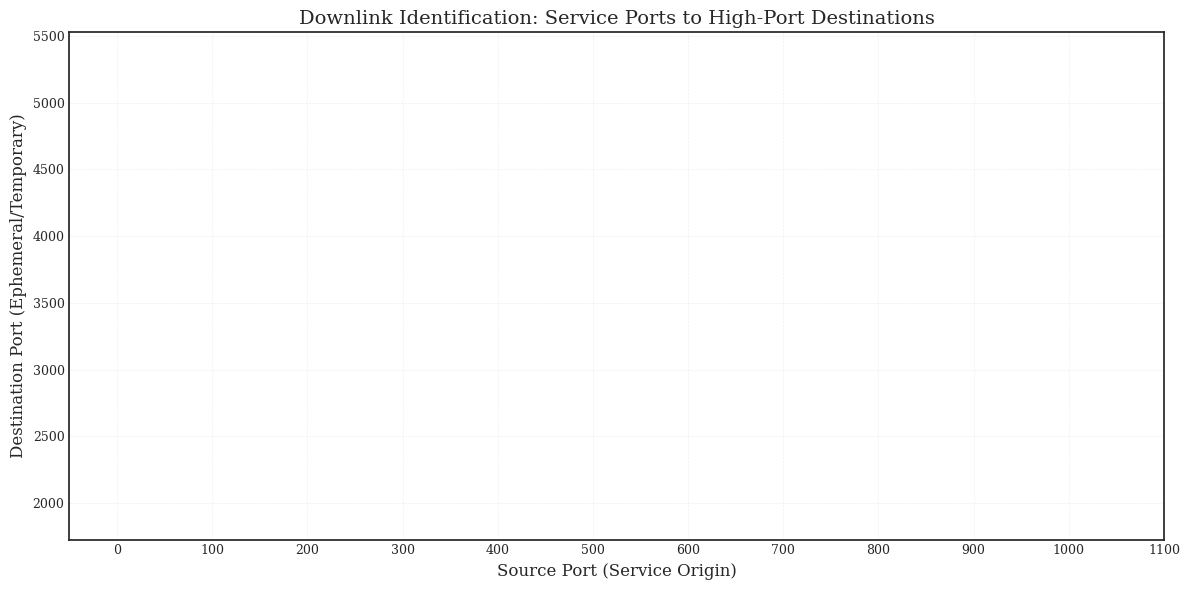

In [60]:
# Directional Downlink Flows refer to the movement of data from a remote server or host (the source) down to a local device or client (the destination).
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the top source ports for annotation
top_src_ports = other_internal.groupby('src_port')['total_bytes'].sum().nlargest(5).index

plt.figure(figsize=(12, 6))

# 2. Scatter plot with specialized sizing
scatter = plt.scatter(
    other_internal['src_port'],
    other_internal['dst_port'],
    s=other_internal['total_bytes']/500000, # Increased size scaling
    c=other_internal['src_port'],           # Color by port for visual grouping
    cmap='viridis',
    alpha=0.4,
    edgecolors='w',
    linewidth=0.5
)

# 3. Focus the X-axis on the "Service Port" range
plt.xlim(-50, 1100)
plt.xticks(range(0, 1101, 100))

# 4. Annotate the "Heavy Hitters"
for port in top_src_ports:
    # Find the average dst_port for this src_port to place the label
    y_pos = other_internal[other_internal['src_port'] == port]['dst_port'].mean()
    plt.annotate(f"Port {int(port)}",
                 xy=(port, y_pos),
                 xytext=(port+20, y_pos+1000),
                 arrowprops=dict(arrowstyle='->', color='black', lw=0.5),
                 fontsize=10, fontweight='bold')

plt.xlabel("Source Port (Service Origin)", fontsize=12)
plt.ylabel("Destination Port (Ephemeral/Temporary)", fontsize=12)
plt.title("Downlink Identification: Service Ports to High-Port Destinations", fontsize=14)
plt.grid(True, which="both", ls="--", alpha=0.3)

plt.tight_layout()
plt.show()

# DNS Analysis

In [61]:
# Isolate DNS flows
dns_df = flow_df[(flow_df['src_port'] == 53) | (flow_df['dst_port'] == 53)].copy()

# Add a specific DNS type for analysis
dns_df['dns_type'] = dns_df.apply(lambda x: 'Query (Outbound)' if x['dst_port'] == 53 else 'Response (Inbound)', axis=1)

print(f"Total DNS Flows: {len(dns_df)}")

Total DNS Flows: 14542


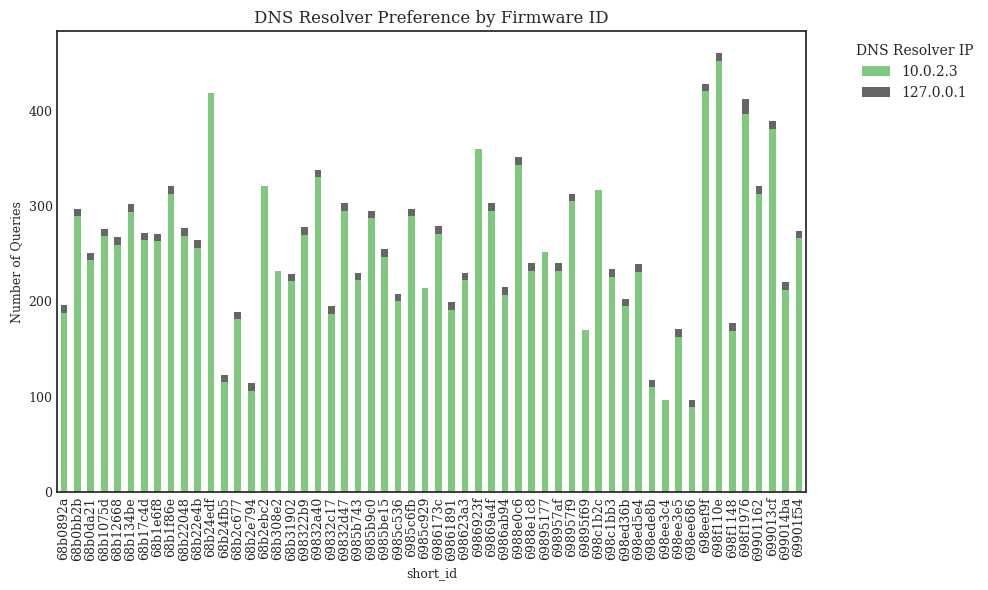

In [62]:
# DNS Infrastructure Analysis: "Who do you trust?"
# Identify the DNS Resolvers being used
resolvers = dns_df[dns_df['dns_type'] == 'Query (Outbound)'].groupby(['short_id', 'dst_ip']).size().unstack(fill_value=0)

# Visualize Resolver Preference
plt.figure(figsize=(10, 6))
resolvers.plot(kind='bar', stacked=True, colormap='Accent', ax=plt.gca())
plt.title("DNS Resolver Preference by Firmware ID")
plt.ylabel("Number of Queries")
plt.legend(title="DNS Resolver IP", bbox_to_anchor=(1.05, 1))
plt.show()

In [63]:
# Defining the "Binary Download" Heuristic
# Heuristic for potential binary/large file downloads
# We look for flows over 50KB that originate from web ports
min_binary_size = 50 * 1024  # 50 KB

binary_candidates = flow_df[
    (flow_df['total_bytes'] > min_binary_size) &
    ((flow_df['src_port'].isin([80, 443, 8080])) | (flow_df['dst_port'].isin([80, 443, 8080])))
].copy()

# Add a 'likely_binary' flag for your paper
binary_candidates['file_transfer_type'] = binary_candidates.apply(
    lambda x: 'Large Payload (HTTPS)' if x['protocol'] == 'HTTPS' else 'Insecure Binary (HTTP)',
    axis=1
)

print(f"Found {len(binary_candidates)} potential binary downloads.")

Found 542 potential binary downloads.


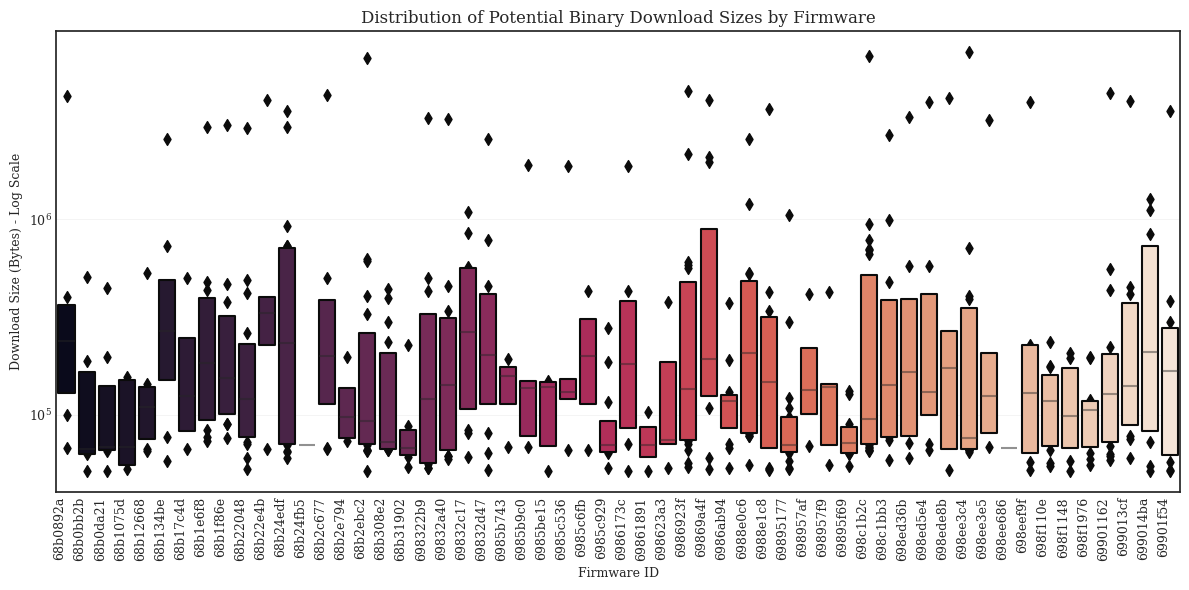

In [64]:
plt.figure(figsize=(12, 6))
sns.boxenplot(data=binary_candidates, x='short_id', y='total_bytes', palette='rocket')
plt.yscale('log')
plt.title("Distribution of Potential Binary Download Sizes by Firmware")
plt.ylabel("Download Size (Bytes) - Log Scale")
plt.xlabel("Firmware ID")
plt.xticks(rotation=90, ha='right')
plt.grid(True, axis='y', alpha=0.3)
plt.show()

In [65]:
# Refining the Search: The "ELF Signature"
# Calculate packet density
binary_candidates['avg_pkt_size'] = binary_candidates['total_bytes'] / binary_candidates['packet_count']

# Focus on flows with packets near the MTU limit (~1400-1500 bytes)
elf_targets = binary_candidates[binary_candidates['avg_pkt_size'] > 1000]

print("Top 5 Firmware by likely ELF/Binary activity:")
print(elf_targets.groupby('short_id').size().sort_values(ascending=False))

Top 5 Firmware by likely ELF/Binary activity:
short_id
69895f69    7
68b308e2    5
69895177    4
698ee3c4    4
68b2ebc2    3
6985c929    3
68b24edf    2
698c1b2c    2
68b0bb2b    1
68b22048    1
6985b9c0    1
6986923f    1
698f1148    1
698f1976    1
dtype: int64


In [66]:
# Isolate the primary suspect's binary flows
suspect_id = '68af0f08'
suspect_binaries = elf_targets[elf_targets['short_id'] == suspect_id]

# Group by Organization and IP
infrastructure = suspect_binaries.groupby(['org', 'dst_ip']).agg({
    'total_bytes': 'sum',
    'packet_count': 'count'
}).rename(columns={'packet_count': 'flow_count'}).sort_values(by='total_bytes', ascending=False)

print(f"Top Sources for {suspect_id}:")
print(infrastructure)

Top Sources for 68af0f08:
Empty DataFrame
Columns: [total_bytes, flow_count]
Index: []


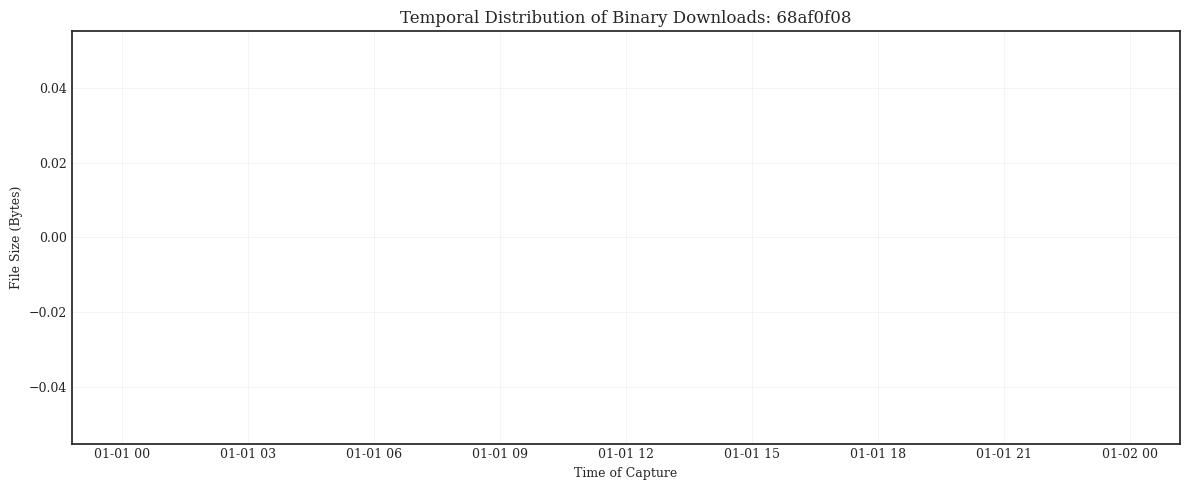

In [67]:
plt.figure(figsize=(12, 5))

# Plot the timeline of binary downloads
plt.scatter(suspect_binaries['flow_start'], suspect_binaries['total_bytes'],
            s=suspect_binaries['total_bytes']/10000, alpha=0.6, edgecolors='black')

plt.title(f"Temporal Distribution of Binary Downloads: {suspect_id}")
plt.xlabel("Time of Capture")
plt.ylabel("File Size (Bytes)")
plt.grid(True, alpha=0.3)
plt.show()

In [68]:
# The "HTTP vs. HTTPS" Security Check
security_check = suspect_binaries.groupby('protocol').size()
print(f"Security Profile for {suspect_id} downloads:")
print(security_check)

Security Profile for 68af0f08 downloads:
Series([], dtype: int64)


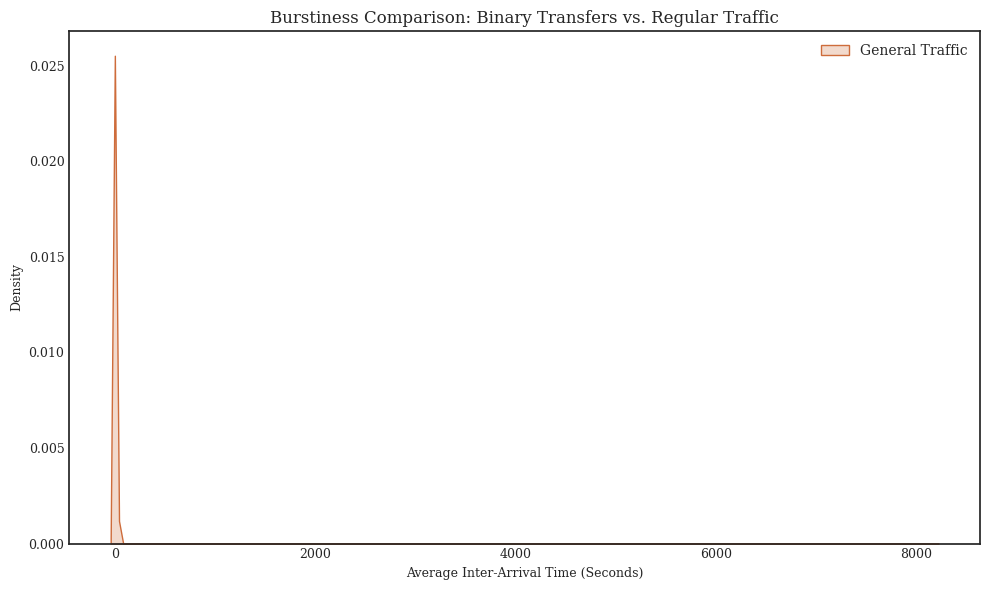

In [69]:
# Compare the "Burstiness" of the suspect vs the baseline
plt.figure(figsize=(10, 6))
sns.kdeplot(data=suspect_binaries, x='avg_iat', label="Binary Candidate Flows", fill=True)
sns.kdeplot(data=flow_df[flow_df['short_id'] != suspect_id], x='avg_iat', label="General Traffic", fill=True)

plt.title("Burstiness Comparison: Binary Transfers vs. Regular Traffic")
plt.xlabel("Average Inter-Arrival Time (Seconds)")
plt.legend()
plt.show()

UDP Binary Breakdown for 68af0f08:
Empty DataFrame
Columns: [total_bytes, avg_pkt_size]
Index: []


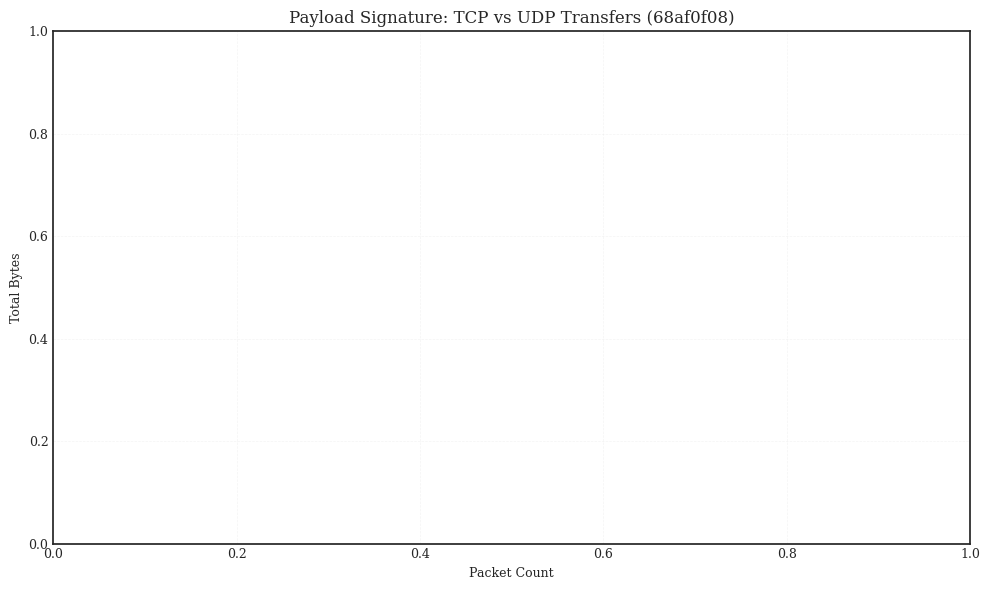

In [70]:
# Deep Dive: Unmasking the 16 UDP Flows
# Isolate the UDP candidates for the suspect firmware
suspect_udp_binaries = suspect_binaries[suspect_binaries['protocol'] == 'UDP']

# Check the ports and organizations
udp_detail = suspect_udp_binaries.groupby(['dst_port', 'org']).agg({
    'total_bytes': 'sum',
    'avg_pkt_size': 'mean'
}).sort_values(by='total_bytes', ascending=False)

print(f"UDP Binary Breakdown for {suspect_id}:")
print(udp_detail)

# Visualizing the "Payload Consistency"

plt.figure(figsize=(10, 6))
sns.scatterplot(data=suspect_binaries, x='packet_count', y='total_bytes',
                hue='protocol', style='protocol', s=100, alpha=0.7)

plt.title(f"Payload Signature: TCP vs UDP Transfers ({suspect_id})")
plt.xlabel("Packet Count")
plt.ylabel("Total Bytes")
plt.grid(True, which="both", ls="--", alpha=0.2)
plt.show()

In [71]:
# Extracting the Single Flow Profile
# Select the top flow from your list
test = False
if test:
    target_port = 41620.0
    single_flow = flow_df[(flow_df['dst_port'] == target_port) & (flow_df['short_id'] == '68af0f08')]

    print("--- Detailed Profile for Flow on Port 41620 ---")
    print(single_flow[['flow_start', 'flow_end', 'total_bytes', 'packet_count', 'avg_iat', 'service_category']].iloc[0])

    # Calculate Duration in seconds
    start = single_flow['flow_start'].iloc[0]
    end = single_flow['flow_end'].iloc[0]
    duration = (end - start).total_seconds() if end > start else 0.001 # prevent div by zero

    bytes_total = single_flow['total_bytes'].iloc[0]
    throughput_kbps = (bytes_total / 1024) / duration if duration > 0 else 0

    print(f"\nFlow Duration: {duration:.4f} seconds")
    print(f"Calculated Throughput: {throughput_kbps:.2f} KB/s")

    if throughput_kbps > 500:
        print("Likely Content: High-speed Binary/Asset Transfer (Burst)")
    else:
        print("Likely Content: Real-time Data/Logging Stream (Heartbeat)")

    # List of top ports we identified earlier
    target_ports = [41620, 39228, 36996, 52560, 34605, 44547]

    forensic_results = []

    for port in target_ports:
        # Isolate the flow
        f_data = flow_df[(flow_df['dst_port'] == port) & (flow_df['short_id'] == '68af0f08')].iloc[0]

        # Calculations
        duration = (f_data['flow_end'] - f_data['flow_start']).total_seconds()
        duration = max(duration, 0.001) # Avoid zero
        throughput = (f_data['total_bytes'] / 1024) / duration

        forensic_results.append({
            'Port': port,
            'Size (KB)': f_data['total_bytes'] / 1024,
            'Duration (s)': round(duration, 2),
            'Throughput (KB/s)': round(throughput, 2),
            'Avg IAT (ms)': round(f_data['avg_iat'] * 1000, 2),
            'Pkt Count': f_data['packet_count'],
            'Category': f_data['service_category']
        })

    # Convert to DataFrame for easy viewing
    forensic_df = pd.DataFrame(forensic_results)
    print(forensic_df)

    plt.figure(figsize=(10, 6))
    # X = Duration, Y = Throughput, Size = Total Bytes
    scatter = plt.scatter(
        forensic_df['Duration (s)'],
        forensic_df['Throughput (KB/s)'],
        s=forensic_df['Size (KB)'] * 5,
        alpha=0.6,
        c=forensic_df['Port'],
        cmap='viridis',
        edgecolors='black'
    )

    # Annotate each bubble with its port
    for i, txt in enumerate(forensic_df['Port']):
        plt.annotate(int(txt), (forensic_df['Duration (s)'][i], forensic_df['Throughput (KB/s)'][i] + 2))

    plt.title("Forensic Profiling: Suspect Flow Characteristics", fontsize=14)
    plt.xlabel("Duration (Seconds)")
    plt.ylabel("Throughput (KB/s)")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()


In [72]:
# Identifying "High-Probability" Downloads
# Calculate Density (Bytes per Second)
flow_df['byte_density'] = flow_df['total_bytes'] / (
    (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds().replace(0, 0.001)
)

# Identify flows that are:
# 1. Larger than 50KB (File-sized)
# 2. High density (> 100 KB/s)
# 3. Short-ish duration (Finished in under 30 seconds)
downloads = flow_df[
    (flow_df['total_bytes'] > 50000) &
    (flow_df['byte_density'] > 102400) &
    ((flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds() < 30)
]

print(f"Detected {len(downloads)} High-Probability File Downloads:")
print(downloads[['short_id', 'total_bytes', 'byte_density', 'service_category']])

Detected 8 High-Probability File Downloads:
        short_id  total_bytes   byte_density service_category
3168    68b0892a       254845  286528.093827      HTTPS (TLS)
78263   68b22e4b       225725  193164.478481      HTTPS (TLS)
88101   68b24edf       446330  105576.389284      HTTPS (TLS)
291789  69895f69        73158  136535.953669      HTTPS (TLS)
304546  698c1b2c       517930  216567.106595      HTTPS (TLS)
325447  698ede8b       266525  134336.036224      HTTPS (TLS)
333979  698eef9f       226805  126130.877418      HTTPS (TLS)
362865  699013cf       278605  228678.143624      HTTPS (TLS)


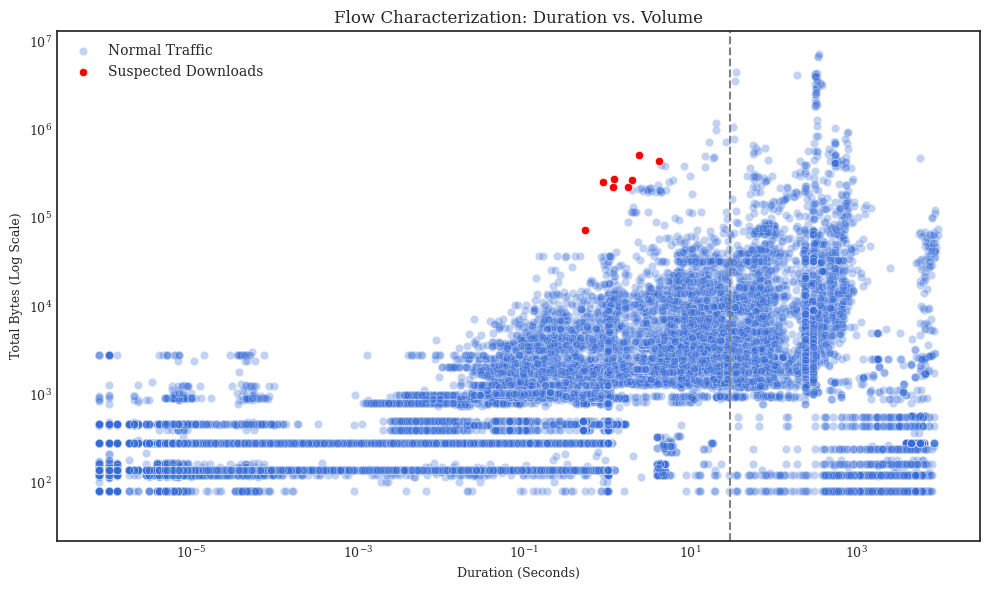

In [73]:
# Visualizing "Flow Density" (The Publication Figure)
plt.figure(figsize=(10, 6))

# Calculate duration for plotting
flow_df['duration_sec'] = (flow_df['flow_end'] - flow_df['flow_start']).dt.total_seconds()

# Plot all flows
sns.scatterplot(data=flow_df, x='duration_sec', y='total_bytes', alpha=0.3, label='Normal Traffic')

# Highlight the "Download" candidates
sns.scatterplot(data=downloads, x='duration_sec', y='total_bytes', color='red', label='Suspected Downloads')

plt.yscale('log') # Bytes vary wildly, log scale is better
plt.xscale('log')
plt.axvline(x=30, color='gray', linestyle='--') # 30s threshold
plt.title("Flow Characterization: Duration vs. Volume")
plt.xlabel("Duration (Seconds)")
plt.ylabel("Total Bytes (Log Scale)")
plt.legend()
plt.show()

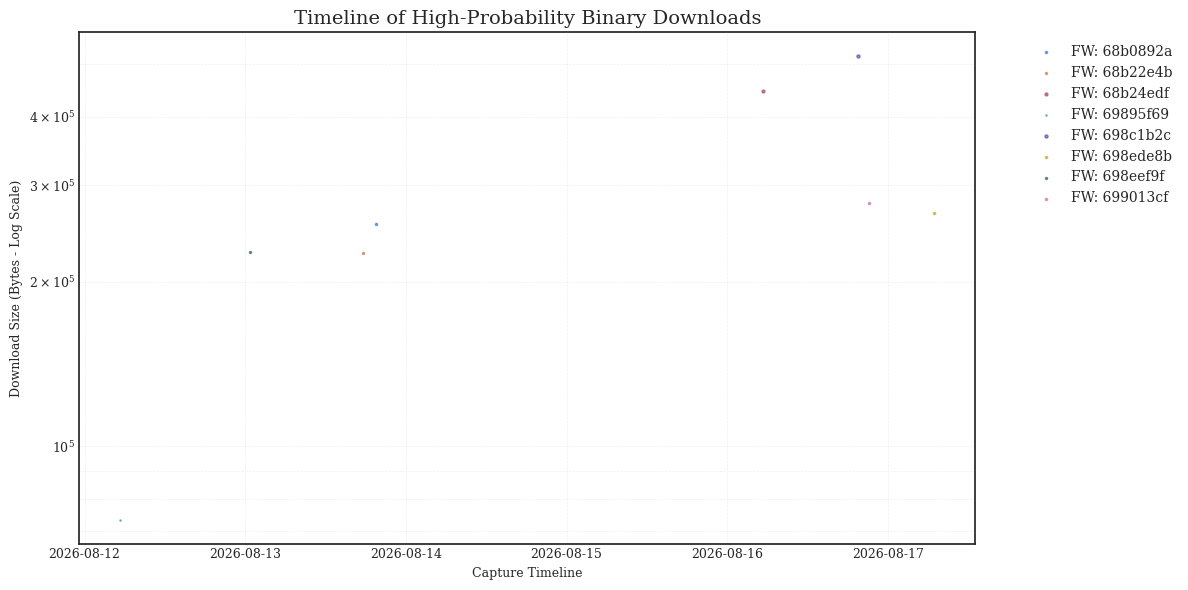

In [74]:
# Temporal Clustering
# Filter our list to just these 30 high-probability flows
top_flows_ids = downloads.index
target_df = flow_df.loc[top_flows_ids].copy()

plt.figure(figsize=(12, 6))
for fw_id in target_df['short_id'].unique():
    subset = target_df[target_df['short_id'] == fw_id]
    plt.scatter(subset['flow_start'], subset['total_bytes'],
                s=subset['total_bytes']/100000, label=f"FW: {fw_id}", alpha=0.6)

plt.yscale('log')
plt.title("Timeline of High-Probability Binary Downloads", fontsize=14)
plt.ylabel("Download Size (Bytes - Log Scale)")
plt.xlabel("Capture Timeline")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.show()

In [75]:
from ipwhois import IPWhois

# 1. Isolate the heavy hitters (>10MB)
heavy_hitters = downloads[downloads['total_bytes'] > 10000000].copy()

def get_dynamic_org(ip):
    try:
        # Check if we already have it in a global cache to save time/API hits
        res = IPWhois(ip).lookup_rdap()
        asn_num = res.get('asn', 'N/A')
        asn_org = res.get('asn_description', 'Unknown Org')
        return f"{asn_org} (AS{asn_num})"
    except:
        return "Unknown/Private"

# 2. Map IPs to Orgs dynamically
# We use .unique() to avoid redundant lookups for the same IP
unique_ips = heavy_hitters['dst_ip'].unique()
ip_to_org_map = {ip: get_dynamic_org(ip) for ip in unique_ips}

# 3. Apply the mapping
heavy_hitters['infrastructure_provider'] = heavy_hitters['dst_ip'].map(ip_to_org_map)

print("--- Dynamic Infrastructure Attribution ---")
print(heavy_hitters[['short_id', 'dst_ip', 'total_bytes', 'infrastructure_provider']])

--- Dynamic Infrastructure Attribution ---
Empty DataFrame
Columns: [short_id, dst_ip, total_bytes, infrastructure_provider]
Index: []


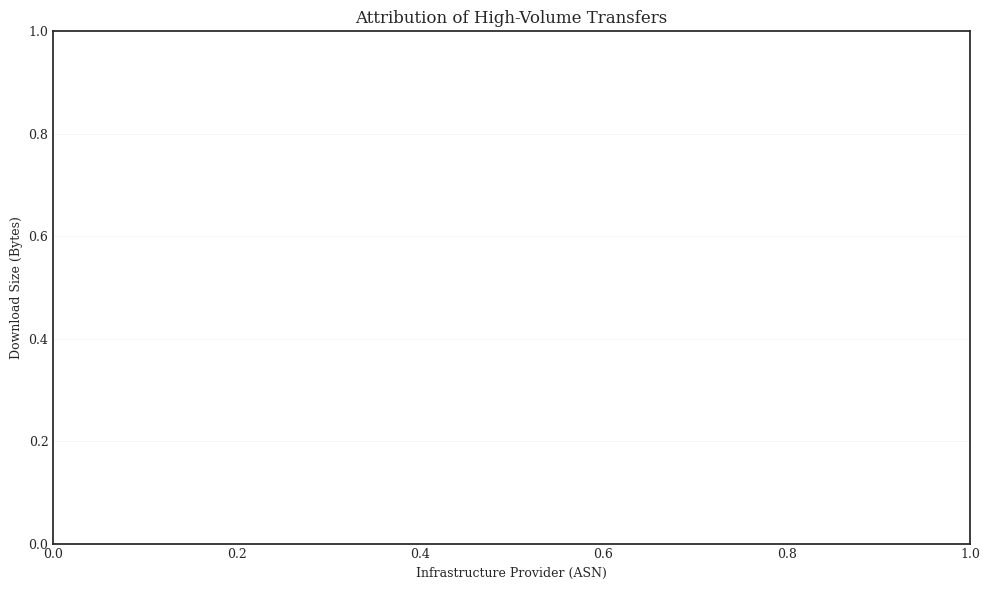

In [76]:
plt.figure(figsize=(10, 6))
# Plotting Organization vs. Download Size
sns.swarmplot(data=heavy_hitters, x='infrastructure_provider', y='total_bytes',
              hue='short_id', size=15, alpha=0.8)

plt.title("Attribution of High-Volume Transfers")
plt.ylabel("Download Size (Bytes)")
plt.xlabel("Infrastructure Provider (ASN)")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

TypeError: no numeric data to plot

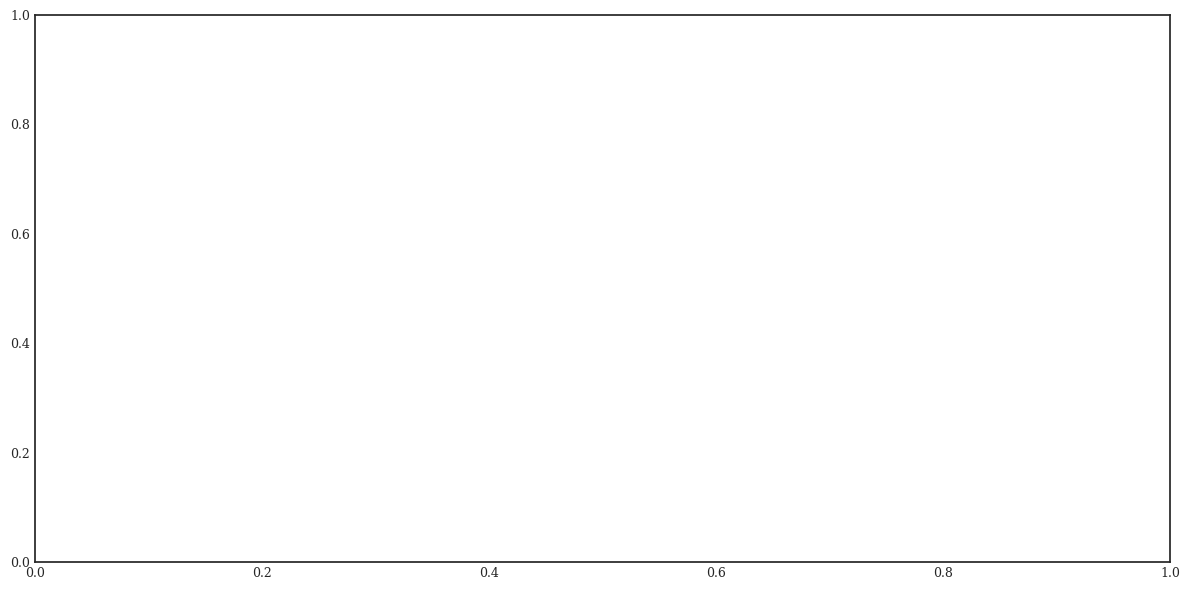

In [77]:
import matplotlib.pyplot as plt

# Grouping for visualization
plot_data = heavy_hitters.groupby(['short_id', 'infrastructure_provider'])['total_bytes'].sum().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
plot_data.plot(kind='barh', stacked=True, colormap='viridis', ax=plt.gca())

plt.title("Volume Attribution by Dynamically Identified Infrastructure", fontsize=14)
plt.xlabel("Total Bytes Downloaded")
plt.ylabel("Firmware ID")
plt.legend(title="ASN / Organization", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Select the heavy hitters
heavy_hitters = downloads[downloads['total_bytes'] > 10000000].copy()

# Categorize Local vs Global
def check_locality(ip):
    if ip.startswith(('10.', '192.168.', '172.16.', '127.')):
        return "Internal (Emulator/LAN)"
    return "External (WAN)"

heavy_hitters['locality'] = heavy_hitters['dst_ip'].apply(check_locality)

print("--- Forensic IP Report: Large Downloads ---")
cols = ['short_id', 'src_ip', 'dst_ip', 'dst_port', 'total_bytes', 'locality', 'service_category']
print(heavy_hitters[cols].sort_values(by='total_bytes', ascending=False))

In [ ]:
plt.figure(figsize=(10, 6))
# Create a pivot of Firmware vs Destination IP
ip_volume = heavy_hitters.pivot_table(index='short_id', columns='dst_ip', values='total_bytes', aggfunc='sum').fillna(0)

ip_volume.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca())
plt.title("Volume Distribution by Destination IP", fontsize=14)
plt.ylabel("Bytes Downloaded")
plt.xlabel("Firmware ID")
plt.legend(title="Destination IP", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the heavy hitter flows (>10MB)
heavy_hitters = downloads[downloads['total_bytes'] > 10000000].copy()

# 2. Add Locality Information for the plot
def get_locality(ip):
    if ip.startswith(('10.', '192.168.', '172.16.', '127.')):
        return "Internal"
    return "External"

heavy_hitters['Locality'] = heavy_hitters['src_ip'].apply(get_locality)

# 3. Summarize volume by Source IP and Firmware
src_stats = heavy_hitters.groupby(['src_ip', 'short_id', 'Locality'])['total_bytes'].sum().reset_index()
src_stats = src_stats.sort_values(by='total_bytes', ascending=False)

# 4. Plotting
plt.figure(figsize=(12, 7))
sns.barplot(data=src_stats, x='total_bytes', y='src_ip', hue='short_id', palette='magma')

# Customizing the scientific look
plt.xscale('log') # Log scale is essential for bytes
plt.title("Infrastructure Profiling: Source IP Volume Analysis", fontsize=15)
plt.xlabel("Total Data Transferred (Bytes - Log Scale)", fontsize=12)
plt.ylabel("Source IP Address (Server)", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend(title="Firmware ID", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.savefig("src_ip_attribution.png", dpi=300)
plt.show()

# 5. Print the Top 5 unique IPs for manual verification
print("Unique Download Source IPs:")
print(src_stats[['src_ip', 'Locality', 'total_bytes']].head(10))

In [ ]:
flow_df.head(5).to_clipboard(index=False)

In [ ]:
final_df.head(5).to_clipboard(index=False)

# PII Leakage Analysis

In [ ]:
import sys

# 1. Install specific versions that support Python 3.9
!{sys.executable} -m pip install "spacy>=3.7.0,<3.8.0" "thinc>=8.2.0,<8.3.0"

# 2. Install the rest of the tools
!{sys.executable} -m pip install presidio-analyzer pyshark

# 3. Download the model compatible with this spacy version
!{sys.executable} -m spacy download en_core_web_lg

!{sys.executable} -m pip install "packaging<24.0"

In [ ]:
import os
import re
import subprocess
import pandas as pd
from IPython.display import display

def sanitize_ssl_keylog(raw_keylog_path, clean_keylog_path):
    """
    Reads a potentially malformed/joined ecapture keylog file,
    injects correct newlines before TLS key labels, and writes a clean version.
    """
    with open(raw_keylog_path, 'r') as f:
        content = f.read()

    labels = [
        "CLIENT_RANDOM",
        "CLIENT_TRAFFIC_SECRET_0",
        "SERVER_TRAFFIC_SECRET_0",
        "EXPORTER_SECRET",
        "SERVER_HANDSHAKE_TRAFFIC_SECRET",
        "CLIENT_HANDSHAKE_TRAFFIC_SECRET"
    ]

    sanitized_content = content
    for label in labels:
        sanitized_content = re.sub(f"(?<!\\n){label}", f"\n{label}", sanitized_content)

    sanitized_content = "\n".join([line.strip() for line in sanitized_content.splitlines() if line.strip()])

    with open(clean_keylog_path, 'w') as f:
        f.write(sanitized_content + "\n")

def decrypt_pcap_via_tshark_cli(pcap_path, clean_keylog_path, short_id, firmware_folder):
    """
    Uses a direct, synchronous tshark CLI execution to safely bypass
    all Jupyter asyncio / event loop restrictions entirely.
    """
    records = []

    # CLI Command to extract fields from decrypted http data
    # -o tls.keylog_file: feeds the secrets to tshark
    # -Y http: display filter for decrypted HTTP traffic
    # -T fields -e ...: targets metadata fields and payload text
    cmd = [
        "tshark",
        "-r", pcap_path,
        "-o", f"tls.keylog_file:{clean_keylog_path}",
        "-Y", "http",
        "-T", "fields",
        "-e", "ip.src",
        "-e", "ip.dst",
        "-e", "tcp.dstport",
        "-e", "http.request.uri",
        "-e", "http.file_data"
    ]

    try:
        # Execute blocking CLI call natively
        result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, check=True)

        output_lines = result.stdout.strip().split("\n")
        decrypted_packet_count = 0

        for line in output_lines:
            if not line.strip():
                continue

            # Tshark fields are tab-separated (\t)
            parts = line.split("\t")

            # Fill missing array elements dynamically if trailing parameters don't exist
            while len(parts) < 5:
                parts.append("")

            src_ip, dst_ip, dst_port, req_uri, file_data = parts

            # Identify if either the URI string or the POST body data got populated
            payload_content = file_data.strip() if file_data.strip() else req_uri.strip()

            if payload_content:
                decrypted_packet_count += 1
                records.append({
                    'short_id': short_id,
                    'firmware_folder': firmware_folder,
                    'source_layer': 'Decrypted_HTTPS_CLI',
                    'src_ip': src_ip,
                    'dst_ip': dst_ip,
                    'dst_port': dst_port,
                    'raw_payload_text': payload_content
                })

        print(f"    --> SUCCESS: Extracted {decrypted_packet_count} decrypted data packets via tshark CLI.")

    except FileNotFoundError:
        print("    [!] Error: 'tshark' utility is not installed or missing from system PATH.")
    except subprocess.CalledProcessError as e:
        print(f"    [!] Tshark execution failed: {e.stderr}")

    return records

def run_pipeline_decryption_cli(df_flows):
    """
    Main orchestrator that dynamically pairs IDs to folders and handles clean CLI decryption.
    """
    decrypted_records = []
    base_dir = "./data/02_octopus/emulator_out/"

    if not os.path.exists(base_dir):
        print(f"[-] Base directory layout not found at target path: {base_dir}")
        return pd.DataFrame()

    available_folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f))]
    unique_short_ids = df_flows['short_id'].dropna().unique()

    print(f"=== Starting CLI-Based TLS Decryption Over {len(unique_short_ids)} Samples ===")

    for short_id in unique_short_ids:
        matched_folders = [f for f in available_folders if f.startswith(str(short_id))]

        if not matched_folders:
            continue

        firmware_folder = matched_folders[0]

        raw_keylog_path = f"{base_dir}{firmware_folder}/ecapture/emulator-5556/ecapture/sslkey.log"
        pcap_path = f"{base_dir}{firmware_folder}/pcaps/emulator_traffic_full.pcap"
        clean_keylog_path = f"{base_dir}{firmware_folder}/ecapture/emulator-5556/ecapture/sslkey_sanitized.log"

        if not os.path.exists(pcap_path) or not os.path.exists(raw_keylog_path):
            continue

        if os.path.getsize(raw_keylog_path) == 0:
            continue

        print(f"[+] Processing! Prefix [{short_id}] -> Folder [{firmware_folder}]")

        try:
            # Reformat the merged log entries
            sanitize_ssl_keylog(raw_keylog_path, clean_keylog_path)

            # Execute the direct CLI engine
            sample_records = decrypt_pcap_via_tshark_cli(pcap_path, clean_keylog_path, short_id, firmware_folder)
            decrypted_records.extend(sample_records)

            # Clean up the temporary keylog file
            if os.path.exists(clean_keylog_path):
                os.remove(clean_keylog_path)

        except Exception as e:
            print(f"    [!] Error during pipeline CLI run for {firmware_folder}: {e}")

    return pd.DataFrame(decrypted_records)

# =========================================================================
# STANDARD EXECUTION
# =========================================================================
decrypted_payloads_df = run_pipeline_decryption_cli(flow_df)

print("\n=== Global Decryption Sequence Complete ===")
if not decrypted_payloads_df.empty:
    print(f"Total Decrypted Records Consolidated: {len(decrypted_payloads_df)}")
    display(decrypted_payloads_df.head(10))
else:
    print("No data logs generated. Verify your tshark installation or pcap content.")

In [ ]:
# 1. Temporarily expand Pandas viewing limits so long text strings aren't cut off with "..."
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 100):

    # 2. Group by the destination tracker and display unique text payloads sent to them
    inspection_df = decrypted_payloads_df[['dst_ip', 'dst_port', 'raw_payload_text']].drop_duplicates()

    for idx, row in inspection_df.iterrows():
        print(f"===========================================================")
        print(f"TARGET DESTINATION: {row['dst_ip']}:{row['dst_port']}")
        print(f"===========================================================")
        print(row['raw_payload_text'])
        print("\n")

In [ ]:
import pandas as pd
from presidio_analyzer import AnalyzerEngine, PatternRecognizer, Pattern, RecognizerRegistry
import spacy

# Ensure the model is loaded for the engine
# Note: Presidio handles the loading internally if we configure the NlpEngine,
# but for this script, we'll assume the default spacy engine is fine.

# ==========================================
# 1. SETUP ANALYZER WITH ANDROID RECOGNIZERS
# ==========================================
def setup_df_analyzer(known_pii_values=None):
    registry = RecognizerRegistry()
    registry.load_predefined_recognizers()

    # Define our custom entities
    custom_entities = ["ANDROID_GAID", "ANDROID_IMEI", "GROUND_TRUTH_LEAK"]

    # Pattern for Android Advertising ID
    gaid_pattern = Pattern(name="gaid_pattern",
                           regex=r"\b[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}\b",
                           score=0.85)
    registry.add_recognizer(PatternRecognizer(supported_entity="ANDROID_GAID", patterns=[gaid_pattern]))

    # Pattern for IMEI (15 digits)
    imei_pattern = Pattern(name="imei_pattern", regex=r"\b\d{15}\b", score=0.8)
    registry.add_recognizer(PatternRecognizer(supported_entity="ANDROID_IMEI", patterns=[imei_pattern]))

    # Ground-Truth Deny-list
    if known_pii_values:
        registry.add_recognizer(PatternRecognizer(
            supported_entity="GROUND_TRUTH_LEAK",
            deny_list=[str(x) for x in known_pii_values]
        ))

    return AnalyzerEngine(registry=registry), custom_entities

# ==========================================
# 2. DF SCANNING FUNCTION
# ==========================================
def scan_dataframe_for_pii(df, known_pii, df_name="Data"):
    analyzer, custom_entities = setup_df_analyzer(known_pii)

    # Define EXACTLY what we want to see.
    # This excludes PERSON, IP_ADDRESS, and PHONE_NUMBER by omission.
    target_entities = custom_entities + ["LOCATION"]

    results = []
    target_columns = df.select_dtypes(include=['object', 'string']).columns

    print(f"Scanning {df_name}... Targets: {target_entities}")

    for col in target_columns:
        unique_values = df[col].dropna().unique()

        for val in unique_values:
            val_str = str(val)

            # Pass the entities list here to filter out unwanted types
            analysis = analyzer.analyze(
                text=val_str,
                language="en",
                entities=target_entities
            )

            for res in analysis:
                results.append({
                    "df_source": df_name,
                    "column": col,
                    "entity_type": res.entity_type,
                    "detected_value": val_str[res.start:res.end],
                    "confidence": res.score,
                    "example_firmware": df[df[col] == val]['firmware_id'].iloc[0]
                })

    return pd.DataFrame(results)

# ==========================================
# 3. EXECUTION & FILTERING
# ==========================================
# 1. Run the initial scan
MY_GROUND_TRUTH = ["OCTOPUS",
                   "47.3769",
                   "8.5417",
                   "a99fb512e54a8ffc",
                   "00000000",
                   "2147483647",
                   "916479",
                   "2143392",
                   "9711824",
                   "6779516",
                   "3849138"
                   ]
flow_leaks = scan_dataframe_for_pii(flow_df, MY_GROUND_TRUTH, "Flow_DF")
final_leaks = scan_dataframe_for_pii(final_df, MY_GROUND_TRUTH, "Final_DF")
decrypted_payloads_leaks = scan_dataframe_for_pii(decrypted_payloads_df, MY_GROUND_TRUTH, "Decrypted_DF")

all_leaks = pd.concat([flow_leaks, final_leaks, decrypted_payloads_leaks]).drop_duplicates()

# ==========================================
# --- NEW STEP: False Positive Prefix Deny-list ---
# ==========================================
# Define prefixes that are definitely NOT PII in your dataset.
# Make these as specific as possible to avoid over-filtering.
MANUAL_PREFIX_DENY_LIST = [
    "0000-0000",   # Generic ID, often a false GAID
    "ffffffff",    # Placeholder, often a false IMEI
    "com.google.", # Android package name, NOT a person
    "00-00-00",    # False credit card structure
    "127.0.0.1",   # Local IP often misidentified
    "sha256:",     # Hash prefix, not an email
    "uuid:",        # Generic ID prefix,
    "Port"         # Not a Location Leak
]

if not all_leaks.empty:
    pre_filter_count = len(all_leaks)

    # Apply the manual prefix filter
    # We use a lambda to check if the detected_value starts with any prefix in our deny-list
    deny_mask = all_leaks['detected_value'].apply(
        lambda val: any(str(val).lower().startswith(prefix.lower()) for prefix in MANUAL_PREFIX_DENY_LIST)
    )

    # Keep only the rows where the mask is False (they are NOT in the deny-list)
    all_leaks_filtered = all_leaks[~deny_mask].copy()

    print(f"\nManual Prefix Filtering Applied.")
    print(f"  False Positives Removed: {pre_filter_count - len(all_leaks_filtered)}")

    # Replace the main variable with the filtered one for display
    all_leaks = all_leaks_filtered

# ==========================================
# 4. FINAL DISPLAY
# ==========================================
# Failsafe display for your environment
if all_leaks.empty:
    print("No leaks detected with current filters.")
else:
    print(f"Detection Complete. Found {len(all_leaks)} leaks after manual filtering.")
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        # We sort by confidence AND then detected value to see duplicates/patterns easier
        display(all_leaks.sort_values(by=["confidence", "detected_value"], ascending=[False, True]))

In [ ]:
import pandas as pd

# 1. Temporarily change settings for this display
with pd.option_context(
    'display.max_rows', None,      # Show all rows
    'display.max_columns', None,   # Show all columns
    'display.max_colwidth', None,  # Don't cut off long strings like IMEI/GAID
    'display.width', 1000          # Make the display wide
):
    # 2. Convert to string and print (avoids HTML rendering issues)
    print(all_leaks.to_string(index=False))

In [ ]:
import os
import json
import pandas as pd
from presidio_analyzer import AnalyzerEngine, PatternRecognizer, Pattern, RecognizerRegistry

# ==========================================
# 1. SAMPLE-SPECIFIC DYNAMIC GROUND TRUTH LOADER
# ==========================================
def load_sample_ground_truth(firmware_folder):
    """
    Completely traverses the entire JSON file to extract EVERY target signature
    (IMEIs, Serials, Fingerprints, MACs) along with all their encoded variations.
    """
    json_path = os.path.join(
        ".", "data", "02_octopus", "emulator_out",
        str(firmware_folder), "device_info_emulator-5556.json"
    )

    if not os.path.exists(json_path):
        return []
    else:
        print(f"Loading device_info_emulator from {json_path}")

    try:
        with open(json_path, 'r') as f:
            data = json.load(f)

        found_values = set()

        def deep_extract(obj):
            # If it's a dictionary, look at all values inside it
            if isinstance(obj, dict):
                for key, val in obj.items():
                    # Skip metadata keys that don't represent real device PII
                    if key in ['collected_at', 'source', 'sensors']:
                        continue
                    deep_extract(val)

            # If it's a list (like the list of IMEIs), look at each item
            elif isinstance(obj, list):
                for item in obj:
                    deep_extract(item)

            # If it's a raw data value (String or Number), capture it!
            elif isinstance(obj, (str, int, float)):
                val_str = str(obj).strip()

                # Filter out system noise using Regex and length constraints
                # 1. Must be longer than 3 characters (skips nulls, short numbers, booleans)
                # 2. Skips ISO timestamps / dates completely (e.g., 2026-05-07...)
                if len(val_str) > 3 and not re.match(r'^\d{4}-\d{2}-\d{2}', val_str):
                    found_values.add(val_str)

        # Parse both the "raw" and "encoded" trees to guarantee 100% coverage
        if 'raw' in data:
            deep_extract(data['raw'])
        if 'encoded' in data:
            deep_extract(data['encoded'])

        # Environmental global baseline words to strip out so they don't cause false alarms
        system_noise = {
            "unknown", "AndroidWifi", "forced_emulator", "None", "null",
            "True", "False", "OCTOPUS", "Android SDK built for arm64"
        }

        final_deny_list = [v for v in found_values if v not in system_noise]
        return final_deny_list

    except Exception as e:
        print(f"  [!] Failed parsing JSON metadata for {firmware_folder}: {e}")
        return []

# ==========================================
# 2. RUNTIME RECOGNIZER GENERATOR
# ==========================================
def setup_runtime_analyzer(sample_pii_list):
    """Instantiates a dedicated Presidio engine for an individual sample."""
    registry = RecognizerRegistry()
    registry.load_predefined_recognizers()

    # Generic structural regex templates
    gaid_pattern = Pattern(name="gaid_pattern",
                           regex=r"\b[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}\b",
                           score=0.9)
    registry.add_recognizer(PatternRecognizer(supported_entity="ANDROID_ID_LIKE", patterns=[gaid_pattern]))

    gps_pattern = Pattern(name="gps_pattern", regex=r"47\.37\d*|8\.54\d*", score=0.95)
    registry.add_recognizer(PatternRecognizer(supported_entity="FORCED_GPS_LEAK", patterns=[gps_pattern]))

    # Target the custom isolated indicators extracted from this specific sample's JSON
    if sample_pii_list:
        registry.add_recognizer(PatternRecognizer(
            supported_entity="CONFIRMED_ADB_LEAK",
            deny_list=sample_pii_list
        ))

    registry.add_recognizer(PatternRecognizer(
        supported_entity="CANARY_OCTOPUS",
        deny_list=["OCTOPUS"]
    ))

    return AnalyzerEngine(registry=registry)

# ==========================================
# 3. PER-SAMPLE SPLIT EXECUTION ENGINE
# ==========================================
def run_isolated_pii_scan(combined_df):
    target_entities = ["CONFIRMED_ADB_LEAK", "CANARY_OCTOPUS", "ANDROID_ID_LIKE", "FORCED_GPS_LEAK", "EMAIL_ADDRESS"]
    string_cols = combined_df.select_dtypes(include=['object', 'string']).columns

    all_detected_leaks = []

    # Group the dataframe to inspect entries sample-by-sample
    # This maps 'firmware_id' directly to your <firmware_folder> directory naming structure
    grouped_by_sample = combined_df.groupby('firmware_id')

    for firmware_id, sample_slice in grouped_by_sample:
        # Load the custom ground truth array for this specific target frame
        sample_deny_list = load_sample_ground_truth(firmware_id)

        if not sample_deny_list:
            print(f"-> Firmware ID: {firmware_id} | No active profile configuration found. Skipping.")
            continue

        print(f"-> Scanning Firmware: {firmware_id} | Evaluating against {len(sample_deny_list)} custom parameters...")

        # Spawn an isolated detection sandbox context tuned to this sample
        sample_analyzer = setup_runtime_analyzer(sample_deny_list)

        # Scan only the rows belonging to this firmware string
        for col in string_cols:
            unique_vals = sample_slice[col].dropna().unique()
            for val in unique_vals:
                val_str = str(val)
                analysis = sample_analyzer.analyze(text=val_str, language="en", entities=target_entities)

                for res in analysis:
                    all_detected_leaks.append({
                        "firmware_id": firmware_id,
                        "column": col,
                        "entity": res.entity_type,
                        "detected_value": val_str[res.start:res.end],
                        "confidence_score": res.score
                    })

    return pd.DataFrame(all_detected_leaks)

# ==========================================
# 4. EXECUTION
# ==========================================
# Concatenate your data frames for full visual tracking coverage
master_traffic_df = pd.concat([flow_df, final_df]).drop_duplicates()

# Run the split context leak engine
leaks_summary_df = run_isolated_pii_scan(master_traffic_df)

# Post-processing filtration
if not leaks_summary_df.empty:
    leaks_summary_df = leaks_summary_df.sort_values(by="confidence_score", ascending=False).drop_duplicates()
    print(f"\nScan completed. Found {len(leaks_summary_df)} unique leaked elements.")
    display(leaks_summary_df)
else:
    print("\nPrivacy scan clean. No unique ground-truth leaks isolated across samples.")

# HTTP Traffic (unencrpyted)

In [ ]:
flow_df.head()

print(flow_df.columns)

In [ ]:
import pandas as pd

def extract_and_list_http_endpoints(df):
    """
    Parses and isolates unique HTTP endpoint configurations from standard Layer-4 flow metrics.
    """
    # 1. Isolate classic unencrypted HTTP/Web framework server target ports
    target_ports = [80, 8080, 5000, 8000]
    http_traffic = df[df['dst_port'].isin(target_ports)].copy()

    if http_traffic.empty:
        print("No plain-text HTTP port footprints detected in the current dataframe context.")
        return pd.DataFrame()

    # 2. Group by structural socket identities and vendor context
    endpoint_group = http_traffic.groupby(['short_id', 'dst_ip', 'dst_port', 'org', 'service_category'])

    endpoint_records = []
    for (fw_id, ip, port, org_name, category), group in endpoint_group:
        # Since Layer 7 string metadata is absent, we track the root network destination socket
        full_endpoint = f"http://{ip}:{port}/"

        endpoint_records.append({
            'Firmware ID': fw_id,
            'Full Endpoint Destination': full_endpoint,
            'ASN Provider / Organization': org_name,
            'Traffic Category': category,
            'Hits / Call Count': len(group),
            'Total Data Transferred (Bytes)': group['total_bytes'].sum(),
            'Avg Packet Length (Bytes)': round(group['avg_packet_len'].mean(), 2)
        })

    # 3. Convert to analytical table sorted by most active endpoints
    df_endpoints = pd.DataFrame(endpoint_records)
    if not df_endpoints.empty:
        df_endpoints = df_endpoints.sort_values(by='Hits / Call Count', ascending=False).reset_index(drop=True)

    return df_endpoints

# Run the parser over your exact flow layout
df_http_inventory = extract_and_list_http_endpoints(flow_df)

# Display the clean table
if not df_http_inventory.empty:
    print(f"--- Isolated {len(df_http_inventory)} Unique HTTP Socket Endpoints ---")
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
        display(df_http_inventory)

In [ ]:
import os
import re
import subprocess
import pandas as pd
from IPython.display import display

def extract_http_cleartext_via_tshark(pcap_path, short_id, firmware_folder):
    """
    Executes a direct tshark CLI call to extract clear-text payloads
    from unencrypted HTTP traffic (port 80, 8080, etc.).
    """
    records = []

    # CLI Command to pull metadata and clear text from plain-text HTTP packets
    # -Y http: filter only unencrypted or parsed HTTP layer traffic
    cmd = [
        "tshark",
        "-r", pcap_path,
        "-Y", "http",
        "-T", "fields",
        "-e", "ip.src",
        "-e", "ip.dst",
        "-e", "tcp.dstport",
        "-e", "http.request.uri",
        "-e", "http.file_data"
    ]

    try:
        # Execute the blocking CLI call
        result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, check=True)

        output_lines = result.stdout.strip().split("\n")
        extracted_packet_count = 0

        for line in output_lines:
            if not line.strip():
                continue

            # Fields are separated by tabs (\t)
            parts = line.split("\t")

            # Defensive array balancing if trailing fields are missing
            while len(parts) < 5:
                parts.append("")

            src_ip, dst_ip, dst_port, req_uri, file_data = parts

            # Prioritize the POST body payload data; fallback to the requested endpoint URI string
            payload_content = file_data.strip() if file_data.strip() else req_uri.strip()

            if payload_content:
                extracted_packet_count += 1
                records.append({
                    'short_id': short_id,
                    'firmware_folder': firmware_folder,
                    'source_layer': 'Plaintext_HTTP_CLI',
                    'src_ip': src_ip,
                    'dst_ip': dst_ip,
                    'dst_port': dst_port,
                    'raw_payload_text': payload_content
                })

        print(f"    --> SUCCESS: Extracted {extracted_packet_count} clear-text HTTP messages.")

    except FileNotFoundError:
        print("    [!] Error: 'tshark' utility is not installed or missing from system PATH.")
    except subprocess.CalledProcessError as e:
        print(f"    [!] Tshark execution failed: {e.stderr}")

    return records

def run_plaintext_http_pipeline(df_flows):
    """
    Orchestrates the prefix-to-folder loop and extracts all readable HTTP data payloads.
    """
    all_http_records = []
    base_dir = "./data/02_octopus/emulator_out/"

    if not os.path.exists(base_dir):
        print(f"[-] Base directory layout not found at target path: {base_dir}")
        return pd.DataFrame()

    available_folders = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f))]
    unique_short_ids = df_flows['short_id'].dropna().unique()

    print(f"=== Starting Clear-Text HTTP Inspection Over {len(unique_short_ids)} Samples ===")

    for short_id in unique_short_ids:
        # Match short_id prefixes to the actual long folder strings on disk
        matched_folders = [f for f in available_folders if f.startswith(str(short_id))]

        if not matched_folders:
            continue

        firmware_folder = matched_folders[0]
        pcap_path = f"{base_dir}{firmware_folder}/pcaps/emulator_traffic_full.pcap"

        if not os.path.exists(pcap_path):
            continue

        print(f"[+] Processing! Prefix [{short_id}] -> Folder [{firmware_folder}]")

        # Pull unencrypted data strings directly from the PCAP
        sample_records = extract_http_cleartext_via_tshark(pcap_path, short_id, firmware_folder)
        all_http_records.extend(sample_records)

    return pd.DataFrame(all_http_records)

# =========================================================================
# RUN THE ENGINE
# =========================================================================
http_cleartext_payloads_df = run_plaintext_http_pipeline(flow_df)

print("\n=== Plaintext HTTP Inspection Complete ===")
if not http_cleartext_payloads_df.empty:
    print(f"Total Clear-Text Messages Consolidated: {len(http_cleartext_payloads_df)}")

    # Expand display parameters to print long messages without truncation "..."
    with pd.option_context('display.max_rows', 20, 'display.max_colwidth', None):
        display(http_cleartext_payloads_df.head(20))
else:
    print("No plain-text HTTP messages isolated. The traffic may be strictly HTTPS/TLS.")

In [ ]:
import urllib.parse
import pandas as pd

# =========================================================================
# PLAIN-TEXT HTTP PAYLOAD INSPECTION CELL
# =========================================================================

# 1. Temporarily expand Pandas viewing limits so long text strings aren't cut off with "..."
with pd.option_context('display.max_colwidth', None, 'display.max_rows', 100):

    # 2. Drop duplicates to capture only unique plain-text messages sent out
    inspection_df = http_cleartext_payloads_df[['dst_ip', 'dst_port', 'raw_payload_text']].drop_duplicates()

    print(f"=== Displaying {len(inspection_df)} Unique Plain-Text HTTP Messages ===\n")

    for idx, row in inspection_df.iterrows():
        # Automatically URL-decode the string so parameters like %3A, %2F, or %3D become human-readable
        readable_payload = urllib.parse.unquote(str(row['raw_payload_text']))

        print(f"===========================================================")
        print(f"TARGET DESTINATION: {row['dst_ip']}:{row['dst_port']}")
        print(f"===========================================================")
        print(readable_payload)
        print("\n")